# Daily Sales Forecasting Project

This notebook explores daily sales patterns, builds forecasting baselines and candidate models, selects a model using chronological validation/backtesting, and reports final holdout metrics.

**What changed in this corrected version:** the original two-stage model forecast an *average* (probability x amount) on every day, but about 60% of calendar days have zero sales and a few huge spikes dominate the totals. WAPE is an absolute-error metric, so it is minimised by a *median-type* forecast, not an average. Sections 15-19 diagnose this, add a direct multi-horizon median-style two-stage model, compare everything on the same rolling backtest folds, score the unchanged 2014 test window, and produce a 30-day forecast. All reported numbers are computed when the notebook runs; none are hard-coded.

**Honest framing:** daily sales here are close to unpredictable (sparse orders + isolated spikes). This notebook documents a carefully evaluated baseline, not a production-ready accurate forecast. Place the sales CSV next to the notebook before running all cells.

**Confirmed assumption:** the data owner confirmed that calendar dates without recorded orders are true zero-sales dates; these are filled with zero.

Required libraries: `numpy`, `pandas`, `scikit-learn`, `statsmodels`, and `matplotlib`.

In [ ]:
# cell 1: Locate the sales CSV, load the dataset, and inspect its initial structure.

from pathlib import Path
import pandas as pd

expected_filename = "New_Query_2026_10_22_10_01_37.csv"
expected_path = Path(expected_filename)

if expected_path.exists():
    dataset_path = expected_path
else:
    candidates = sorted(Path(".").glob("New_Query_2026_10_22_10_01_37*.csv"))
    if not candidates:
        raise FileNotFoundError(
            "Sales dataset CSV not found. Upload New_Query_2026_10_22_10_01_37.csv "
            "or a copy with a suffix such as (4).csv."
        )
    dataset_path = candidates[0]

df = pd.read_csv(dataset_path)

print("Dataset file:", dataset_path.name)
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()


Dataset file: New_Query_2026_10_22_10_01_37.csv
Dataset shape: (2172, 33)

Column names:
['Order', 'ProductID', 'Quantity', 'Sales', 'Discount', 'COS', 'GP', 'EmployeeID', 'CustomerID', 'OrderDate', 'ShipperID', 'Freight', 'EmployeeName', 'Extension', 'HireDate', 'Office', 'ReportsTo', 'Title', 'YearSalary', 'Customer', 'ContactName', 'Fax', 'Phone', 'PostalCode', 'CountryCode', 'Latitude', 'Longitude', 'City', 'Country', 'ProductName', 'SupplierID', 'CategoryName', 'CategoryDescription']

First five rows:


,Order,ProductID,Quantity,Sales,Discount,COS,GP,EmployeeID,CustomerID,OrderDate,...,PostalCode,CountryCode,Latitude,Longitude,City,Country,ProductName,SupplierID,CategoryName,CategoryDescription
0,11016,36,16,138.56,0.0,122.2099,16.3501,1,42,2014-01-07T00:00:00.000Z,...,NaN,CA,49.265988,-123.126486,Vancouver,Canada,Mehmet-Tröja,17,Babywear,0-3 Years
1,11017,3,25,538.25,0.0,486.1304,52.1196,7,44,2014-09-10T00:00:00.000Z,...,60528.0,DE,50.073420,8.636150,Frankfurt a.M.,Germany,Chantell Shirt,1,Womens wear,Fashion for Women
2,11017,59,110,933.90,0.0,823.6998,110.2002,7,44,2014-09-10T00:00:00.000Z,...,60528.0,DE,50.073420,8.636150,Frankfurt a.M.,Germany,Rasta WCT,28,Sportwear,Sports…
3,11017,70,30,952.80,0.0,848.3997,104.4003,7,44,2014-09-10T00:00:00.000Z,...,60528.0,DE,50.073420,8.636150,Frankfurt a.M.,Germany,US-Master Jeans,7,Men´s Clothes,Fashion for Men
4,11018,12,20,194.20,0.0,171.2844,22.9156,1,48,2014-04-10T00:00:00.000Z,...,97219.0,US,45.461809,-122.718190,Portland,USA,Tiny Winy Hot Bikini,5,Bath Clothes,Beachwear



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2172 entries, 0 to 2171
Data columns (total 33 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order                2172 non-null   int64  
 1   ProductID            2172 non-null   int64  
 2   Quantity             2172 non-null   int64  
 3   Sales                2172 non-null   float64
 4   Discount             2172 non-null   float64
 5   COS                  2172 non-null   float64
 6   GP                   2172 non-null   float64
 7   EmployeeID           2172 non-null   int64  
 8   CustomerID           2172 non-null   int64  
 9   OrderDate            2172 non-null   object 
 10  ShipperID            2172 non-null   int64  
 11  Freight              2172 non-null   float64
 12  EmployeeName         2172 non-null   object 
 13  Extension            2172 non-null   int64  
 14  HireDate             2172 non-null   object 
 15  Office          

## 1. Data Loading and Exploratory Data Analysis

Inspect the source data, date coverage, missing dates, and sales distributions.

In [ ]:
# cell 2: Inspect date coverage, duplicate dates, and daily sales aggregation.

df["OrderDate"] = pd.to_datetime(df["OrderDate"], utc=True).dt.tz_localize(None)

daily_sales = (
    df.groupby(df["OrderDate"].dt.normalize())["Sales"]
    .sum()
    .sort_index()
    .rename("Sales")
)

full_date_range = pd.date_range(
    start=daily_sales.index.min(),
    end=daily_sales.index.max(),
    freq="D"
)

missing_dates = full_date_range.difference(daily_sales.index)

print("Date range:", daily_sales.index.min().date(), "to", daily_sales.index.max().date())
print("Total transaction rows:", len(df))
print("Distinct order dates:", len(daily_sales))
print("Calendar days in date range:", len(full_date_range))
print("Missing calendar dates:", len(missing_dates))

print("\nFirst 10 daily sales values:")
display(daily_sales.head(10).to_frame())

print("\nDaily sales summary:")
display(daily_sales.describe().to_frame())

print("\nSample missing dates:")
print(missing_dates[:15].date.tolist())

Date range: 2011-01-21 to 2014-09-29
Total transaction rows: 2172
Distinct order dates: 533
Calendar days in date range: 1348
Missing calendar dates: 815

First 10 daily sales values:


,Sales
OrderDate,
2011-01-21,1734.9500
2011-02-19,723.9520
2011-03-02,1046.8500
2011-03-16,752.0560
2011-03-18,1817.2000
2011-03-19,772.8475
2011-04-04,628.5900
2011-04-27,1223.5600
2011-05-09,1615.9400



Daily sales summary:


,Sales
count,533.000000
mean,3345.492872
std,4812.209186
min,15.800000
25%,820.320000
50%,1862.292000
75%,3861.934000
max,60133.428600



Sample missing dates:
[datetime.date(2011, 1, 22), datetime.date(2011, 1, 23), datetime.date(2011, 1, 24), datetime.date(2011, 1, 25), datetime.date(2011, 1, 26), datetime.date(2011, 1, 27), datetime.date(2011, 1, 28), datetime.date(2011, 1, 29), datetime.date(2011, 1, 30), datetime.date(2011, 1, 31), datetime.date(2011, 2, 1), datetime.date(2011, 2, 2), datetime.date(2011, 2, 3), datetime.date(2011, 2, 4), datetime.date(2011, 2, 5)]


In [ ]:
# cell 3: Inspect the gaps between recorded sales dates before deciding how to handle missing dates.

date_gaps = daily_sales.index.to_series().diff().dt.days.dropna()

print("Gap between recorded sales dates (days):")
display(date_gaps.describe().to_frame())

print("\nMost common gaps:")
display(date_gaps.value_counts().head(10).rename_axis("Gap in days").to_frame("Occurrences"))

print("\nLargest gaps between recorded sales dates:")
display(date_gaps.sort_values(ascending=False).head(10).to_frame("Gap in days"))

Gap between recorded sales dates (days):


,OrderDate
count,532.000000
mean,2.531955
std,3.334592
min,1.000000
25%,1.000000
50%,1.000000
75%,3.000000
max,29.000000



Most common gaps:


,Occurrences
Gap in days,
1.0,303
2.0,90
3.0,45
4.0,29
5.0,14
7.0,11
6.0,9
9.0,7
8.0,4



Largest gaps between recorded sales dates:


,Gap in days
OrderDate,
2011-07-05,29.0
2011-02-19,29.0
2012-12-01,27.0
2011-04-27,23.0
2011-07-22,17.0
2011-04-04,16.0
2012-06-14,16.0
2012-10-08,15.0
2011-05-24,15.0


In [ ]:
# cell 4: Aggregate recorded sales by week to inspect the broader sales pattern.

weekly_sales = daily_sales.resample("W").sum(min_count=1)

print("Weekly periods:", len(weekly_sales))
print("Weeks with recorded sales:", weekly_sales.notna().sum())
print("Weeks without recorded sales:", weekly_sales.isna().sum())

print("\nWeekly sales summary:")
display(weekly_sales.describe().to_frame())

print("\nFirst 12 weekly totals:")
display(weekly_sales.head(12).to_frame())

Weekly periods: 194
Weeks with recorded sales: 163
Weeks without recorded sales: 31

Weekly sales summary:


,Sales
count,163.000000
mean,10939.556445
std,11234.636007
min,56.660000
25%,3017.248250
50%,7647.100000
75%,15494.452000
max,78174.096100



First 12 weekly totals:


,Sales
OrderDate,
2011-01-23,1734.9500
2011-01-30,NaN
2011-02-06,NaN
2011-02-13,NaN
2011-02-20,723.9520
2011-02-27,NaN
2011-03-06,1046.8500
2011-03-13,NaN
2011-03-20,3342.1035


In [ ]:
# cell 5: Create a continuous daily series; the data owner confirmed absent order dates mean zero sales.

daily_sales_complete = daily_sales.reindex(
    full_date_range,
    fill_value=0
)

daily_sales_complete.index.name = "OrderDate"

print("Date range:",
      daily_sales_complete.index.min().date(),
      "to",
      daily_sales_complete.index.max().date())

print("Total calendar days:", len(daily_sales_complete))
print("Days with sales:", (daily_sales_complete > 0).sum())
print("Days with zero sales:", (daily_sales_complete == 0).sum())
print("Missing values remaining:", daily_sales_complete.isna().sum())

print("\nDaily sales summary:")
display(daily_sales_complete.describe().to_frame())

print("\nFirst 15 calendar days:")
display(daily_sales_complete.head(15).to_frame())

Date range: 2011-01-21 to 2014-09-29
Total calendar days: 1348
Days with sales: 533
Days with zero sales: 815
Missing values remaining: 0

Daily sales summary:


,Sales
count,1348.000000
mean,1322.809867
std,3438.553481
min,0.000000
25%,0.000000
50%,0.000000
75%,1255.241125
max,60133.428600



First 15 calendar days:


,Sales
OrderDate,
2011-01-21,1734.95
2011-01-22,0.00
2011-01-23,0.00
2011-01-24,0.00
2011-01-25,0.00
2011-01-26,0.00
2011-01-27,0.00
2011-01-28,0.00
2011-01-29,0.00


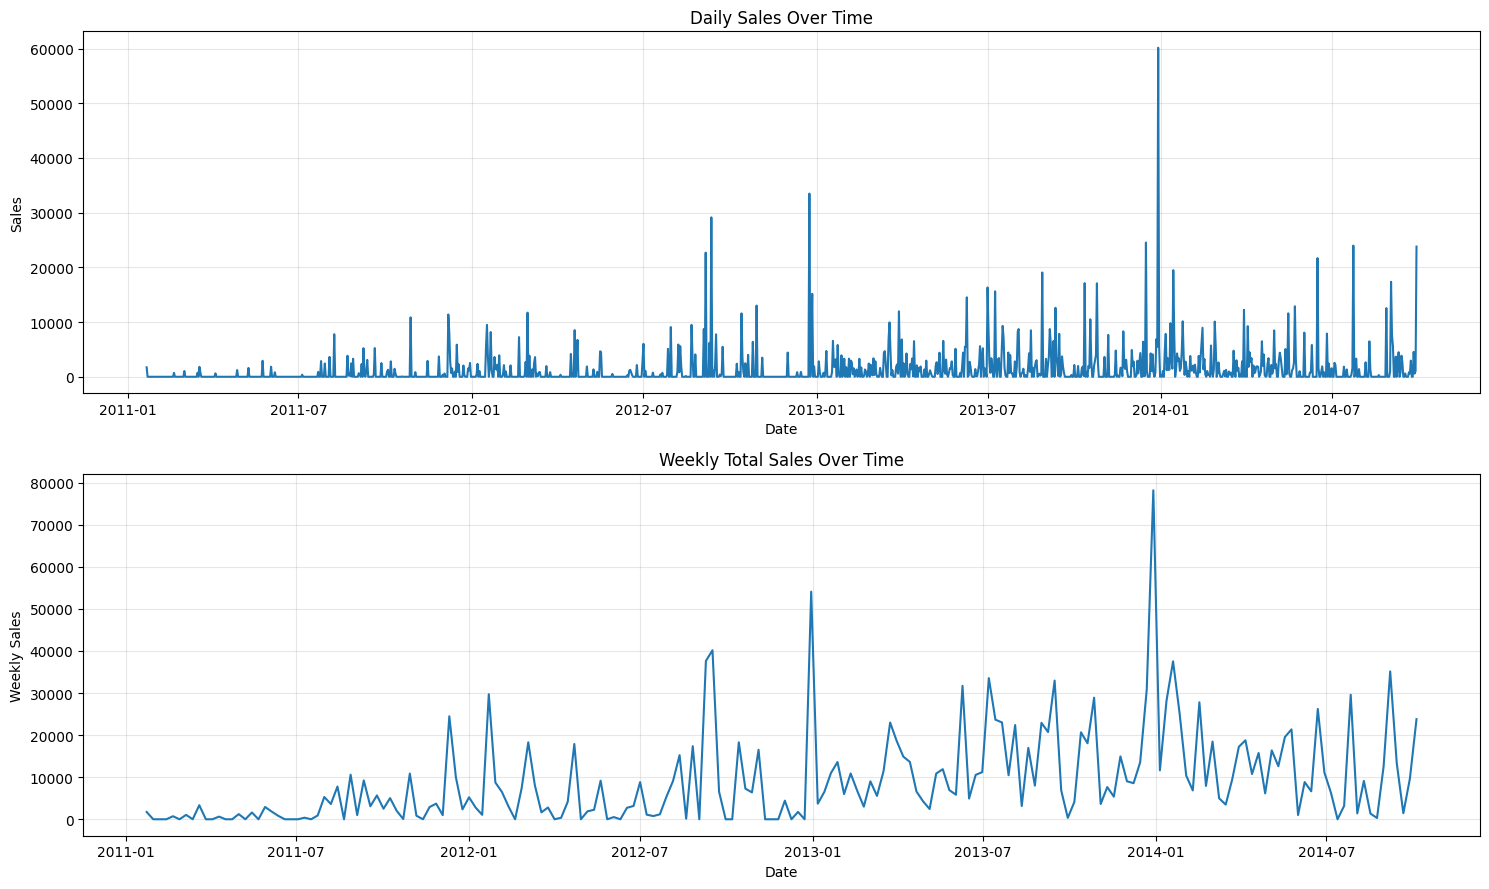

In [ ]:
# cell 6: Plot daily sales and weekly aggregated sales to inspect trends and spikes.

import matplotlib.pyplot as plt

weekly_sales_complete = daily_sales_complete.resample("W").sum()

fig, axes = plt.subplots(2, 1, figsize=(15, 9))

axes[0].plot(daily_sales_complete.index, daily_sales_complete.values)
axes[0].set_title("Daily Sales Over Time")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Sales")
axes[0].grid(True, alpha=0.3)

axes[1].plot(weekly_sales_complete.index, weekly_sales_complete.values)
axes[1].set_title("Weekly Total Sales Over Time")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Weekly Sales")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# cell 7: Compare yearly sales activity and weekday-level patterns.

yearly_summary = daily_sales_complete.groupby(
    daily_sales_complete.index.year
).agg(
    Total_Sales="sum",
    Average_Daily_Sales="mean",
    Days_With_Sales=lambda x: (x > 0).sum(),
    Zero_Sales_Days=lambda x: (x == 0).sum()
)

weekday_summary = daily_sales_complete.groupby(
    daily_sales_complete.index.day_name()
).agg(
    Average_Sales="mean",
    Total_Sales="sum",
    Days_With_Sales=lambda x: (x > 0).sum(),
    Zero_Sales_Days=lambda x: (x == 0).sum()
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_summary = weekday_summary.reindex(weekday_order)

print("Year-wise sales activity:")
display(yearly_summary.round(2))

print("\nWeekday sales patterns:")
display(weekday_summary.round(2))

Year-wise sales activity:


,Total_Sales,Average_Daily_Sales,Days_With_Sales,Zero_Sales_Days
OrderDate,,,,
2011,134382.86,389.52,60,285
2012,384327.03,1050.07,96,270
2013,738726.98,2023.91,220,145
2014,525710.84,1932.76,157,115



Weekday sales patterns:


,Average_Sales,Total_Sales,Days_With_Sales,Zero_Sales_Days
OrderDate,,,,
Monday,1552.39,299611.31,67,126
Tuesday,1241.19,238308.46,73,119
Wednesday,1438.37,276166.87,89,103
Thursday,1262.11,242325.59,74,118
Friday,1407.37,271621.89,81,112
Saturday,1071.68,206834.54,82,111
Sunday,1286.42,248279.05,67,126


First 12 monthly records:


,Total_Sales,Average_Daily_Sales,Days_With_Sales,Zero_Sales_Days
OrderDate,,,,
2011-01-01,1734.95,157.72,1,10
2011-02-01,723.95,25.86,1,27
2011-03-01,4388.95,141.58,4,27
2011-04-01,1852.15,61.74,2,28
2011-05-01,4539.78,146.44,2,29
2011-06-01,2653.82,88.46,2,28
2011-07-01,6576.99,212.16,4,27
2011-08-01,22004.86,709.83,8,23
2011-09-01,21483.90,716.13,10,20



Monthly summary:


,Total_Sales,Average_Daily_Sales,Days_With_Sales,Zero_Sales_Days
count,45.00,45.00,45.00,45.00
mean,39625.50,1304.14,11.84,18.11
std,31218.87,1019.02,7.32,7.27
min,723.95,25.86,1.00,4.00
25%,16411.97,529.42,6.00,11.00
50%,35966.09,1184.64,11.00,19.00
75%,60255.04,1970.30,18.00,24.00
max,141561.60,4566.50,27.00,29.00


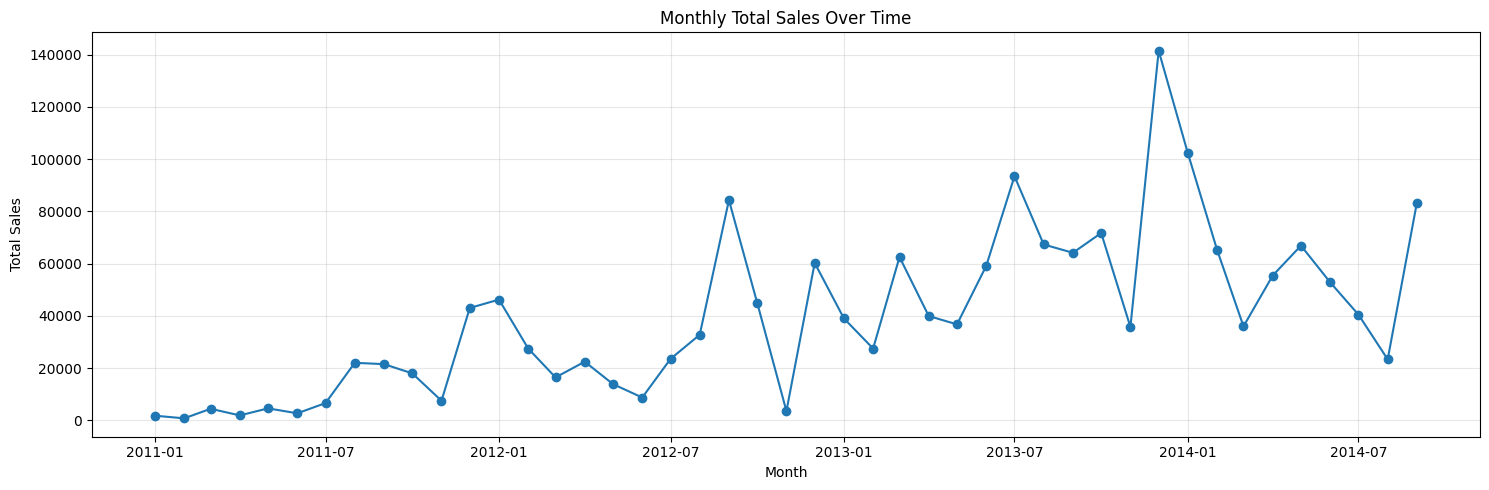

In [ ]:
# cell 8: Aggregate daily sales into monthly totals and inspect monthly patterns.

monthly_sales = daily_sales_complete.resample("MS").sum().to_frame()

monthly_sales["Average_Daily_Sales"] = (
    daily_sales_complete.resample("MS").mean()
)

monthly_sales["Days_With_Sales"] = (
    daily_sales_complete.gt(0).resample("MS").sum()
)

monthly_sales["Zero_Sales_Days"] = (
    daily_sales_complete.eq(0).resample("MS").sum()
)

monthly_sales.columns = [
    "Total_Sales",
    "Average_Daily_Sales",
    "Days_With_Sales",
    "Zero_Sales_Days"
]

print("First 12 monthly records:")
display(monthly_sales.head(12).round(2))

print("\nMonthly summary:")
display(monthly_sales.describe().round(2))

plt.figure(figsize=(15, 5))
plt.plot(monthly_sales.index, monthly_sales["Total_Sales"], marker="o")
plt.title("Monthly Total Sales Over Time")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Sales pattern by calendar month (complete months only):


,Average_Monthly_Sales,Median_Monthly_Sales,Number_Of_Years
Calendar_Month,,,
January,62494.77,46222.42,3
February,30220.69,27462.44,4
March,29823.57,26189.03,4
April,29905.74,31172.69,4
May,30495.87,25279.56,4
June,30817.99,30754.60,4
July,40999.08,31966.78,4
August,36349.58,28029.15,4
September,56653.57,64144.43,3


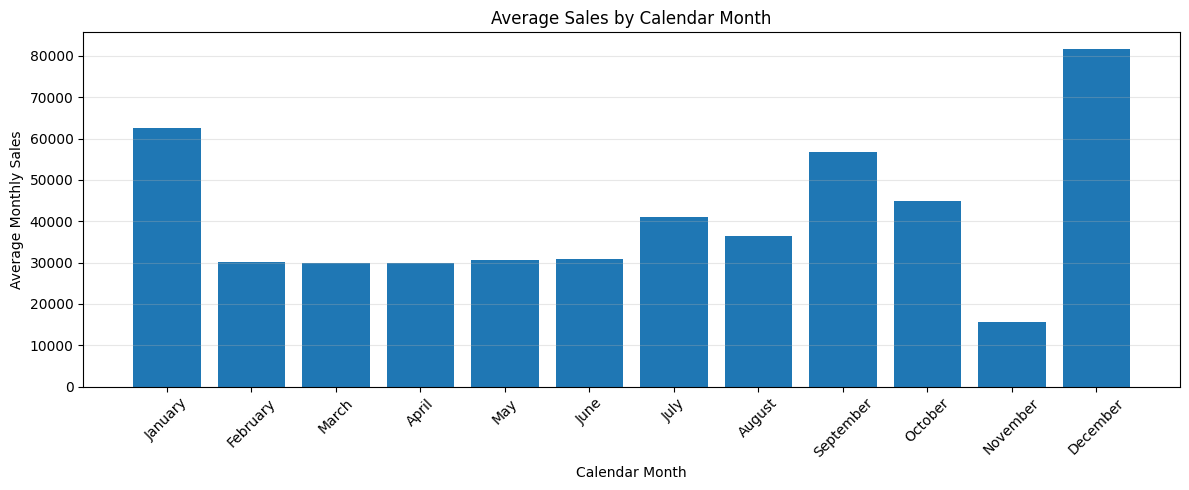

In [ ]:
# cell 9: Compare monthly sales across years while excluding incomplete boundary months.

complete_months = monthly_sales.loc[
    (monthly_sales.index > pd.Timestamp("2011-01-01")) &
    (monthly_sales.index < pd.Timestamp("2014-09-01"))
].copy()

month_pattern = complete_months.groupby(
    complete_months.index.month
).agg(
    Average_Monthly_Sales=("Total_Sales", "mean"),
    Median_Monthly_Sales=("Total_Sales", "median"),
    Number_Of_Years=("Total_Sales", "count")
)

month_pattern.index = month_pattern.index.map(
    lambda month: pd.Timestamp(2000, month, 1).strftime("%B")
)
month_pattern.index.name = "Calendar_Month"

print("Sales pattern by calendar month (complete months only):")
display(month_pattern.round(2))

plt.figure(figsize=(12, 5))
plt.bar(month_pattern.index, month_pattern["Average_Monthly_Sales"])
plt.title("Average Sales by Calendar Month")
plt.xlabel("Calendar Month")
plt.ylabel("Average Monthly Sales")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# cell 10: Compare monthly sales across individual years to check whether seasonal patterns repeat.

monthly_sales_by_year = complete_months.copy()

monthly_sales_by_year["Year"] = monthly_sales_by_year.index.year
monthly_sales_by_year["Month"] = monthly_sales_by_year.index.strftime("%B")

monthly_comparison = monthly_sales_by_year.pivot(
    index="Month",
    columns="Year",
    values="Total_Sales"
)

month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

monthly_comparison = monthly_comparison.reindex(month_order)

print("Monthly sales comparison by year:")
display(monthly_comparison.round(2))

Monthly sales comparison by year:


Year,2011,2012,2013,2014
Month,,,,
January,NaN,46222.42,39009.13,102252.76
February,723.95,27467.88,27457.00,65233.94
March,4388.95,16411.97,62527.27,35966.09
April,1852.15,22424.47,39920.90,55425.42
May,4539.78,13835.20,36723.91,66884.59
June,2653.82,8693.00,59108.95,52816.20
July,6576.99,23487.78,93485.79,40445.78
August,22004.86,32744.54,67335.14,23313.76
September,21483.90,84332.37,64144.43,NaN


In [ ]:
# cell 11: Inspect the largest daily sales values and quantify the upper tail.

print("Daily sales percentiles:")
display(
    daily_sales_complete.quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 1.00]
    ).to_frame(name="Sales")
)

print("\nTop 15 daily sales values:")
display(
    daily_sales_complete
    .sort_values(ascending=False)
    .head(15)
    .to_frame(name="Sales")
)

Daily sales percentiles:


,Sales
0.50,0.000000
0.75,1255.241125
0.90,3841.932000
0.95,6537.064125
0.99,15991.362882
1.00,60133.428600



Top 15 daily sales values:


,Sales
OrderDate,
2013-12-29,60133.4286
2012-12-24,33479.9500
2012-09-11,29134.8526
2013-12-16,24532.4350
2014-07-24,23973.4880
2014-09-29,23799.1601
2012-09-05,22685.0400
2014-06-16,21685.5500
2014-01-14,19486.2600


In [ ]:
# Data validation: dates, duplicates, invalid values, zero-fill, and daily aggregation checks.
import numpy as np
raw_dates = pd.to_datetime(df["OrderDate"], utc=True).dt.tz_localize(None).dt.normalize()

print("Unparseable dates:", int(raw_dates.isna().sum()))
print("Fully duplicated rows:", int(df.duplicated().sum()))
print("Duplicate (Order, ProductID) lines:", int(df.duplicated(["Order", "ProductID"]).sum()))
print("Orders spanning more than one date:", int((df.assign(_d=raw_dates).groupby("Order")["_d"].nunique() > 1).sum()))
print("Null Sales values:", int(df["Sales"].isna().sum()))
print("Zero or negative Sales rows:", int((df["Sales"] <= 0).sum()))

assert daily_sales_complete.index.is_monotonic_increasing, "Dates must be sorted"
assert daily_sales_complete.index.is_unique, "Dates must be unique"
assert (daily_sales_complete.index.to_series().diff().dropna() == pd.Timedelta(days=1)).all(), "Index must be a continuous daily calendar"
assert np.isclose(daily_sales_complete.sum(), df["Sales"].sum()), "Aggregation must preserve total sales"
assert (daily_sales_complete >= 0).all() and daily_sales_complete.notna().all()
assert int((daily_sales_complete == 0).sum()) == len(missing_dates), "Zero days must equal the confirmed missing dates"

print("\nTotal sales in raw rows      :", round(float(df["Sales"].sum()), 2))
print("Total sales in daily series  :", round(float(daily_sales_complete.sum()), 2))
print("Zero-sales share of calendar :", round(float((daily_sales_complete == 0).mean()) * 100, 1), "%")
top5 = daily_sales_complete.nlargest(5)
print("Top 5 days = %.1f%% of all sales (genuine spikes are kept, not removed)" % (top5.sum() / daily_sales_complete.sum() * 100))
print("All data-validation checks passed.")

Unparseable dates: 0
Fully duplicated rows: 0
Duplicate (Order, ProductID) lines: 0
Orders spanning more than one date: 0
Null Sales values: 0
Zero or negative Sales rows: 0

Total sales in raw rows      : 1783147.7
Total sales in daily series  : 1783147.7
Zero-sales share of calendar : 60.5 %
Top 5 days = 9.6% of all sales (genuine spikes are kept, not removed)
All data-validation checks passed.


## 2. Chronological Splits and Baseline Forecasts

Reserve the latest 90 days for final evaluation and use earlier chronological data for model development and validation.

In [ ]:
# cell 12: Define a chronological 90-day test period for forecasting evaluation.

forecast_horizon = 90

test_start_date = (
    daily_sales_complete.index.max()
    - pd.Timedelta(days=forecast_horizon - 1)
)

train_data = daily_sales_complete.loc[
    daily_sales_complete.index < test_start_date
].copy()

test_data = daily_sales_complete.loc[
    daily_sales_complete.index >= test_start_date
].copy()

print("Training period:",
      train_data.index.min().date(), "to",
      train_data.index.max().date())

print("Training days:", len(train_data))

print("\nTest period:",
      test_data.index.min().date(), "to",
      test_data.index.max().date())

print("Test days:", len(test_data))

print("\nTraining sales summary:")
display(train_data.describe().to_frame(name="Sales"))

print("\nTest target summary withheld until after model selection.")

Training period: 2011-01-21 to 2014-07-01
Training days: 1258

Test period: 2014-07-02 to 2014-09-29
Test days: 90

Training sales summary:


,Sales
count,1258.000000
mean,1301.729954
std,3371.747727
min,0.000000
25%,0.000000
50%,0.000000
75%,1249.176750
max,60133.428600



Test target summary withheld until after model selection.


## Test-set handling

The prior version scored baselines on the final 90-day period here, before model selection. That analysis is removed from the executable path. The same dates are evaluated only in the closing section. Prior saved outputs exposed this test period, so it is retrospective and not an independent holdout.

In [ ]:
# cell 14: Reserve the last 90 days of training data for chronological validation.

validation_horizon = 90

validation_start_date = (
    train_data.index.max()
    - pd.Timedelta(days=validation_horizon - 1)
)

model_train = train_data.loc[
    train_data.index < validation_start_date
].copy()

validation_data = train_data.loc[
    train_data.index >= validation_start_date
].copy()

print("Model training period:",
      model_train.index.min().date(), "to",
      model_train.index.max().date())
print("Model training days:", len(model_train))

print("\nValidation period:",
      validation_data.index.min().date(), "to",
      validation_data.index.max().date())
print("Validation days:", len(validation_data))

print("\nFinal test period remains:",
      test_data.index.min().date(), "to",
      test_data.index.max().date())
print("Final test days:", len(test_data))

Model training period: 2011-01-21 to 2014-04-02
Model training days: 1168

Validation period: 2014-04-03 to 2014-07-01
Validation days: 90

Final test period remains: 2014-07-02 to 2014-09-29
Final test days: 90


In [ ]:
# cell 15: Compare baseline forecasting methods on the validation period.

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

def calculate_metrics(actual, predicted, training_series):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    actual_total = np.abs(actual).sum()
    wape = (
        np.abs(actual - predicted).sum() / actual_total * 100
        if actual_total != 0 else np.nan
    )

    seasonal_errors = np.abs(
        training_series.iloc[7:].to_numpy()
        - training_series.iloc[:-7].to_numpy()
    )
    mase_scale = seasonal_errors.mean()
    mase = mae / mase_scale if mase_scale != 0 else np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE_percent": wape,
        "MASE": mase
    }

actual = validation_data.to_numpy()
last_value = model_train.iloc[-1]
last_7_values = model_train.iloc[-7:].to_numpy()

baseline_forecasts = {
    "Always Zero": np.zeros(len(validation_data)),
    "Last Value": np.full(len(validation_data), last_value),
    "Weekly Seasonal Naive": np.resize(last_7_values, len(validation_data))
}

results = []

for model_name, predicted in baseline_forecasts.items():
    metrics = calculate_metrics(actual, predicted, model_train)
    results.append({"Model": model_name, **metrics})

validation_baselines = pd.DataFrame(results).sort_values("MAE")

print("Validation period:",
      validation_data.index.min().date(), "to",
      validation_data.index.max().date())

display(validation_baselines.round(3))

Validation period: 2014-04-03 to 2014-07-01


,Model,MAE,RMSE,WAPE_percent,MASE
0,Always Zero,1957.103,3879.302,100.000,1.043
1,Last Value,1957.103,3879.302,100.000,1.043
2,Weekly Seasonal Naive,3511.339,5700.273,179.415,1.871


In [ ]:
# cell 16: Inspect zero-sales frequency and the latest training and validation values.

print("Last 14 days of model training:")
display(model_train.tail(14).to_frame("Sales"))

print("\nLast training sales value:", model_train.iloc[-1])

print("\nModel training:")
print("Total days:", len(model_train))
print("Zero-sales days:", (model_train == 0).sum())
print("Zero-sales percentage:", round((model_train == 0).mean() * 100, 2), "%")

print("\nValidation:")
print("Total days:", len(validation_data))
print("Zero-sales days:", (validation_data == 0).sum())
print("Zero-sales percentage:", round((validation_data == 0).mean() * 100, 2), "%")


Last 14 days of model training:


,Sales
OrderDate,
2014-03-20,643.3665
2014-03-21,0.0000
2014-03-22,3009.2360
2014-03-23,1121.1150
2014-03-24,1653.3000
2014-03-25,0.0000
2014-03-26,520.5600
2014-03-27,0.0000
2014-03-28,2815.1300



Last training sales value: 0.0

Model training:
Total days: 1168
Zero-sales days: 723
Zero-sales percentage: 61.9 %

Validation:
Total days: 90
Zero-sales days: 35
Zero-sales percentage: 38.89 %


In [ ]:
# cell 17: Evaluate a damped-trend ETS model on 30, 60, and 90-day validation horizons.

import numpy as np
import pandas as pd
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Fit the model using only the model training period.
ets_model = ExponentialSmoothing(
    model_train.astype(float),
    trend="add",
    damped_trend=True,
    seasonal=None,
    initialization_method="estimated"
).fit(optimized=True)

# Generate forecasts for the full validation period.
ets_forecast = ets_model.forecast(len(validation_data)).clip(lower=0)

results = []

for horizon in [30, 60, 90]:
    actual = validation_data.iloc[:horizon].to_numpy()
    predicted = ets_forecast.iloc[:horizon].to_numpy()

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    wape = (
        np.abs(actual - predicted).sum() / np.abs(actual).sum() * 100
        if np.abs(actual).sum() != 0 else np.nan
    )

    seasonal_errors = np.abs(
        model_train.iloc[7:].to_numpy()
        - model_train.iloc[:-7].to_numpy()
    )
    mase_scale = seasonal_errors.mean()
    mase = mae / mase_scale if mase_scale != 0 else np.nan

    results.append({
        "Horizon_Days": horizon,
        "Model": "ETS damped trend",
        "MAE": mae,
        "RMSE": rmse,
        "WAPE_percent": wape,
        "MASE": mase
    })

ets_validation_results = pd.DataFrame(results)

print("ETS configuration: additive damped trend, no seasonal component")
print("Training period:",
      model_train.index.min().date(), "to",
      model_train.index.max().date())
print("Validation period:",
      validation_data.index.min().date(), "to",
      validation_data.index.max().date())

display(ets_validation_results.round(3))

ETS configuration: additive damped trend, no seasonal component
Training period: 2011-01-21 to 2014-04-02
Validation period: 2014-04-03 to 2014-07-01


,Horizon_Days,Model,MAE,RMSE,WAPE_percent,MASE
0,30,ETS damped trend,1696.194,2344.929,78.386,0.904
1,60,ETS damped trend,1960.404,2770.624,96.601,1.045
2,90,ETS damped trend,2215.132,3359.683,113.184,1.180


In [ ]:

# cell 18: Compare baseline models and ETS fairly across 30, 60, and 90-day validation horizons.

import numpy as np
import pandas as pd

# Define the baseline forecasts using only the model training period.
last_value = model_train.iloc[-1]
last_7_values = model_train.iloc[-7:].to_numpy()

baseline_forecasts = {
    "Always Zero": np.zeros(len(validation_data)),
    "Last Value": np.full(len(validation_data), last_value),
    "Weekly Seasonal Naive": np.resize(
        last_7_values, len(validation_data)
    )
}

# Evaluate each model on the same initial validation window for each horizon.
comparison_results = []

for horizon in [30, 60, 90]:
    actual_values = validation_data.iloc[:horizon].to_numpy()

    # Evaluate all baseline models.
    for model_name, forecast_values in baseline_forecasts.items():
        predicted_values = forecast_values[:horizon]

        metrics = calculate_metrics(
            actual_values,
            predicted_values,
            model_train
        )

        comparison_results.append({
            "Horizon_Days": horizon,
            "Model": model_name,
            **metrics
        })

    # Evaluate ETS on the exact same validation dates.
    ets_predictions = ets_forecast.iloc[:horizon].to_numpy()

    ets_metrics = calculate_metrics(
        actual_values,
        ets_predictions,
        model_train
    )

    comparison_results.append({
        "Horizon_Days": horizon,
        "Model": "ETS damped trend",
        **ets_metrics
    })

# Display the comparison, ordered by horizon and MAE.
model_comparison = pd.DataFrame(comparison_results)

model_comparison = model_comparison.sort_values(
    ["Horizon_Days", "MAE"]
).reset_index(drop=True)

display(model_comparison.round(3))

# Identify the lowest-MAE model at each horizon.
best_models = (
    model_comparison.loc[
        model_comparison.groupby("Horizon_Days")["MAE"].idxmin(),
        ["Horizon_Days", "Model", "MAE", "WAPE_percent"]
    ]
    .sort_values("Horizon_Days")
    .reset_index(drop=True)
)

print("Lowest-MAE model at each validation horizon:")
display(best_models.round(3))



,Horizon_Days,Model,MAE,RMSE,WAPE_percent,MASE
0,30,ETS damped trend,1696.194,2344.929,78.386,0.904
1,30,Always Zero,2163.889,3190.304,100.000,1.153
2,30,Last Value,2163.889,3190.304,100.000,1.153
3,30,Weekly Seasonal Naive,3064.239,4664.735,141.608,1.633
4,60,ETS damped trend,1960.404,2770.624,96.601,1.045
5,60,Always Zero,2029.377,3429.091,100.000,1.081
6,60,Last Value,2029.377,3429.091,100.000,1.081
7,60,Weekly Seasonal Naive,3424.516,5287.322,168.747,1.825
8,90,Always Zero,1957.103,3879.302,100.000,1.043
9,90,Last Value,1957.103,3879.302,100.000,1.043


Lowest-MAE model at each validation horizon:


,Horizon_Days,Model,MAE,WAPE_percent
0,30,ETS damped trend,1696.194,78.386
1,60,ETS damped trend,1960.404,96.601
2,90,Always Zero,1957.103,100.000


In [ ]:
# cell 19: Train Ridge regression with calendar and lag features, then evaluate 30, 60, and 90-day forecasts.

import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# Create features using only sales observed before the forecast date.
def create_sales_features(history, forecast_date):
    return {
        "lag_1": history.iloc[-1],
        "lag_7": history.iloc[-7],
        "lag_14": history.iloc[-14],
        "lag_28": history.iloc[-28],
        "rolling_mean_7": history.iloc[-7:].mean(),
        "rolling_mean_28": history.iloc[-28:].mean(),
        "day_of_week": forecast_date.dayofweek,
        "day_of_month": forecast_date.day,
        "month": forecast_date.month,
        "day_of_year": forecast_date.dayofyear,
        "week_sin": np.sin(2 * np.pi * forecast_date.dayofweek / 7),
        "week_cos": np.cos(2 * np.pi * forecast_date.dayofweek / 7),
        "year_sin": np.sin(2 * np.pi * forecast_date.dayofyear / 365.25),
        "year_cos": np.cos(2 * np.pi * forecast_date.dayofyear / 365.25)
    }

# Build supervised training data from the model training period only.
feature_rows = []
target_values = []

for i in range(28, len(model_train)):
    history = model_train.iloc[:i]
    forecast_date = model_train.index[i]

    feature_rows.append(
        create_sales_features(history, forecast_date)
    )
    target_values.append(model_train.iloc[i])

X_train_ridge = pd.DataFrame(feature_rows)
y_train_ridge = np.array(target_values)

# Scale the features and train Ridge regression.
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

ridge_model.fit(X_train_ridge, y_train_ridge)

print("Ridge model training completed.")
print("Training examples:", len(X_train_ridge))
print("Number of features:", X_train_ridge.shape[1])
print("Features:", X_train_ridge.columns.tolist())

# Generate recursive forecasts without using actual validation sales.
ridge_forecast = []

forecast_history = model_train.copy()

for forecast_date in validation_data.index:
    features = pd.DataFrame([
        create_sales_features(forecast_history, forecast_date)
    ])

    predicted_sales = ridge_model.predict(features)[0]
    predicted_sales = max(0, predicted_sales)

    ridge_forecast.append(predicted_sales)

    # Add the prediction, not the actual validation sales, to future history.
    forecast_history = pd.concat([
        forecast_history,
        pd.Series([predicted_sales], index=[forecast_date])
    ])

ridge_forecast = pd.Series(
    ridge_forecast,
    index=validation_data.index,
    name="Ridge_Forecast"
)

# Evaluate the same 30, 60, and 90-day horizons.
ridge_results = []

for horizon in [30, 60, 90]:
    actual = validation_data.iloc[:horizon].to_numpy()
    predicted = ridge_forecast.iloc[:horizon].to_numpy()

    metrics = calculate_metrics(
        actual,
        predicted,
        model_train
    )

    ridge_results.append({
        "Horizon_Days": horizon,
        "Model": "Ridge Regression",
        **metrics
    })

ridge_validation_results = pd.DataFrame(ridge_results)

print("\nRidge Regression Validation Results:")
display(ridge_validation_results.round(3))

Ridge model training completed.
Training examples: 1140
Number of features: 14
Features: ['lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'day_of_week', 'day_of_month', 'month', 'day_of_year', 'week_sin', 'week_cos', 'year_sin', 'year_cos']

Ridge Regression Validation Results:


,Horizon_Days,Model,MAE,RMSE,WAPE_percent,MASE
0,30,Ridge Regression,1689.461,2548.752,78.075,0.900
1,60,Ridge Regression,1828.209,2895.240,90.087,0.974
2,90,Ridge Regression,1929.736,3433.273,98.602,1.028


In [ ]:
# cell 20: Compare all baseline models, ETS, and Ridge across 30, 60, and 90-day validation horizons.

all_model_results = []

# Evaluate the baseline models.
for model_name, forecast_values in baseline_forecasts.items():
    for horizon in [30, 60, 90]:
        actual = validation_data.iloc[:horizon].to_numpy()
        predicted = np.asarray(forecast_values)[:horizon]

        metrics = calculate_metrics(actual, predicted, model_train)

        all_model_results.append({
            "Horizon_Days": horizon,
            "Model": model_name,
            **metrics
        })

# Evaluate ETS and Ridge forecasts.
for model_name, forecast_series in [
    ("ETS damped trend", ets_forecast),
    ("Ridge Regression", ridge_forecast)
]:
    for horizon in [30, 60, 90]:
        actual = validation_data.iloc[:horizon].to_numpy()
        predicted = forecast_series.iloc[:horizon].to_numpy()

        metrics = calculate_metrics(actual, predicted, model_train)

        all_model_results.append({
            "Horizon_Days": horizon,
            "Model": model_name,
            **metrics
        })

# Display all models ranked by MAE within each horizon.
all_model_comparison = pd.DataFrame(all_model_results)

all_model_comparison = all_model_comparison.sort_values(
    ["Horizon_Days", "MAE"]
).reset_index(drop=True)

print("Complete validation comparison:")
display(all_model_comparison.round(3))

# Identify the lowest-MAE model at each horizon.
best_mae_models = (
    all_model_comparison
    .loc[all_model_comparison.groupby("Horizon_Days")["MAE"].idxmin()]
    .sort_values("Horizon_Days")
    .reset_index(drop=True)
)

print("\nBest model by MAE at each horizon:")
display(best_mae_models.round(3))

Complete validation comparison:


,Horizon_Days,Model,MAE,RMSE,WAPE_percent,MASE
0,30,Ridge Regression,1689.461,2548.752,78.075,0.900
1,30,ETS damped trend,1696.194,2344.929,78.386,0.904
2,30,Always Zero,2163.889,3190.304,100.000,1.153
3,30,Last Value,2163.889,3190.304,100.000,1.153
4,30,Weekly Seasonal Naive,3064.239,4664.735,141.608,1.633
5,60,Ridge Regression,1828.209,2895.240,90.087,0.974
6,60,ETS damped trend,1960.404,2770.624,96.601,1.045
7,60,Always Zero,2029.377,3429.091,100.000,1.081
8,60,Last Value,2029.377,3429.091,100.000,1.081
9,60,Weekly Seasonal Naive,3424.516,5287.322,168.747,1.825



Best model by MAE at each horizon:


,Horizon_Days,Model,MAE,RMSE,WAPE_percent,MASE
0,30,Ridge Regression,1689.461,2548.752,78.075,0.900
1,60,Ridge Regression,1828.209,2895.240,90.087,0.974
2,90,Ridge Regression,1929.736,3433.273,98.602,1.028


The earlier Ridge/ETS test comparison was removed from this position. The unchanged 2014 test window is evaluated after development-set selection in the revised closing section. Prior saved test outputs were already viewed, so the evaluation remains retrospective.

The earlier Ridge-versus-test plot was removed because it preceded model selection. The revised section plots the selected candidate after the development comparison.

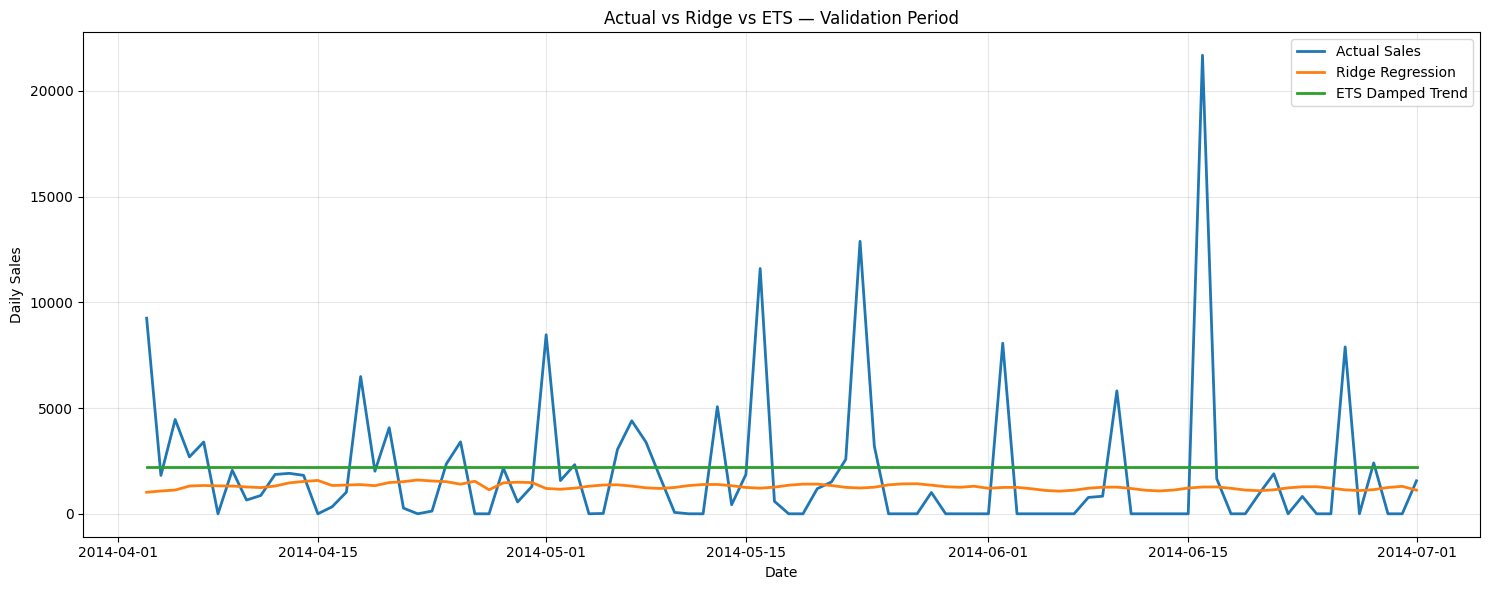

In [ ]:
# cell 23: Compare actual sales with Ridge and ETS forecasts on the validation period.

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    validation_data.index,
    validation_data.to_numpy(),
    label="Actual Sales",
    linewidth=2
)

plt.plot(
    validation_data.index,
    ridge_forecast.to_numpy(),
    label="Ridge Regression",
    linewidth=2
)

plt.plot(
    validation_data.index,
    ets_forecast.to_numpy(),
    label="ETS Damped Trend",
    linewidth=2
)

plt.title("Actual vs Ridge vs ETS — Validation Period")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# cell 24: Measure zero-sales frequency and compare actual sales with validation forecasts.

import numpy as np
import pandas as pd

actual = validation_data.to_numpy(dtype=float)
ridge_values = np.asarray(ridge_forecast, dtype=float)
ets_values = np.asarray(ets_forecast, dtype=float)

diagnostics = pd.DataFrame({
    "Metric": [
        "Total validation days",
        "Zero-sales days",
        "Zero-sales percentage",
        "Days with sales",
        "Average sales on nonzero days",
        "Maximum actual daily sales",
        "Average Ridge forecast",
        "Maximum Ridge forecast",
        "Average ETS forecast",
        "Maximum ETS forecast"
    ],
    "Value": [
        len(actual),
        int(np.sum(actual == 0)),
        round(np.mean(actual == 0) * 100, 2),
        int(np.sum(actual > 0)),
        round(actual[actual > 0].mean(), 2) if np.any(actual > 0) else 0,
        round(actual.max(), 2),
        round(ridge_values.mean(), 2),
        round(ridge_values.max(), 2),
        round(ets_values.mean(), 2),
        round(ets_values.max(), 2)
    ]
})

display(diagnostics)

,Metric,Value
0,Total validation days,90.00
1,Zero-sales days,35.00
2,Zero-sales percentage,38.89
3,Days with sales,55.00
4,Average sales on nonzero days,3202.53
5,Maximum actual daily sales,21685.55
6,Average Ridge forecast,1284.56
7,Maximum Ridge forecast,1599.78
8,Average ETS forecast,2219.28
9,Maximum ETS forecast,2219.28


## 3. Sales Pattern Exploration

Explore weekday effects, sales occurrence, zero-sales runs, and concentration in high-sales days.

In [ ]:
# cell 25: Analyze sales patterns, zero-sales frequency, and peak sales by weekday.

weekday_data = pd.DataFrame({
    "Sales": model_train,
    "Weekday": model_train.index.day_name()
})

weekday_summary = (
    weekday_data.groupby("Weekday")["Sales"]
    .agg(
        Total_Days="count",
        Average_Sales="mean",
        Median_Sales="median",
        Maximum_Sales="max",
        Zero_Sales_Days=lambda x: (x == 0).sum(),
        Nonzero_Day_Average=lambda x: x[x > 0].mean()
    )
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_summary = weekday_summary.reindex(weekday_order)

weekday_summary["Zero_Sales_Percent"] = (
    weekday_summary["Zero_Sales_Days"]
    / weekday_summary["Total_Days"] * 100
).round(2)

display(weekday_summary.round(2))

,Total_Days,Average_Sales,Median_Sales,Maximum_Sales,Zero_Sales_Days,Nonzero_Day_Average,Zero_Sales_Percent
Weekday,,,,,,,
Monday,167,1389.44,0.0,33479.95,114,4378.04,68.26
Tuesday,167,1180.83,0.0,29134.85,105,3180.62,62.87
Wednesday,167,1475.59,0.0,22685.04,93,3330.05,55.69
Thursday,166,972.27,0.0,15159.19,105,2645.85,63.25
Friday,167,1332.09,0.0,17084.00,98,3224.05,58.68
Saturday,167,1084.52,0.0,17117.98,98,2624.86,58.68
Sunday,167,1322.20,0.0,60133.43,110,3873.82,65.87


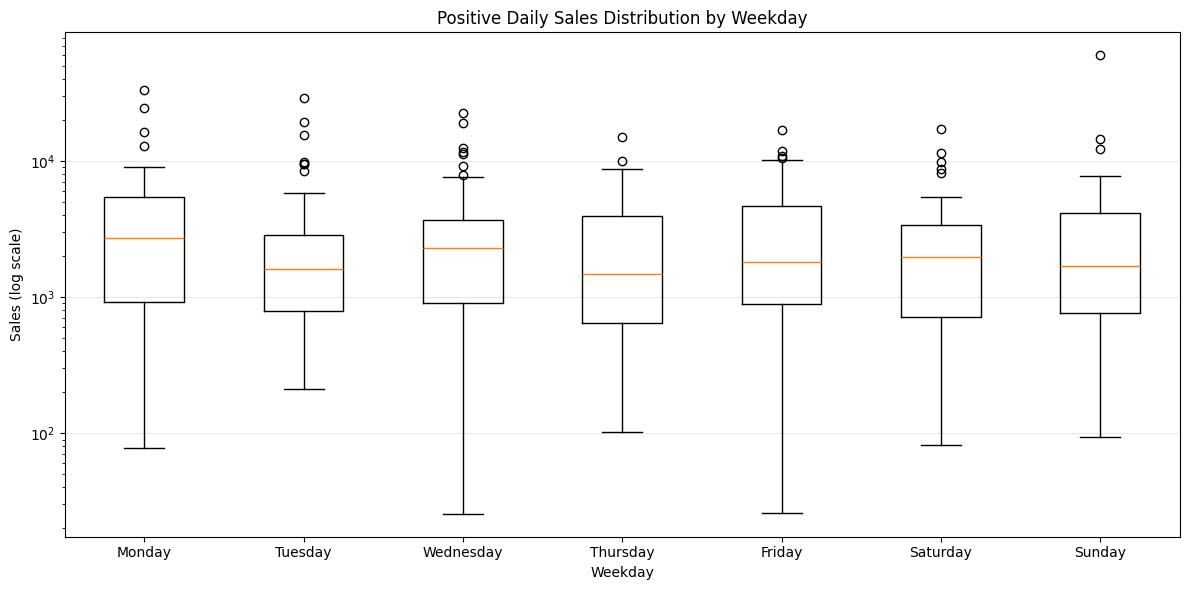

In [ ]:
# cell 26: Compare the distribution of positive sales across weekdays.

import matplotlib.pyplot as plt

positive_sales = weekday_data[weekday_data["Sales"] > 0].copy()

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

sales_by_weekday = [
    positive_sales.loc[
        positive_sales["Weekday"] == day, "Sales"
    ].to_numpy()
    for day in weekday_order
]

plt.figure(figsize=(12, 6))

plt.boxplot(
    sales_by_weekday,
    tick_labels=weekday_order,
    showfliers=True
)

plt.yscale("log")
plt.title("Positive Daily Sales Distribution by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Sales (log scale)")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# cell 27: Estimate weekday sales probabilities using training data and evaluate them on validation data.

train_occurrence = pd.DataFrame({
    "Sales": model_train,
    "Weekday": model_train.index.day_name()
})

validation_occurrence = pd.DataFrame({
    "Actual_Sales": validation_data,
    "Weekday": validation_data.index.day_name()
})

weekday_probability = (
    train_occurrence.assign(Sale_Occurred=(train_occurrence["Sales"] > 0).astype(int))
    .groupby("Weekday")["Sale_Occurred"]
    .mean()
)

validation_occurrence["Predicted_Probability"] = (
    validation_occurrence["Weekday"].map(weekday_probability)
)

validation_occurrence["Sale_Occurred"] = (
    validation_occurrence["Actual_Sales"] > 0
).astype(int)

# Use 0.5 as a simple probability threshold for the initial baseline.
validation_occurrence["Predicted_Sale"] = (
    validation_occurrence["Predicted_Probability"] >= 0.5
).astype(int)

occurrence_accuracy = (
    validation_occurrence["Predicted_Sale"]
    == validation_occurrence["Sale_Occurred"]
).mean()

print("Weekday sales probabilities:")
display((weekday_probability * 100).round(2).rename("Sales_Occurrence_Percent").to_frame())

print(f"Validation occurrence accuracy: {occurrence_accuracy * 100:.2f}%")

Weekday sales probabilities:


,Sales_Occurrence_Percent
Weekday,
Friday,41.32
Monday,31.74
Saturday,41.32
Sunday,34.13
Thursday,36.75
Tuesday,37.13
Wednesday,44.31


Validation occurrence accuracy: 38.89%


In [ ]:
# cell 28: Compare sales-occurrence prediction metrics across probability thresholds.

threshold_results = []

actual = validation_occurrence["Sale_Occurred"].to_numpy()
probabilities = validation_occurrence["Predicted_Probability"].to_numpy()

for threshold in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    predicted = (probabilities >= threshold).astype(int)

    tp = int(((actual == 1) & (predicted == 1)).sum())
    tn = int(((actual == 0) & (predicted == 0)).sum())
    fp = int(((actual == 0) & (predicted == 1)).sum())
    fn = int(((actual == 1) & (predicted == 0)).sum())

    accuracy = (tp + tn) / len(actual)
    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0
    )
    specificity = tn / (tn + fp) if (tn + fp) else 0
    balanced_accuracy = (recall + specificity) / 2

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy_Percent": round(accuracy * 100, 2),
        "Precision_Percent": round(precision * 100, 2),
        "Recall_Percent": round(recall * 100, 2),
        "F1_Score": round(f1, 3),
        "Balanced_Accuracy_Percent": round(balanced_accuracy * 100, 2),
        "Predicted_Sales_Days": int(predicted.sum())
    })

threshold_comparison = pd.DataFrame(threshold_results)

display(threshold_comparison)

,Threshold,Accuracy_Percent,Precision_Percent,Recall_Percent,F1_Score,Balanced_Accuracy_Percent,Predicted_Sales_Days
0,0.25,61.11,61.11,100.00,0.759,50.00,90
1,0.30,61.11,61.11,100.00,0.759,50.00,90
2,0.35,61.11,65.62,76.36,0.706,56.75,64
3,0.40,54.44,68.42,47.27,0.559,56.49,38
4,0.45,38.89,0.00,0.00,0.000,50.00,0
5,0.50,38.89,0.00,0.00,0.000,50.00,0


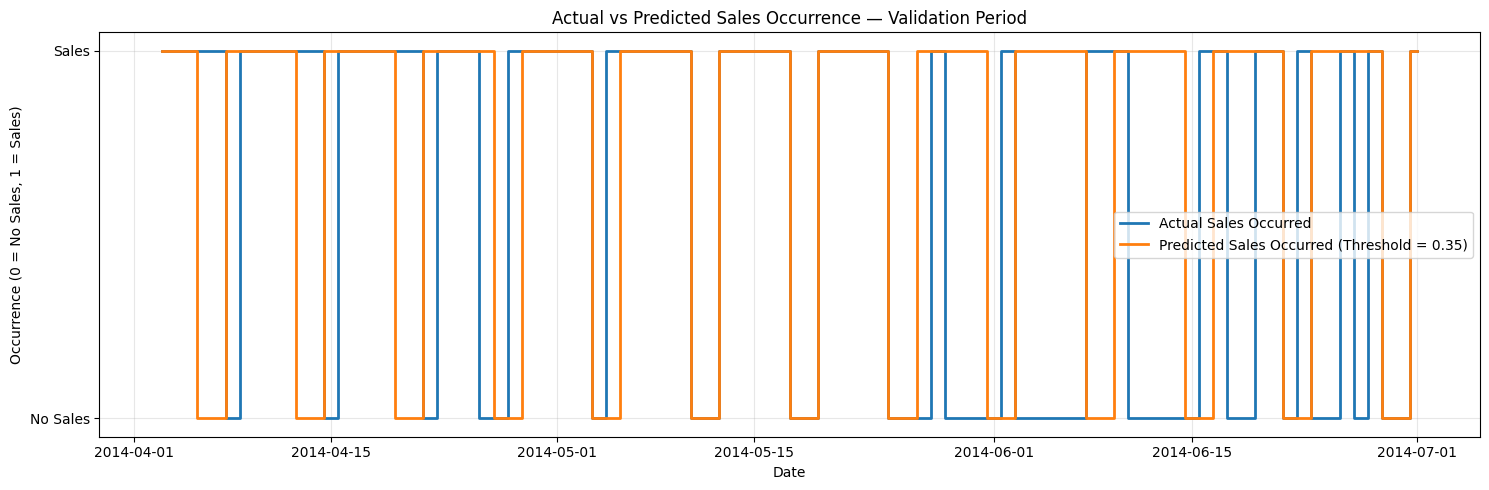

In [ ]:
# cell 29: Visualize actual versus predicted sales occurrence at a 0.35 threshold.

import matplotlib.pyplot as plt

threshold = 0.35

actual_occurrence = validation_occurrence["Sale_Occurred"]
predicted_occurrence = (
    validation_occurrence["Predicted_Probability"] >= threshold
).astype(int)

plt.figure(figsize=(15, 5))

plt.step(
    validation_occurrence.index,
    actual_occurrence,
    where="mid",
    label="Actual Sales Occurred",
    linewidth=2
)

plt.step(
    validation_occurrence.index,
    predicted_occurrence,
    where="mid",
    label="Predicted Sales Occurred (Threshold = 0.35)",
    linewidth=2
)

plt.title("Actual vs Predicted Sales Occurrence — Validation Period")
plt.xlabel("Date")
plt.ylabel("Occurrence (0 = No Sales, 1 = Sales)")
plt.yticks([0, 1], ["No Sales", "Sales"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# cell 30: Calculate the confusion matrix for sales occurrence predictions.

from sklearn.metrics import confusion_matrix, classification_report

threshold = 0.35

actual_occurrence = validation_occurrence["Sale_Occurred"].to_numpy()

predicted_occurrence = (
    validation_occurrence["Predicted_Probability"].to_numpy() >= threshold
).astype(int)

cm = confusion_matrix(
    actual_occurrence,
    predicted_occurrence,
    labels=[0, 1]
)

confusion_matrix_table = pd.DataFrame(
    cm,
    index=["Actual No Sales", "Actual Sales"],
    columns=["Predicted No Sales", "Predicted Sales"]
)

print("Confusion Matrix:")
display(confusion_matrix_table)

print("\nClassification Report:")
print(
    classification_report(
        actual_occurrence,
        predicted_occurrence,
        labels=[0, 1],
        target_names=["No Sales", "Sales"],
        zero_division=0
    )
)

Confusion Matrix:


,Predicted No Sales,Predicted Sales
Actual No Sales,13,22
Actual Sales,13,42



Classification Report:
              precision    recall  f1-score   support

    No Sales       0.50      0.37      0.43        35
       Sales       0.66      0.76      0.71        55

    accuracy                           0.61        90
   macro avg       0.58      0.57      0.57        90
weighted avg       0.60      0.61      0.60        90



## 4. Forecast Error Analysis

Inspect residuals, large forecast errors, and patterns the early candidate models fail to capture.

In [ ]:
# cell 31: Analyze Ridge Regression forecast errors on the validation period.

ridge_actual = validation_data.to_numpy(dtype=float)
ridge_predictions = np.asarray(ridge_forecast, dtype=float)

ridge_residuals = ridge_actual - ridge_predictions

residual_summary = pd.DataFrame({
    "Metric": [
        "Mean Error (Actual - Predicted)",
        "Mean Absolute Error",
        "Root Mean Squared Error",
        "Largest Underprediction",
        "Largest Overprediction",
        "Percentage of Days Underpredicted",
        "Percentage of Days Overpredicted"
    ],
    "Value": [
        ridge_residuals.mean(),
        np.mean(np.abs(ridge_residuals)),
        np.sqrt(np.mean(ridge_residuals ** 2)),
        ridge_residuals.max(),
        ridge_residuals.min(),
        np.mean(ridge_residuals > 0) * 100,
        np.mean(ridge_residuals < 0) * 100
    ]
})

residual_summary["Value"] = residual_summary["Value"].round(2)

display(residual_summary)

,Metric,Value
0,Mean Error (Actual - Predicted),672.55
1,Mean Absolute Error,1929.74
2,Root Mean Squared Error,3433.27
3,Largest Underprediction,20418.98
4,Largest Overprediction,-1599.78
5,Percentage of Days Underpredicted,41.11
6,Percentage of Days Overpredicted,58.89


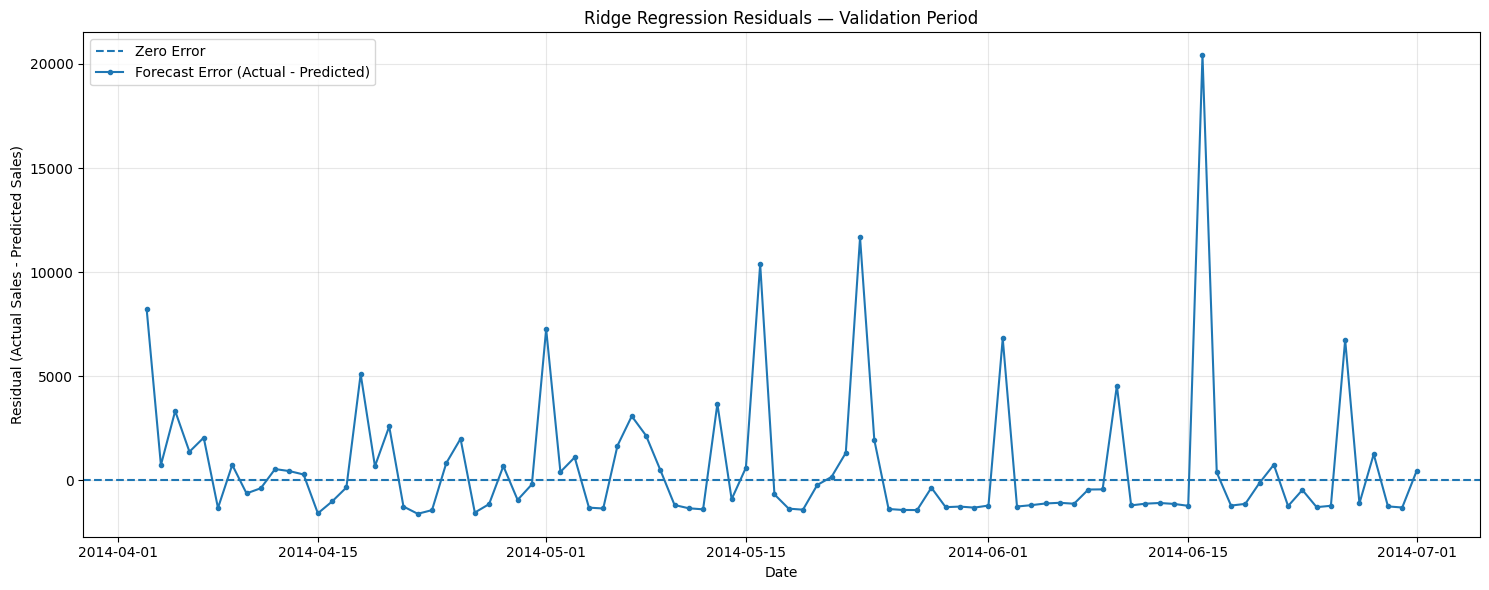

In [ ]:
# cell 32: Plot Ridge Regression residuals over time on the validation period.

import matplotlib.pyplot as plt

ridge_actual = validation_data.to_numpy(dtype=float)
ridge_predictions = np.asarray(ridge_forecast, dtype=float)
ridge_residuals = ridge_actual - ridge_predictions

plt.figure(figsize=(15, 6))

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1.5,
    label="Zero Error"
)

plt.plot(
    validation_data.index,
    ridge_residuals,
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="Forecast Error (Actual - Predicted)"
)

plt.title("Ridge Regression Residuals — Validation Period")
plt.xlabel("Date")
plt.ylabel("Residual (Actual Sales - Predicted Sales)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

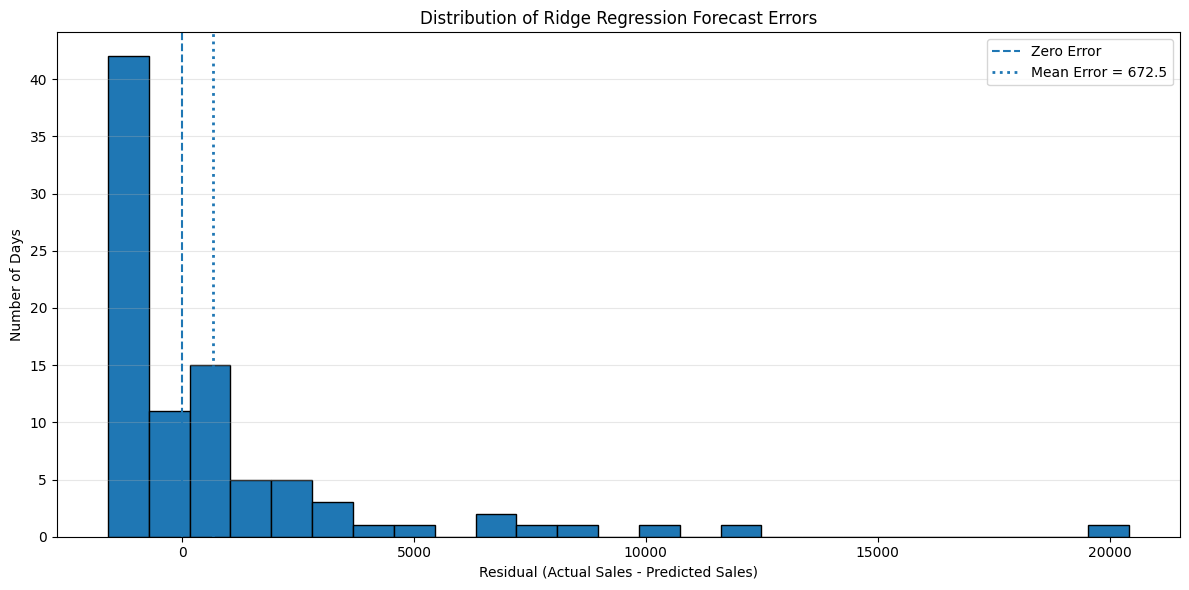

In [ ]:
# cell 33: Visualize the distribution of Ridge Regression residuals on validation data.

import matplotlib.pyplot as plt

ridge_residuals = (
    validation_data.to_numpy(dtype=float)
    - np.asarray(ridge_forecast, dtype=float)
)

plt.figure(figsize=(12, 6))

plt.hist(
    ridge_residuals,
    bins=25,
    edgecolor="black"
)

plt.axvline(
    x=0,
    linestyle="--",
    linewidth=1.5,
    label="Zero Error"
)

plt.axvline(
    x=ridge_residuals.mean(),
    linestyle=":",
    linewidth=2,
    label=f"Mean Error = {ridge_residuals.mean():.1f}"
)

plt.title("Distribution of Ridge Regression Forecast Errors")
plt.xlabel("Residual (Actual Sales - Predicted Sales)")
plt.ylabel("Number of Days")
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# cell 34: Identify the ten largest absolute Ridge Regression forecast errors.

error_analysis = pd.DataFrame({
    "Actual_Sales": validation_data.to_numpy(dtype=float),
    "Predicted_Sales": np.asarray(ridge_forecast, dtype=float)
}, index=validation_data.index)

error_analysis["Residual"] = (
    error_analysis["Actual_Sales"] - error_analysis["Predicted_Sales"]
)

error_analysis["Absolute_Error"] = error_analysis["Residual"].abs()

error_analysis["Error_Type"] = np.where(
    error_analysis["Residual"] > 0,
    "Underprediction",
    np.where(
        error_analysis["Residual"] < 0,
        "Overprediction",
        "Exact Prediction"
    )
)

largest_errors = (
    error_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
)

display(largest_errors.round(2))

,Actual_Sales,Predicted_Sales,Residual,Absolute_Error,Error_Type
OrderDate,,,,,
2014-06-16,21685.55,1266.57,20418.98,20418.98,Underprediction
2014-05-23,12886.57,1218.20,11668.37,11668.37,Underprediction
2014-05-16,11597.72,1211.34,10386.38,10386.38,Underprediction
2014-04-03,9251.91,1017.75,8234.16,8234.16,Underprediction
2014-05-01,8467.28,1197.85,7269.43,7269.43,Underprediction
2014-06-02,8067.35,1246.46,6820.89,6820.89,Underprediction
2014-06-26,7891.62,1132.64,6758.99,6758.99,Underprediction
2014-04-18,6491.28,1380.21,5111.07,5111.07,Underprediction
2014-06-10,5813.62,1261.48,4552.14,4552.14,Underprediction


## 5. Transaction and Customer-Level Analysis

Use transaction-level details to investigate the largest sales spikes and customer concentration.

In [ ]:
# cell 35: Inspect original transactions behind the three largest sales spikes.

spike_dates = pd.to_datetime([
    "2014-06-16",
    "2014-05-23",
    "2014-05-16"
])

df["OrderDate"] = pd.to_datetime(
    df["OrderDate"], utc=True
).dt.tz_localize(None)

df["OrderDay"] = df["OrderDate"].dt.normalize()

spike_transactions = df[
    df["OrderDay"].isin(spike_dates)
].copy()

print("Available source columns:")
print(df.columns.tolist())

print("\nTransaction summary for selected spike dates:")

spike_summary = (
    spike_transactions.groupby("OrderDay")
    .agg(
        Transaction_Rows=("Sales", "size"),
        Total_Sales=("Sales", "sum"),
        Average_Transaction_Sales=("Sales", "mean"),
        Maximum_Transaction_Sales=("Sales", "max")
    )
    .round(2)
)

display(spike_summary)

print("\nSample original transaction records:")
display(
    spike_transactions
    .sort_values(["OrderDay", "Sales"], ascending=[True, False])
    .head(20)
)

Available source columns:
['Order', 'ProductID', 'Quantity', 'Sales', 'Discount', 'COS', 'GP', 'EmployeeID', 'CustomerID', 'OrderDate', 'ShipperID', 'Freight', 'EmployeeName', 'Extension', 'HireDate', 'Office', 'ReportsTo', 'Title', 'YearSalary', 'Customer', 'ContactName', 'Fax', 'Phone', 'PostalCode', 'CountryCode', 'Latitude', 'Longitude', 'City', 'Country', 'ProductName', 'SupplierID', 'CategoryName', 'CategoryDescription', 'OrderDay']

Transaction summary for selected spike dates:


,Transaction_Rows,Total_Sales,Average_Transaction_Sales,Maximum_Transaction_Sales
OrderDay,,,,
2014-05-16,2,11597.72,5798.86,10652.00
2014-05-23,7,12886.57,1840.94,9170.25
2014-06-16,7,21685.55,3097.94,16628.48



Sample original transaction records:


,Order,ProductID,Quantity,Sales,Discount,COS,GP,EmployeeID,CustomerID,OrderDate,...,CountryCode,Latitude,Longitude,City,Country,ProductName,SupplierID,CategoryName,CategoryDescription,OrderDay
1886,10897,29,80,10652.000,0.000,9395.0640,1256.9360,9,37,2014-05-16,...,IE,51.912615,-8.322380,Cork,Ireland,Davenport,12,Men´s Footwear,Men Shoes,2014-05-16
1887,10897,30,36,945.720,0.000,834.1250,111.5950,9,37,2014-05-16,...,IE,51.912615,-8.322380,Cork,Ireland,Baby Dark Lounge Suit,13,Babywear,0-3 Years,2014-05-16
1915,10912,29,60,9170.250,1834.050,6470.5284,2699.7216,3,37,2014-05-23,...,IE,51.912615,-8.322380,Cork,Ireland,Davenport,12,Men´s Footwear,Men Shoes,2014-05-23
1914,10912,11,40,1275.000,255.000,899.6400,375.3600,3,37,2014-05-23,...,IE,51.912615,-8.322380,Cork,Ireland,Desperado Jeans,5,Men´s Clothes,Fashion for Men,2014-05-23
1904,10908,52,14,1150.569,54.789,966.4780,184.0910,7,44,2014-05-23,...,DE,50.073420,8.636150,Frankfurt a.M.,Germany,Small Crocodile Boots,24,Ladies´Footwear,Ladies Shoes,2014-05-23
1903,10908,7,20,847.980,40.380,712.3032,135.6768,7,44,2014-05-23,...,DE,50.073420,8.636150,Frankfurt a.M.,Germany,Conserve Shoes,3,Children´s wear,3-15 Years,2014-05-23
1909,10910,49,10,202.700,0.000,178.7814,23.9186,9,90,2014-05-23,...,FI,60.167876,24.943328,Helsinki,Finland,Finnish Sport Blades,23,Sportwear,Sports…,2014-05-23
1910,10910,61,5,139.150,0.000,126.2627,12.8873,9,90,2014-05-23,...,FI,60.167876,24.943328,Helsinki,Finland,Adihash Running Shoe,29,Sportwear,Sports…,2014-05-23
1908,10910,19,12,100.920,0.000,89.0114,11.9086,9,90,2014-05-23,...,FI,60.167876,24.943328,Helsinki,Finland,Squash Shorts,8,Sportwear,Sports…,2014-05-23
2040,10962,76,44,16628.480,0.000,16153.1819,475.2981,7,63,2014-06-16,...,DE,51.098392,14.520815,Cunewalde,Germany,Minnki Pälsii,23,Womens wear,Fashion for Women,2014-06-16


In [ ]:
# cell 36: Identify which orders contributed most to the three largest sales spikes.

order_contributions = (
    spike_transactions
    .groupby(["OrderDay", "Order"], as_index=False)
    .agg(
        Order_Sales=("Sales", "sum"),
        Product_Lines=("ProductID", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Customer_Count=("CustomerID", "nunique")
    )
)

order_contributions["Daily_Total"] = (
    order_contributions.groupby("OrderDay")["Order_Sales"]
    .transform("sum")
)

order_contributions["Daily_Sales_Share_Percent"] = (
    order_contributions["Order_Sales"]
    / order_contributions["Daily_Total"] * 100
).round(2)

order_contributions = order_contributions.sort_values(
    ["OrderDay", "Order_Sales"],
    ascending=[True, False]
)

display(order_contributions.round(2))

,OrderDay,Order,Order_Sales,Product_Lines,Total_Quantity,Customer_Count,Daily_Total,Daily_Sales_Share_Percent
0,2014-05-16,10897,11597.72,2,116,1,11597.72,100.00
3,2014-05-23,10912,10445.25,2,100,1,12886.57,81.06
1,2014-05-23,10908,1998.55,2,34,1,12886.57,15.51
2,2014-05-23,10910,442.77,3,27,1,12886.57,3.44
5,2014-06-16,10962,21397.63,5,195,1,21685.55,98.67
4,2014-06-16,10960,287.92,2,34,1,21685.55,1.33


In [ ]:
# cell 37: Measure how much each day's sales depend on its largest order.

order_daily_sales = (
    df.groupby(["OrderDay", "Order"])["Sales"]
    .sum()
    .reset_index(name="Order_Sales")
)

daily_order_summary = (
    order_daily_sales.groupby("OrderDay")
    .agg(
        Daily_Total_Sales=("Order_Sales", "sum"),
        Number_of_Orders=("Order", "nunique"),
        Largest_Order_Sales=("Order_Sales", "max")
    )
)

daily_order_summary["Largest_Order_Share_Percent"] = (
    daily_order_summary["Largest_Order_Sales"]
    / daily_order_summary["Daily_Total_Sales"].replace(0, np.nan)
    * 100
)

positive_days = daily_order_summary[
    daily_order_summary["Daily_Total_Sales"] > 0
].copy()

concentration_summary = pd.Series({
    "Positive sales days": len(positive_days),
    "Days with only one order": int(
        (positive_days["Number_of_Orders"] == 1).sum()
    ),
    "Days where largest order contributed at least 80%": int(
        (positive_days["Largest_Order_Share_Percent"] >= 80).sum()
    ),
    "Percentage of positive days with an order contributing at least 80%": round(
        (positive_days["Largest_Order_Share_Percent"] >= 80).mean() * 100, 2
    ),
    "Median largest-order share (%)": round(
        positive_days["Largest_Order_Share_Percent"].median(), 2
    )
})

display(concentration_summary.to_frame(name="Value"))

,Value
Positive sales days,533.00
Days with only one order,327.00
Days where largest order contributed at least 80%,395.00
Percentage of positive days with an order contributing at least 80%,74.11
Median largest-order share (%),100.00


In [ ]:
# cell 38: Analyze repeat customers and their historical sales contributions.

order_level = (
    df.groupby(["Order", "OrderDay", "CustomerID"], as_index=False)
    .agg(Order_Sales=("Sales", "sum"))
    .sort_values(["CustomerID", "OrderDay", "Order"])
)

order_level["Previous_Customer_Orders"] = (
    order_level.groupby("CustomerID").cumcount()
)

order_level["Is_Repeat_Customer"] = (
    order_level["Previous_Customer_Orders"] > 0
)

print("Customer order-history summary:")

customer_summary = pd.Series({
    "Total unique orders": order_level["Order"].nunique(),
    "Orders from repeat customers": int(
        order_level["Is_Repeat_Customer"].sum()
    ),
    "Repeat-customer orders (%)": round(
        order_level["Is_Repeat_Customer"].mean() * 100, 2
    ),
    "Unique customers": order_level["CustomerID"].nunique(),
    "Customers with multiple orders": int(
        (order_level.groupby("CustomerID")["Order"].nunique() > 1).sum()
    )
})

display(customer_summary.to_frame(name="Value"))

print("\nLargest orders and whether the customer had ordered previously:")

display(
    order_level.nlargest(15, "Order_Sales")[
        [
            "OrderDay",
            "Order",
            "CustomerID",
            "Order_Sales",
            "Previous_Customer_Orders",
            "Is_Repeat_Customer"
        ]
    ].round(2)
)

Customer order-history summary:


,Value
Total unique orders,836.00
Orders from repeat customers,746.00
Repeat-customer orders (%),89.23
Unique customers,90.00
Customers with multiple orders,77.00



Largest orders and whether the customer had ordered previously:


,OrderDay,Order,CustomerID,Order_Sales,Previous_Customer_Orders,Is_Repeat_Customer
743,2013-12-29,10991,63,45556.08,20,True
364,2012-12-24,10612,19,33479.95,11,True
713,2013-12-16,10961,62,23801.87,9,True
560,2014-09-29,10808,19,21971.44,42,True
227,2012-09-11,10475,19,21606.37,8,True
714,2014-06-16,10962,63,21397.63,33,True
282,2012-09-05,10530,59,21352.45,2,True
802,2014-07-24,11050,23,21109.55,25,True
25,2013-07-01,10273,63,16323.73,14,True
453,2013-07-09,10701,37,15616.56,27,True


In [ ]:
# cell 39: Analyze customer sales concentration using training-period transactions only.

training_cutoff = model_train.index.max()

training_transactions = df[
    df["OrderDay"] <= training_cutoff
].copy()

customer_sales_summary = (
    training_transactions
    .groupby("CustomerID")
    .agg(
        Total_Sales=("Sales", "sum"),
        Unique_Orders=("Order", "nunique"),
        Transaction_Rows=("Sales", "size"),
        Average_Order_Sales=("Sales", lambda x: x.sum())
    )
)

# Calculate total sales per order before finding the average order value.
training_order_sales = (
    training_transactions
    .groupby(["CustomerID", "Order"])["Sales"]
    .sum()
    .reset_index(name="Order_Sales")
)

average_order_sales = (
    training_order_sales.groupby("CustomerID")["Order_Sales"]
    .mean()
)

customer_sales_summary["Average_Order_Sales"] = average_order_sales
customer_sales_summary["Sales_Share_Percent"] = (
    customer_sales_summary["Total_Sales"]
    / customer_sales_summary["Total_Sales"].sum() * 100
)

customer_sales_summary = customer_sales_summary.sort_values(
    "Total_Sales", ascending=False
)

print("Training cutoff:", training_cutoff.date())
print("Top 15 customers by historical sales:")

display(customer_sales_summary.head(15).round(2))

print("\nShare of training sales contributed by top 10 customers:")

top_10_share = customer_sales_summary.head(10)["Sales_Share_Percent"].sum()

print(f"{top_10_share:.2f}%")

Training cutoff: 2014-04-02
Top 15 customers by historical sales:


,Total_Sales,Unique_Orders,Transaction_Rows,Average_Order_Sales,Sales_Share_Percent
CustomerID,,,,,
63,156745.62,26,78,6028.68,10.73
19,124194.44,37,113,3356.61,8.50
37,95611.03,42,124,2276.45,6.54
32,70394.70,36,103,1955.41,4.82
23,69852.31,24,69,2910.51,4.78
1,67113.59,29,69,2314.26,4.59
80,61461.02,21,63,2926.72,4.21
44,59648.14,23,63,2593.40,4.08
79,46916.67,19,43,2469.30,3.21



Share of training sales contributed by top 10 customers:
54.39%


In [ ]:
# cell 40: Analyze the time gaps between orders for the highest-sales customers.

top_customer_ids = customer_sales_summary.head(10).index

top_customer_orders = (
    training_order_sales[
        training_order_sales["CustomerID"].isin(top_customer_ids)
    ][["CustomerID", "Order"]]
    .merge(
        training_transactions[["Order", "OrderDay"]].drop_duplicates(),
        on="Order",
        how="left"
    )
    .drop_duplicates(["CustomerID", "Order"])
    .sort_values(["CustomerID", "OrderDay"])
)

top_customer_orders["Days_Between_Orders"] = (
    top_customer_orders.groupby("CustomerID")["OrderDay"]
    .diff()
    .dt.days
)

customer_order_frequency = (
    top_customer_orders.groupby("CustomerID")
    .agg(
        Number_of_Orders=("Order", "nunique"),
        Average_Days_Between_Orders=("Days_Between_Orders", "mean"),
        Median_Days_Between_Orders=("Days_Between_Orders", "median"),
        Minimum_Gap_Days=("Days_Between_Orders", "min"),
        Maximum_Gap_Days=("Days_Between_Orders", "max")
    )
    .sort_values("Number_of_Orders", ascending=False)
)

print("Order frequency for the top 10 customers:")
display(customer_order_frequency.round(2))

Order frequency for the top 10 customers:


,Number_of_Orders,Average_Days_Between_Orders,Median_Days_Between_Orders,Minimum_Gap_Days,Maximum_Gap_Days
CustomerID,,,,,
37,42,24.51,16.0,0.0,98.0
19,37,26.33,12.5,1.0,158.0
32,36,26.57,17.0,0.0,113.0
1,29,34.00,8.0,1.0,285.0
63,26,44.32,23.0,0.0,273.0
23,24,40.39,31.0,1.0,128.0
44,23,42.36,34.5,1.0,195.0
80,21,49.75,26.0,5.0,200.0
79,19,46.11,30.5,0.0,229.0


In [ ]:
# cell 41: Measure how much training-period sales comes from the largest sales days.

training_daily_sales = model_train.copy()

total_training_sales = training_daily_sales.sum()

daily_sales_sorted = training_daily_sales.sort_values(ascending=False)

print("Training-period sales concentration:")

for top_n in [5, 10, 20, 30]:
    top_sales = daily_sales_sorted.head(top_n).sum()
    share = (
        top_sales / total_training_sales * 100
        if total_training_sales != 0 else 0
    )

    print(
        f"Top {top_n} sales days: "
        f"{top_sales:,.2f} "
        f"({share:.2f}% of training-period sales)"
    )

print("\nDaily sales distribution:")

display(
    training_daily_sales.describe().to_frame(name="Daily_Sales").round(2)
)

print(
    "\nZero-sales days:",
    int((training_daily_sales == 0).sum())
)

print(
    "Positive-sales days:",
    int((training_daily_sales > 0).sum())
)

Training-period sales concentration:
Top 5 sales days: 169,965.71 (11.63% of training-period sales)
Top 10 sales days: 259,036.04 (17.72% of training-period sales)
Top 20 sales days: 388,837.64 (26.61% of training-period sales)
Top 30 sales days: 487,505.47 (33.36% of training-period sales)

Daily sales distribution:


,Daily_Sales
count,1168.00
mean,1251.23
std,3368.17
min,0.00
25%,0.00
50%,0.00
75%,1093.72
max,60133.43



Zero-sales days: 723
Positive-sales days: 445


## 6. Historical Trend and Seasonality Analysis

Compare monthly, quarterly, yearly, and rolling sales patterns.

In [ ]:
# cell 42: Analyze monthly sales occurrence and sales amounts in the training period.

monthly_analysis = model_train.to_frame(name="Daily_Sales").copy()

monthly_analysis["Month"] = monthly_analysis.index.month

monthly_summary = (
    monthly_analysis.groupby("Month")
    .agg(
        Total_Days=("Daily_Sales", "size"),
        Positive_Sales_Days=(
            "Daily_Sales",
            lambda x: int((x > 0).sum())
        ),
        Zero_Sales_Days=(
            "Daily_Sales",
            lambda x: int((x == 0).sum())
        ),
        Average_Daily_Sales=("Daily_Sales", "mean"),
        Median_Daily_Sales=("Daily_Sales", "median"),
        Total_Sales=("Daily_Sales", "sum")
    )
)

monthly_summary["Positive_Sales_Percent"] = (
    monthly_summary["Positive_Sales_Days"]
    / monthly_summary["Total_Days"] * 100
)

print("Monthly sales patterns during the training period:")
display(monthly_summary.round(2))

Monthly sales patterns during the training period:


,Total_Days,Positive_Sales_Days,Zero_Sales_Days,Average_Daily_Sales,Median_Daily_Sales,Total_Sales,Positive_Sales_Percent
Month,,,,,,,
1,104,57,47,1819.42,710.83,189219.26,54.81
2,113,50,63,1069.76,0.00,120882.78,44.25
3,124,53,71,962.05,0.00,119294.29,42.74
4,92,26,66,703.75,0.00,64744.91,28.26
5,93,27,66,592.46,0.00,55098.90,29.03
6,90,29,61,782.84,0.00,70455.77,32.22
7,93,33,60,1328.50,0.00,123550.55,35.48
8,93,38,55,1312.74,0.00,122084.55,40.86
9,90,38,52,1888.45,0.00,169960.70,42.22


In [ ]:
# cell 43: Compare monthly sales occurrence across years in the training period.

yearly_monthly_data = model_train.to_frame(name="Daily_Sales").copy()

yearly_monthly_data["Year"] = yearly_monthly_data.index.year
yearly_monthly_data["Month"] = yearly_monthly_data.index.month

yearly_monthly_summary = (
    yearly_monthly_data
    .groupby(["Year", "Month"])
    .agg(
        Total_Days=("Daily_Sales", "size"),
        Positive_Sales_Days=(
            "Daily_Sales",
            lambda x: int((x > 0).sum())
        ),
        Average_Daily_Sales=("Daily_Sales", "mean"),
        Total_Sales=("Daily_Sales", "sum")
    )
)

yearly_monthly_summary["Positive_Sales_Percent"] = (
    yearly_monthly_summary["Positive_Sales_Days"]
    / yearly_monthly_summary["Total_Days"] * 100
)

print("Monthly sales patterns by year:")
display(yearly_monthly_summary.round(2))

Monthly sales patterns by year:


Total_Days  Positive_Sales_Days  Average_Daily_Sales  Total_Sales  \
Year Month                                                                      
2011 1              11                    1               157.72      1734.95   
     2              28                    1                25.86       723.95   
     3              31                    4               141.58      4388.95   
     4              30                    2                61.74      1852.15   
     5              31                    2               146.44      4539.78   
     6              30                    2                88.46      2653.82   
     7              31                    4               212.16      6576.99   
     8              31                    8               709.83     22004.86   
     9              30                   10               716.13     21483.90   
     10             31                    7               579.32     17958.84   
     11             30                    3               248.82      7464.58   
     12             31                   16              1387.10     43000.06   
2012 1              31                   14              1491.05     46222.42   
     2              29                    8               947.17     27467.88   
     3              31                   10               529.42     16411.97   
     4              30                    6               747.48     22424.47   
     5              31                    6               446.30     13835.20   
     6              30                    7               289.77      8693.00   
     7              31                    8               757.67     23487.78   
     8              31                    9              1056.28     32744.54   
     9              30                   11              2811.08     84332.37   
     10             31                    9              1450.25     44957.75   
     11             30                    1               116.49      3494.62   
     12             31                    7              1943.71     60255.04   
2013 1              31                   15              1258.36     39009.13   
     2              28                   18               980.61     27457.00   
     3              31                   21              2017.01     62527.27   
     4              30                   17              1330.70     39920.90   
     5              31                   19              1184.64     36723.91   
     6              30                   20              1970.30     59108.95   
     7              31                   21              3015.67     93485.79   
     8              31                   21              2172.10     67335.14   
     9              30                   17              2138.15     64144.43   
     10             31                   16              2314.06     71735.88   
     11             30                   13              1190.57     35716.98   
     12             31                   22              4566.50    141561.60   
2014 1              31                   27              3298.48    102252.76   
     2              28                   23              2329.78     65233.94   
     3              31                   18              1160.20     35966.09   
     4               2                    1               273.70       547.39   

            Positive_Sales_Percent  
Year Month                          
2011 1                        9.09  
     2                        3.57  
     3                       12.90  
     4                        6.67  
     5                        6.45  
     6                        6.67  
     7                       12.90  
     8                       25.81  
     9                       33.33  
     10                      22.58  
     11                      10.00  
     12                      51.61  
2012 1                       45.16  
     2                       27.59  
     3           

In [ ]:
# cell 44: Compare annual sales activity during the training period.

yearly_summary = (
    yearly_monthly_data
    .groupby("Year")
    .agg(
        Total_Days=("Daily_Sales", "size"),
        Positive_Sales_Days=(
            "Daily_Sales",
            lambda x: int((x > 0).sum())
        ),
        Zero_Sales_Days=(
            "Daily_Sales",
            lambda x: int((x == 0).sum())
        ),
        Total_Sales=("Daily_Sales", "sum"),
        Average_Daily_Sales=("Daily_Sales", "mean"),
        Median_Daily_Sales=("Daily_Sales", "median"),
        Maximum_Daily_Sales=("Daily_Sales", "max")
    )
)

yearly_summary["Positive_Sales_Percent"] = (
    yearly_summary["Positive_Sales_Days"]
    / yearly_summary["Total_Days"] * 100
)

print("Annual sales activity during the training period:")
display(yearly_summary.round(2))

Annual sales activity during the training period:


,Total_Days,Positive_Sales_Days,Zero_Sales_Days,Total_Sales,Average_Daily_Sales,Median_Daily_Sales,Maximum_Daily_Sales,Positive_Sales_Percent
Year,,,,,,,,
2011,345,60,285,134382.86,389.52,0.00,11379.29,17.39
2012,366,96,270,384327.03,1050.07,0.00,33479.95,26.23
2013,365,220,145,738726.98,2023.91,514.68,60133.43,60.27
2014,92,69,23,204000.19,2217.39,1062.52,19486.26,75.00


In [ ]:
# cell 45: Analyze quarterly sales activity to investigate the historical trend.

quarterly_data = model_train.to_frame(name="Daily_Sales").copy()

quarterly_data["Quarter"] = quarterly_data.index.to_period("Q")

quarterly_summary = (
    quarterly_data.groupby("Quarter")
    .agg(
        Total_Days=("Daily_Sales", "size"),
        Positive_Sales_Days=(
            "Daily_Sales",
            lambda x: int((x > 0).sum())
        ),
        Total_Sales=("Daily_Sales", "sum"),
        Average_Daily_Sales=("Daily_Sales", "mean"),
        Median_Daily_Sales=("Daily_Sales", "median"),
        Maximum_Daily_Sales=("Daily_Sales", "max")
    )
)

quarterly_summary["Positive_Sales_Percent"] = (
    quarterly_summary["Positive_Sales_Days"]
    / quarterly_summary["Total_Days"] * 100
)

print("Quarterly sales activity during the training period:")
display(quarterly_summary.round(2))

Quarterly sales activity during the training period:


,Total_Days,Positive_Sales_Days,Total_Sales,Average_Daily_Sales,Median_Daily_Sales,Maximum_Daily_Sales,Positive_Sales_Percent
Quarter,,,,,,,
2011Q1,70,6,6847.86,97.83,0.00,1817.20,8.57
2011Q2,91,6,9045.76,99.40,0.00,2923.84,6.59
2011Q3,92,22,50065.76,544.19,0.00,7779.02,23.91
2011Q4,92,26,68423.48,743.73,0.00,11379.29,28.26
2012Q1,91,32,90102.27,990.13,0.00,11719.11,35.16
2012Q2,91,19,44952.68,493.99,0.00,8523.42,20.88
2012Q3,92,28,140564.68,1527.88,0.00,29134.85,30.43
2012Q4,92,17,108707.40,1181.60,0.00,33479.95,18.48
2013Q1,90,54,128993.40,1433.26,465.45,11960.28,60.00


In [ ]:
# cell 46: Compare 30-day and 90-day rolling sales averages over time.

rolling_analysis = model_train.to_frame(name="Daily_Sales").copy()

rolling_analysis["Rolling_30_Day_Average"] = (
    rolling_analysis["Daily_Sales"]
    .rolling(window=30, min_periods=30)
    .mean()
)

rolling_analysis["Rolling_90_Day_Average"] = (
    rolling_analysis["Daily_Sales"]
    .rolling(window=90, min_periods=90)
    .mean()
)

print("Latest rolling averages in the training period:")

display(rolling_analysis.tail(15).round(2))

print("\nOverall rolling-average summary:")

display(
    rolling_analysis[
        ["Rolling_30_Day_Average", "Rolling_90_Day_Average"]
    ]
    .describe()
    .round(2)
)

Latest rolling averages in the training period:


,Daily_Sales,Rolling_30_Day_Average,Rolling_90_Day_Average
OrderDate,,,
2014-03-19,4766.47,1306.61,3005.63
2014-03-20,643.37,1328.06,3012.78
2014-03-21,0.00,1293.05,2965.26
2014-03-22,3009.24,1382.80,2986.98
2014-03-23,1121.12,1406.45,2953.81
2014-03-24,1653.30,1461.56,2962.75
2014-03-25,0.00,1270.91,2962.75
2014-03-26,520.56,1262.79,2960.39
2014-03-27,0.00,1262.79,2883.95



Overall rolling-average summary:


,Rolling_30_Day_Average,Rolling_90_Day_Average
count,1139.00,1079.00
mean,1262.79,1278.60
std,1058.72,849.16
min,12.61,63.79
25%,461.17,576.60
50%,1060.03,1175.41
75%,1809.84,1781.01
max,5816.91,3433.87


In [ ]:
# cell 47: Identify low, medium, and high sales phases using the 30-day rolling average.

phase_analysis = rolling_analysis[
    ["Daily_Sales", "Rolling_30_Day_Average"]
].dropna().copy()

phase_analysis["Sales_Phase"] = pd.cut(
    phase_analysis["Rolling_30_Day_Average"],
    bins=[-float("inf"), 500, 1500, float("inf")],
    labels=["Low", "Medium", "High"]
)

print("Number of days in each sales phase:")

display(
    phase_analysis["Sales_Phase"]
    .value_counts()
    .reindex(["Low", "Medium", "High"])
    .rename("Number_of_Days")
    .to_frame()
)

print("\nSales statistics by phase:")

display(
    phase_analysis.groupby("Sales_Phase", observed=True)
    .agg(
        Days=("Daily_Sales", "count"),
        Average_Daily_Sales=("Daily_Sales", "mean"),
        Median_Daily_Sales=("Daily_Sales", "median"),
        Total_Sales=("Daily_Sales", "sum")
    )
    .round(2)
)

Number of days in each sales phase:


,Number_of_Days
Sales_Phase,
Low,310
Medium,447
High,382



Sales statistics by phase:


,Days,Average_Daily_Sales,Median_Daily_Sales,Total_Sales
Sales_Phase,,,,
Low,310,221.17,0.00,68563.71
Medium,447,1192.86,0.00,533206.68
High,382,2245.89,568.64,857931.71


In [ ]:
# cell 48: Measure zero-sales and positive-sales days in the training period.

zero_sales_days = int((model_train == 0).sum())
positive_sales_days = int((model_train > 0).sum())
total_training_days = len(model_train)

sales_occurrence_summary = pd.DataFrame({
    "Category": ["Zero-sales days", "Positive-sales days"],
    "Days": [zero_sales_days, positive_sales_days],
    "Percentage": [
        zero_sales_days / total_training_days * 100,
        positive_sales_days / total_training_days * 100
    ]
})

print(f"Total training days: {total_training_days}")

display(sales_occurrence_summary.round(2))

Total training days: 1168


,Category,Days,Percentage
0,Zero-sales days,723,61.9
1,Positive-sales days,445,38.1


In [ ]:
# cell 49: Summarize sales amounts on positive-sales days only.

positive_sales = model_train[model_train > 0]

print(f"Positive-sales days: {len(positive_sales)}")

positive_sales_summary = positive_sales.describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).to_frame(name="Sales_Amount")

display(positive_sales_summary.round(2))

print("\nLargest 10 positive-sales days:")

display(
    positive_sales.sort_values(ascending=False)
    .head(10)
    .rename("Daily_Sales")
    .to_frame()
    .round(2)
)

Positive-sales days: 445


,Sales_Amount
count,445.00
mean,3284.13
std,4809.00
min,25.60
25%,781.16
50%,1852.22
75%,3861.93
90%,7768.54
95%,10131.04
99%,21277.58



Largest 10 positive-sales days:


,Daily_Sales
OrderDate,
2013-12-29,60133.43
2012-12-24,33479.95
2012-09-11,29134.85
2013-12-16,24532.44
2012-09-05,22685.04
2014-01-14,19486.26
2013-08-28,19058.36
2013-10-12,17117.98
2013-10-25,17084.00


In [ ]:
# cell 50: Measure how much the top 10 positive-sales days contribute to total training sales.

total_training_sales = model_train.sum()

top_10_sales = positive_sales.nlargest(10)
top_10_sales_total = top_10_sales.sum()

top_10_contribution = (
    top_10_sales_total / total_training_sales * 100
    if total_training_sales != 0 else 0
)

print(f"Total training sales: {total_training_sales:.2f}")
print(f"Top 10 days' combined sales: {top_10_sales_total:.2f}")
print(f"Top 10 days' contribution: {top_10_contribution:.2f}%")

print("\nContribution by the top 10 days:")

display(
    top_10_sales.rename("Daily_Sales")
    .to_frame()
    .assign(
        Percentage_of_Training_Sales=lambda df:
            df["Daily_Sales"] / total_training_sales * 100
    )
    .round(2)
)

Total training sales: 1461437.06
Top 10 days' combined sales: 259036.04
Top 10 days' contribution: 17.72%

Contribution by the top 10 days:


,Daily_Sales,Percentage_of_Training_Sales
OrderDate,,
2013-12-29,60133.43,4.11
2012-12-24,33479.95,2.29
2012-09-11,29134.85,1.99
2013-12-16,24532.44,1.68
2012-09-05,22685.04,1.55
2014-01-14,19486.26,1.33
2013-08-28,19058.36,1.30
2013-10-12,17117.98,1.17
2013-10-25,17084.00,1.17


In [ ]:
# cell 51: Measure the sales contribution of the top 10 percent of positive-sales days.

number_of_top_days = max(1, int(len(positive_sales) * 0.10))

top_10_percent_days = positive_sales.nlargest(number_of_top_days)

top_days_sales = top_10_percent_days.sum()
top_days_contribution = (
    top_days_sales / model_train.sum() * 100
    if model_train.sum() != 0 else 0
)

print(f"Positive-sales days: {len(positive_sales)}")
print(f"Top 10 percent day count: {number_of_top_days}")
print(f"Sales from these days: {top_days_sales:.2f}")
print(f"Contribution to total training sales: {top_days_contribution:.2f}%")

Positive-sales days: 445
Top 10 percent day count: 44
Sales from these days: 604649.87
Contribution to total training sales: 41.37%


In [ ]:
# cell 52: Examine the relationship between daily sales and lagged sales values.

lag_analysis = model_train.to_frame(name="Daily_Sales").copy()

lag_analysis["Sales_1_Day_Ago"] = model_train.shift(1)
lag_analysis["Sales_7_Days_Ago"] = model_train.shift(7)
lag_analysis["Sales_14_Days_Ago"] = model_train.shift(14)

print("Correlation with current daily sales:")

display(
    lag_analysis.corr(numeric_only=True)["Daily_Sales"]
    .drop("Daily_Sales")
    .rename("Correlation")
    .to_frame()
    .round(3)
)

Correlation with current daily sales:


,Correlation
Sales_1_Day_Ago,0.105
Sales_7_Days_Ago,0.070
Sales_14_Days_Ago,0.073


In [ ]:
# cell 53: Compare current sales occurrence based on whether the previous day had sales.

occurrence_analysis = pd.DataFrame({
    "Current_Sales": model_train,
    "Previous_Day_Sales": model_train.shift(1)
}).dropna()

occurrence_analysis["Previous_Day_Had_Sales"] = (
    occurrence_analysis["Previous_Day_Sales"] > 0
)

occurrence_analysis["Current_Day_Had_Sales"] = (
    occurrence_analysis["Current_Sales"] > 0
)

occurrence_summary = (
    occurrence_analysis
    .groupby("Previous_Day_Had_Sales")
    .agg(
        Total_Days=("Current_Day_Had_Sales", "count"),
        Positive_Sales_Days=("Current_Day_Had_Sales", "sum"),
        Positive_Sales_Rate=("Current_Day_Had_Sales", "mean")
    )
)

occurrence_summary["Positive_Sales_Rate"] *= 100

print("Current-day sales occurrence by previous-day sales status:")

display(occurrence_summary.round(2))

Current-day sales occurrence by previous-day sales status:


,Total_Days,Positive_Sales_Days,Positive_Sales_Rate
Previous_Day_Had_Sales,,,
False,722,195,27.01
True,445,249,55.96


In [ ]:
# cell 54: Compare current-day sales amounts based on previous-day sales occurrence.

amount_analysis = pd.DataFrame({
    "Current_Day_Sales": model_train,
    "Previous_Day_Sales": model_train.shift(1)
}).dropna()

amount_analysis["Previous_Day_Had_Sales"] = (
    amount_analysis["Previous_Day_Sales"] > 0
)

amount_summary = (
    amount_analysis
    .groupby("Previous_Day_Had_Sales")
    .agg(
        Days=("Current_Day_Sales", "count"),
        Average_Current_Sales=("Current_Day_Sales", "mean"),
        Median_Current_Sales=("Current_Day_Sales", "median"),
        Total_Current_Sales=("Current_Day_Sales", "sum")
    )
)

print("Current-day sales amounts by previous-day sales status:")

display(amount_summary.round(2))

Current-day sales amounts by previous-day sales status:


,Days,Average_Current_Sales,Median_Current_Sales,Total_Current_Sales
Previous_Day_Had_Sales,,,,
False,722,859.94,0.00,620873.19
True,445,1885.01,339.96,838828.92


In [ ]:
# cell 55: Compare zero-sales rates based on previous-day sales status.

zero_rate_summary = (
    amount_analysis
    .assign(Current_Day_Is_Zero=lambda df: df["Current_Day_Sales"] == 0)
    .groupby("Previous_Day_Had_Sales")
    .agg(
        Total_Days=("Current_Day_Is_Zero", "count"),
        Zero_Sales_Days=("Current_Day_Is_Zero", "sum"),
        Zero_Sales_Rate=("Current_Day_Is_Zero", "mean")
    )
)

zero_rate_summary["Zero_Sales_Rate"] *= 100

print("Current-day zero-sales rate by previous-day sales status:")

display(zero_rate_summary.round(2))

Current-day zero-sales rate by previous-day sales status:


,Total_Days,Zero_Sales_Days,Zero_Sales_Rate
Previous_Day_Had_Sales,,,
False,722,527,72.99
True,445,196,44.04


In [ ]:
# cell 56: Summarize consecutive runs of zero-sales and positive-sales days.

sales_status = (model_train > 0).astype(int)

run_id = sales_status.ne(sales_status.shift()).cumsum()

run_summary = (
    pd.DataFrame({
        "Sales_Status": sales_status.map({
            0: "Zero-sales",
            1: "Positive-sales"
        }),
        "Run_ID": run_id
    })
    .groupby(["Run_ID", "Sales_Status"])
    .size()
    .reset_index(name="Run_Length")
)

print("Run-length statistics by sales status:")

display(
    run_summary.groupby("Sales_Status")["Run_Length"]
    .agg(["count", "mean", "median", "max"])
    .round(2)
)

print("\nLongest zero-sales runs:")
display(
    run_summary[run_summary["Sales_Status"] == "Zero-sales"]
    .nlargest(10, "Run_Length")
    .reset_index(drop=True)
)

print("\nLongest positive-sales runs:")
display(
    run_summary[run_summary["Sales_Status"] == "Positive-sales"]
    .nlargest(10, "Run_Length")
    .reset_index(drop=True)
)

Run-length statistics by sales status:


,count,mean,median,max
Sales_Status,,,,
Positive-sales,196,2.27,1.0,14
Zero-sales,196,3.69,2.0,28



Longest zero-sales runs:


,Run_ID,Sales_Status,Run_Length
0,2,Zero-sales,28
1,22,Zero-sales,28
2,194,Zero-sales,26
3,12,Zero-sales,22
4,24,Zero-sales,16
5,10,Zero-sales,15
6,136,Zero-sales,15
7,16,Zero-sales,14
8,178,Zero-sales,14
9,6,Zero-sales,13



Longest positive-sales runs:


,Run_ID,Sales_Status,Run_Length
0,363,Positive-sales,14
1,361,Positive-sales,11
2,345,Positive-sales,8
3,367,Positive-sales,8
4,237,Positive-sales,7
5,365,Positive-sales,7
6,281,Positive-sales,6
7,287,Positive-sales,6
8,35,Positive-sales,5
9,71,Positive-sales,5


In [ ]:
# cell 57: Find the start and end dates of the longest sales and zero-sales runs.

dated_runs = pd.DataFrame({
    "Date": model_train.index,
    "Sales_Status": sales_status.map({
        0: "Zero-sales",
        1: "Positive-sales"
    }).to_numpy(),
    "Run_ID": run_id.to_numpy()
})

dated_run_summary = (
    dated_runs
    .groupby(["Run_ID", "Sales_Status"])
    .agg(
        Start_Date=("Date", "min"),
        End_Date=("Date", "max"),
        Run_Length=("Date", "count")
    )
    .reset_index()
)

print("10 longest zero-sales runs with dates:")

display(
    dated_run_summary[
        dated_run_summary["Sales_Status"] == "Zero-sales"
    ]
    .nlargest(10, "Run_Length")
    .reset_index(drop=True)
)

print("\n10 longest positive-sales runs with dates:")

display(
    dated_run_summary[
        dated_run_summary["Sales_Status"] == "Positive-sales"
    ]
    .nlargest(10, "Run_Length")
    .reset_index(drop=True)
)

10 longest zero-sales runs with dates:


,Run_ID,Sales_Status,Start_Date,End_Date,Run_Length
0,2,Zero-sales,2011-01-22,2011-02-18,28
1,22,Zero-sales,2011-06-07,2011-07-04,28
2,194,Zero-sales,2012-11-05,2012-11-30,26
3,12,Zero-sales,2011-04-05,2011-04-26,22
4,24,Zero-sales,2011-07-06,2011-07-21,16
5,10,Zero-sales,2011-03-20,2011-04-03,15
6,136,Zero-sales,2012-05-30,2012-06-13,15
7,16,Zero-sales,2011-05-10,2011-05-23,14
8,178,Zero-sales,2012-09-24,2012-10-07,14
9,6,Zero-sales,2011-03-03,2011-03-15,13



10 longest positive-sales runs with dates:


,Run_ID,Sales_Status,Start_Date,End_Date,Run_Length
0,363,Positive-sales,2014-01-17,2014-01-30,14
1,361,Positive-sales,2014-01-05,2014-01-15,11
2,345,Positive-sales,2013-11-19,2013-11-26,8
3,367,Positive-sales,2014-02-10,2014-02-17,8
4,237,Positive-sales,2013-02-27,2013-03-05,7
5,365,Positive-sales,2014-02-01,2014-02-07,7
6,281,Positive-sales,2013-06-18,2013-06-23,6
7,287,Positive-sales,2013-07-01,2013-07-06,6
8,35,Positive-sales,2011-08-22,2011-08-26,5
9,71,Positive-sales,2011-12-07,2011-12-11,5


In [ ]:
# cell 58: Compare zero-sales and positive-sales percentages across training years.

yearly_occurrence = pd.DataFrame({
    "Daily_Sales": model_train,
    "Year": model_train.index.year
})

yearly_occurrence["Sales_Status"] = (
    yearly_occurrence["Daily_Sales"] > 0
)

yearly_summary = (
    yearly_occurrence.groupby("Year")
    .agg(
        Total_Days=("Daily_Sales", "count"),
        Positive_Sales_Days=("Sales_Status", "sum"),
        Total_Sales=("Daily_Sales", "sum")
    )
)

yearly_summary["Zero_Sales_Days"] = (
    yearly_summary["Total_Days"]
    - yearly_summary["Positive_Sales_Days"]
)

yearly_summary["Positive_Sales_Percent"] = (
    yearly_summary["Positive_Sales_Days"]
    / yearly_summary["Total_Days"] * 100
)

yearly_summary["Zero_Sales_Percent"] = (
    yearly_summary["Zero_Sales_Days"]
    / yearly_summary["Total_Days"] * 100
)

print("Year-wise sales occurrence during the training period:")

display(yearly_summary.round(2))

Year-wise sales occurrence during the training period:


,Total_Days,Positive_Sales_Days,Total_Sales,Zero_Sales_Days,Positive_Sales_Percent,Zero_Sales_Percent
Year,,,,,,
2011,345,60,134382.86,285,17.39,82.61
2012,366,96,384327.03,270,26.23,73.77
2013,365,220,738726.98,145,60.27,39.73
2014,92,69,204000.19,23,75.00,25.00


In [ ]:
# cell 59: Compare average and median daily sales across training years.

yearly_amount_summary = (
    yearly_occurrence.groupby("Year")["Daily_Sales"]
    .agg(
        Total_Days="count",
        Average_Daily_Sales="mean",
        Median_Daily_Sales="median",
        Maximum_Daily_Sales="max"
    )
)

print("Year-wise daily sales amount summary:")

display(yearly_amount_summary.round(2))

Year-wise daily sales amount summary:


,Total_Days,Average_Daily_Sales,Median_Daily_Sales,Maximum_Daily_Sales
Year,,,,
2011,345,389.52,0.00,11379.29
2012,366,1050.07,0.00,33479.95
2013,365,2023.91,514.68,60133.43
2014,92,2217.39,1062.52,19486.26


In [ ]:
# cell 60: Compare positive-sales frequency by calendar month across the training period.

monthly_occurrence = pd.DataFrame({
    "Daily_Sales": model_train,
    "Month": model_train.index.month
})

monthly_summary = (
    monthly_occurrence.groupby("Month")
    .agg(
        Total_Days=("Daily_Sales", "count"),
        Positive_Sales_Days=("Daily_Sales", lambda s: (s > 0).sum()),
        Average_Daily_Sales=("Daily_Sales", "mean")
    )
)

monthly_summary["Positive_Sales_Percent"] = (
    monthly_summary["Positive_Sales_Days"]
    / monthly_summary["Total_Days"] * 100
)

monthly_summary.index = monthly_summary.index.map(
    lambda month: pd.Timestamp(2000, month, 1).strftime("%B")
)

print("Monthly sales occurrence during the training period:")

display(monthly_summary.round(2))

Monthly sales occurrence during the training period:


,Total_Days,Positive_Sales_Days,Average_Daily_Sales,Positive_Sales_Percent
Month,,,,
January,104,57,1819.42,54.81
February,113,50,1069.76,44.25
March,124,53,962.05,42.74
April,92,26,703.75,28.26
May,93,27,592.46,29.03
June,90,29,782.84,32.22
July,93,33,1328.50,35.48
August,93,38,1312.74,40.86
September,90,38,1888.45,42.22


In [ ]:
# cell 61: Compare positive-sales frequency and average sales across weekdays.

weekday_occurrence = pd.DataFrame({
    "Daily_Sales": model_train,
    "DayOfWeek": model_train.index.dayofweek
})

weekday_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

weekday_summary = (
    weekday_occurrence.groupby("DayOfWeek")
    .agg(
        Total_Days=("Daily_Sales", "count"),
        Positive_Sales_Days=("Daily_Sales", lambda s: (s > 0).sum()),
        Average_Daily_Sales=("Daily_Sales", "mean")
    )
)

weekday_summary["Positive_Sales_Percent"] = (
    weekday_summary["Positive_Sales_Days"]
    / weekday_summary["Total_Days"] * 100
)

weekday_summary.index = weekday_summary.index.map(weekday_names)

print("Weekday-wise sales occurrence during the training period:")

display(weekday_summary.round(2))


Weekday-wise sales occurrence during the training period:


,Total_Days,Positive_Sales_Days,Average_Daily_Sales,Positive_Sales_Percent
DayOfWeek,,,,
Monday,167,53,1389.44,31.74
Tuesday,167,62,1180.83,37.13
Wednesday,167,74,1475.59,44.31
Thursday,166,61,972.27,36.75
Friday,167,69,1332.09,41.32
Saturday,167,69,1084.52,41.32
Sunday,167,57,1322.20,34.13


In [ ]:
# cell 62: Summarize the strongest and weakest monthly and weekday sales patterns.

best_month = monthly_summary["Average_Daily_Sales"].idxmax()
worst_month = monthly_summary["Average_Daily_Sales"].idxmin()

best_weekday = weekday_summary["Average_Daily_Sales"].idxmax()
worst_weekday = weekday_summary["Average_Daily_Sales"].idxmin()

print("SALES PATTERN SUMMARY")
print("-" * 40)

print(
    f"Highest average-sales month: {best_month} "
    f"({monthly_summary.loc[best_month, 'Average_Daily_Sales']:.2f})"
)

print(
    f"Lowest average-sales month: {worst_month} "
    f"({monthly_summary.loc[worst_month, 'Average_Daily_Sales']:.2f})"
)

print(
    f"Highest average-sales weekday: {best_weekday} "
    f"({weekday_summary.loc[best_weekday, 'Average_Daily_Sales']:.2f})"
)

print(
    f"Lowest average-sales weekday: {worst_weekday} "
    f"({weekday_summary.loc[worst_weekday, 'Average_Daily_Sales']:.2f})"
)

print(
    f"\nOverall training days: {len(model_train)}"
)

print(
    f"Overall average daily sales: {model_train.mean():.2f}"
)

print(
    f"Overall positive-sales percentage: "
    f"{(model_train > 0).mean() * 100:.2f}%"
)

SALES PATTERN SUMMARY
----------------------------------------
Highest average-sales month: December (2632.44)
Lowest average-sales month: November (518.62)
Highest average-sales weekday: Wednesday (1475.59)
Lowest average-sales weekday: Thursday (972.27)

Overall training days: 1168
Overall average daily sales: 1251.23
Overall positive-sales percentage: 38.10%


## 7. Data Quality and Split Checks

Check chronological boundaries, continuity, and distribution differences across the data splits.

In [ ]:
# cell 63: Verify chronological splits, date ranges, and data leakage boundaries.

periods = {
    "Model Training": model_train,
    "Validation": validation_data,
    "Full Training": train_data,
    "Final Test": test_data
}

print("CHRONOLOGICAL SPLIT AUDIT")
print("-" * 45)

for name, series in periods.items():
    print(f"\n{name}:")
    print(f"  Start date: {series.index.min().date()}")
    print(f"  End date:   {series.index.max().date()}")
    print(f"  Total days: {len(series)}")

print("\nOVERLAP CHECK")
print("-" * 45)

checks = {
    "Model Training vs Validation":
        model_train.index.intersection(validation_data.index).empty,
    "Full Training vs Final Test":
        train_data.index.intersection(test_data.index).empty,
    "Validation vs Final Test":
        validation_data.index.intersection(test_data.index).empty
}

for check_name, passed in checks.items():
    print(f"{check_name}: {'PASS' if passed else 'FAIL'}")

print("\nEXPECTED HORIZON CHECK")
print("-" * 45)

print(f"Validation is 90 days: {len(validation_data) == 90}")
print(f"Final test is 90 days: {len(test_data) == 90}")

CHRONOLOGICAL SPLIT AUDIT
---------------------------------------------

Model Training:
  Start date: 2011-01-21
  End date:   2014-04-02
  Total days: 1168

Validation:
  Start date: 2014-04-03
  End date:   2014-07-01
  Total days: 90

Full Training:
  Start date: 2011-01-21
  End date:   2014-07-01
  Total days: 1258

Final Test:
  Start date: 2014-07-02
  End date:   2014-09-29
  Total days: 90

OVERLAP CHECK
---------------------------------------------
Model Training vs Validation: PASS
Full Training vs Final Test: PASS
Validation vs Final Test: PASS

EXPECTED HORIZON CHECK
---------------------------------------------
Validation is 90 days: True
Final test is 90 days: True


In [ ]:
# cell 64: Check missing values, date continuity, and zero-sales distribution across data splits.

periods = {
    "Model Training": model_train,
    "Validation": validation_data,
    "Full Training": train_data,
    "Final Test": test_data
}

print("DATA QUALITY AUDIT")
print("-" * 50)

for name, series in periods.items():
    missing_values = series.isna().sum()
    missing_dates = len(
        pd.date_range(
            start=series.index.min(),
            end=series.index.max(),
            freq="D"
        ).difference(series.index)
    )
    zero_sales_days = (series == 0).sum()
    zero_sales_percentage = (series == 0).mean() * 100

    print(f"\n{name}:")
    print(f"  Missing target values: {missing_values}")
    print(f"  Missing calendar dates: {missing_dates}")
    print(f"  Zero-sales days: {zero_sales_days}")
    print(f"  Zero-sales percentage: {zero_sales_percentage:.2f}%")


DATA QUALITY AUDIT
--------------------------------------------------

Model Training:
  Missing target values: 0
  Missing calendar dates: 0
  Zero-sales days: 723
  Zero-sales percentage: 61.90%

Validation:
  Missing target values: 0
  Missing calendar dates: 0
  Zero-sales days: 35
  Zero-sales percentage: 38.89%

Full Training:
  Missing target values: 0
  Missing calendar dates: 0
  Zero-sales days: 758
  Zero-sales percentage: 60.25%

Final Test:
  Missing target values: 0
  Missing calendar dates: 0
  Zero-sales days: 57
  Zero-sales percentage: 63.33%


In [ ]:
# cell 65: Compare sales statistics across splits to identify distribution shifts.

periods = {
    "Model Training": model_train,
    "Validation": validation_data,
    "Full Training": train_data,
    "Final Test": test_data
}

print("SALES DISTRIBUTION AUDIT")
print("-" * 65)

for name, series in periods.items():
    print(f"\n{name}:")
    print(f"  Mean sales:             {series.mean():.2f}")
    print(f"  Median sales:           {series.median():.2f}")
    print(f"  Maximum sales:          {series.max():.2f}")
    print(f"  Positive-sales days:    {(series > 0).sum()}")
    print(f"  Positive-sales percent: {(series > 0).mean() * 100:.2f}%")

SALES DISTRIBUTION AUDIT
-----------------------------------------------------------------

Model Training:
  Mean sales:             1251.23
  Median sales:           0.00
  Maximum sales:          60133.43
  Positive-sales days:    445
  Positive-sales percent: 38.10%

Validation:
  Mean sales:             1957.10
  Median sales:           798.05
  Maximum sales:          21685.55
  Positive-sales days:    55
  Positive-sales percent: 61.11%

Full Training:
  Mean sales:             1301.73
  Median sales:           0.00
  Maximum sales:          60133.43
  Positive-sales days:    500
  Positive-sales percent: 39.75%

Final Test:
  Mean sales:             1617.46
  Median sales:           0.00
  Maximum sales:          23973.49
  Positive-sales days:    33
  Positive-sales percent: 36.67%


## 8. Two-Stage Forecasting Model

Model the probability of positive sales separately from the amount conditional on positive sales.

In [ ]:
# cell 66: Train and evaluate a two-stage sales forecasting model on validation data.

import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge

# Build training features using only information available before each date.
feature_rows = []
target_values = []

for i in range(28, len(model_train)):
    history = model_train.iloc[:i]
    forecast_date = model_train.index[i]

    feature_rows.append(
        create_sales_features(history, forecast_date)
    )
    target_values.append(model_train.iloc[i])

X_two_stage = pd.DataFrame(feature_rows)
y_two_stage = np.asarray(target_values, dtype=float)

# Stage 1: Estimate the probability that sales will be positive.
occurrence_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

occurrence_model.fit(
    X_two_stage,
    (y_two_stage > 0).astype(int)
)

# Stage 2: Estimate the sales amount on positive-sales days.
positive_mask = y_two_stage > 0

amount_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10.0)
)

amount_model.fit(
    X_two_stage.loc[positive_mask],
    np.log1p(y_two_stage[positive_mask])
)

# Generate recursive forecasts without using actual validation sales.
history = model_train.copy()
two_stage_forecast = []

for forecast_date in validation_data.index:
    features = pd.DataFrame([
        create_sales_features(history, forecast_date)
    ])

    probability = occurrence_model.predict_proba(features)[0, 1]

    predicted_log_amount = amount_model.predict(features)[0]
    predicted_amount = max(0, np.expm1(predicted_log_amount))

    expected_sales = probability * predicted_amount
    two_stage_forecast.append(expected_sales)

    history = pd.concat([
        history,
        pd.Series([expected_sales], index=[forecast_date])
    ])

two_stage_forecast = np.asarray(two_stage_forecast)

# Compare all models on the exact same validation dates.
forecasts_to_compare = {
    "Always Zero": np.zeros(len(validation_data)),
    "Ridge Regression": ridge_forecast.to_numpy(),
    "Two-Stage Model": two_stage_forecast
}

comparison = []

for name, predictions in forecasts_to_compare.items():
    metrics = calculate_metrics(
        validation_data.to_numpy(dtype=float),
        predictions,
        model_train
    )

    comparison.append({
        "Model": name,
        **metrics
    })

comparison = (
    pd.DataFrame(comparison)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("Validation comparison — lower is better for all metrics:")
display(comparison.round(3))

Validation comparison — lower is better for all metrics:


,Model,MAE,RMSE,WAPE_percent,MASE
0,Two-Stage Model,1865.371,3681.326,95.313,0.994
1,Ridge Regression,1929.736,3433.273,98.602,1.028
2,Always Zero,1957.103,3879.302,100.000,1.043


Top 10 actual sales days during validation:


,Actual_Sales,Ridge_Prediction,Two_Stage_Prediction,Ridge_Absolute_Error,Two_Stage_Absolute_Error
OrderDate,,,,,
2014-06-16,21685.55,1266.57,355.00,20418.98,21330.55
2014-05-23,12886.57,1218.20,360.12,11668.37,12526.45
2014-05-16,11597.72,1211.34,372.92,10386.38,11224.80
2014-04-03,9251.91,1017.75,554.09,8234.16,8697.83
2014-05-01,8467.28,1197.85,421.32,7269.43,8045.97
2014-06-02,8067.35,1246.46,372.12,6820.89,7695.23
2014-06-26,7891.62,1132.64,351.91,6758.99,7539.71
2014-04-18,6491.28,1380.21,549.62,5111.07,5941.66
2014-06-10,5813.62,1261.48,369.66,4552.14,5443.96



Daily error comparison:
Ridge has lower error: 45 days
Two-Stage has lower error: 45 days
Equal error: 0 days


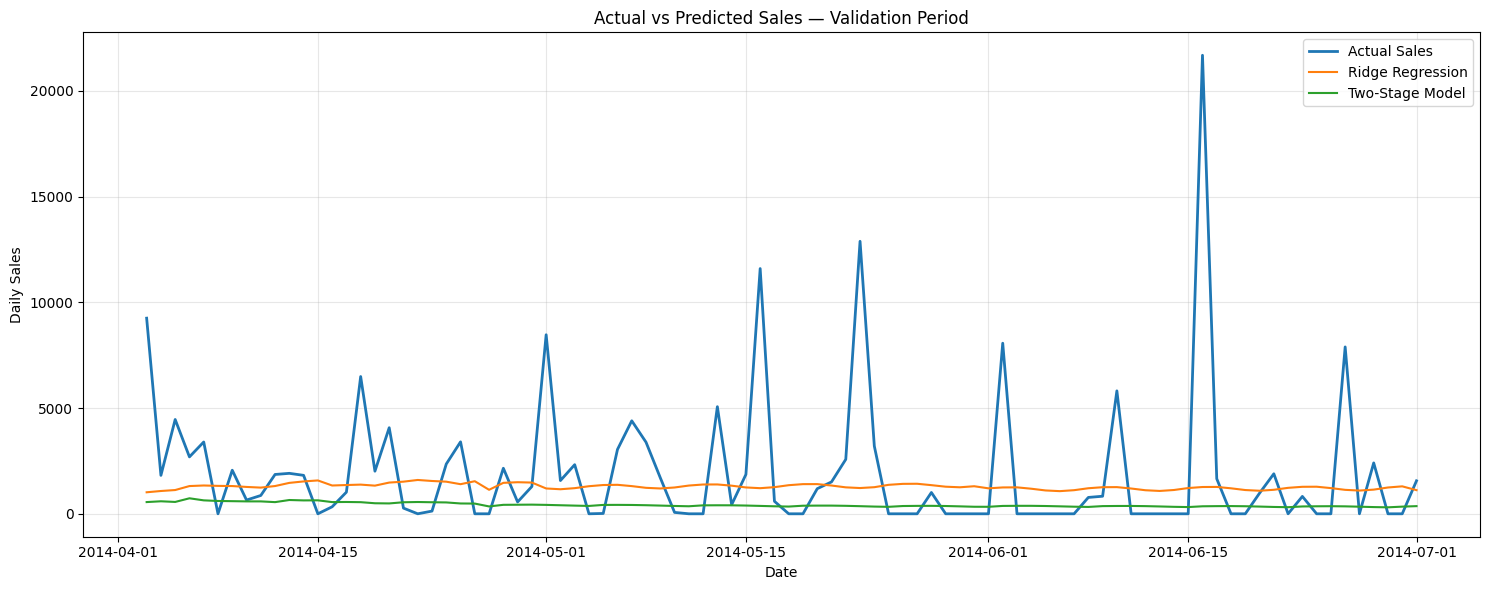

In [ ]:

# cell 67: Compare actual validation sales with Ridge and Two-Stage forecasts.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create a date-wise comparison using the same validation period.
prediction_comparison = pd.DataFrame(
    {
        "Actual_Sales": validation_data.to_numpy(dtype=float),
        "Ridge_Prediction": np.asarray(ridge_forecast, dtype=float),
        "Two_Stage_Prediction": np.asarray(two_stage_forecast, dtype=float)
    },
    index=validation_data.index
)

# Calculate each model's prediction error.
prediction_comparison["Ridge_Absolute_Error"] = (
    prediction_comparison["Actual_Sales"]
    - prediction_comparison["Ridge_Prediction"]
).abs()

prediction_comparison["Two_Stage_Absolute_Error"] = (
    prediction_comparison["Actual_Sales"]
    - prediction_comparison["Two_Stage_Prediction"]
).abs()

# Display the dates with the highest actual sales.
print("Top 10 actual sales days during validation:")

display(
    prediction_comparison
    .sort_values("Actual_Sales", ascending=False)
    .head(10)
    .round(2)
)

# Summarize which model has the lower absolute error more often.
ridge_better_days = (
    prediction_comparison["Ridge_Absolute_Error"]
    < prediction_comparison["Two_Stage_Absolute_Error"]
).sum()

two_stage_better_days = (
    prediction_comparison["Two_Stage_Absolute_Error"]
    < prediction_comparison["Ridge_Absolute_Error"]
).sum()

equal_error_days = (
    prediction_comparison["Ridge_Absolute_Error"]
    == prediction_comparison["Two_Stage_Absolute_Error"]
).sum()

print("\nDaily error comparison:")
print(f"Ridge has lower error: {ridge_better_days} days")
print(f"Two-Stage has lower error: {two_stage_better_days} days")
print(f"Equal error: {equal_error_days} days")

# Plot actual sales against both models' forecasts.
plt.figure(figsize=(15, 6))

plt.plot(
    prediction_comparison.index,
    prediction_comparison["Actual_Sales"],
    label="Actual Sales",
    linewidth=2
)

plt.plot(
    prediction_comparison.index,
    prediction_comparison["Ridge_Prediction"],
    label="Ridge Regression",
    linewidth=1.5
)

plt.plot(
    prediction_comparison.index,
    prediction_comparison["Two_Stage_Prediction"],
    label="Two-Stage Model",
    linewidth=1.5
)

plt.title("Actual vs Predicted Sales — Validation Period")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# cell 68: Evaluate both forecasting models separately on zero-sales and positive-sales days.

import numpy as np
import pandas as pd

actual = prediction_comparison["Actual_Sales"]

model_columns = {
    "Ridge Regression": "Ridge_Prediction",
    "Two-Stage Model": "Two_Stage_Prediction"
}

# Separate validation dates by their actual sales values.
day_groups = {
    "Zero-sales days": actual == 0,
    "Positive-sales days": actual > 0
}

results = []

for group_name, mask in day_groups.items():
    actual_group = actual.loc[mask].to_numpy(dtype=float)

    for model_name, prediction_column in model_columns.items():
        predictions = prediction_comparison.loc[
            mask, prediction_column
        ].to_numpy(dtype=float)

        results.append({
            "Day_Group": group_name,
            "Model": model_name,
            "Days": len(actual_group),
            "MAE": np.mean(np.abs(actual_group - predictions)),
            "RMSE": np.sqrt(np.mean((actual_group - predictions) ** 2)),
            "Mean_Predicted_Sales": np.mean(predictions),
            "Mean_Signed_Error": np.mean(predictions - actual_group)
        })

group_comparison = pd.DataFrame(results)

print("Model performance by actual sales group:")
display(group_comparison.round(2))

# Inspect how well each model predicts the highest-sales validation dates.
print("\nHighest-sales validation days:")
display(
    prediction_comparison.loc[
        actual.nlargest(5).index,
        [
            "Actual_Sales",
            "Ridge_Prediction",
            "Two_Stage_Prediction"
        ]
    ].round(2)
)

Model performance by actual sales group:


,Day_Group,Model,Days,MAE,RMSE,Mean_Predicted_Sales,Mean_Signed_Error
0,Zero-sales days,Ridge Regression,35,1267.37,1274.66,1267.37,1267.37
1,Zero-sales days,Two-Stage Model,35,377.33,384.71,377.33,377.33
2,Positive-sales days,Ridge Regression,55,2351.25,4272.52,1295.50,-1907.03
3,Positive-sales days,Two-Stage Model,55,2812.31,4699.16,449.34,-2753.19



Highest-sales validation days:


,Actual_Sales,Ridge_Prediction,Two_Stage_Prediction
OrderDate,,,
2014-06-16,21685.55,1266.57,355.00
2014-05-23,12886.57,1218.20,360.12
2014-05-16,11597.72,1211.34,372.92
2014-04-03,9251.91,1017.75,554.09
2014-05-01,8467.28,1197.85,421.32


In [ ]:

# cell 69: Diagnose occurrence probabilities and predicted sales amounts on validation data.

diagnostic_history = model_train.copy()
diagnostic_rows = []

for forecast_date in validation_data.index:
    features = pd.DataFrame([
        create_sales_features(diagnostic_history, forecast_date)
    ])

    # Estimate probability of positive sales.
    probability = occurrence_model.predict_proba(features)[0, 1]

    # Estimate the sales amount conditional on positive sales.
    predicted_log_amount = amount_model.predict(features)[0]
    predicted_amount = max(0, np.expm1(predicted_log_amount))

    # Combine probability and amount into expected sales.
    expected_sales = probability * predicted_amount

    diagnostic_rows.append({
        "Date": forecast_date,
        "Actual_Sales": float(validation_data.loc[forecast_date]),
        "Probability_Positive_Sales": probability,
        "Predicted_Amount_If_Sales": predicted_amount,
        "Expected_Sales": expected_sales
    })

    # Use the forecast, not actual validation sales, for the next date.
    diagnostic_history = pd.concat([
        diagnostic_history,
        pd.Series([expected_sales], index=[forecast_date])
    ])

two_stage_diagnostics = pd.DataFrame(diagnostic_rows).set_index("Date")

print("Two-Stage model component summary:")

display(
    two_stage_diagnostics[
        [
            "Probability_Positive_Sales",
            "Predicted_Amount_If_Sales",
            "Expected_Sales"
        ]
    ].describe().round(3)
)

print("\nFive highest actual-sales days:")

display(
    two_stage_diagnostics
    .sort_values("Actual_Sales", ascending=False)
    .head(5)
    .round(2)
)


Two-Stage model component summary:


,Probability_Positive_Sales,Predicted_Amount_If_Sales,Expected_Sales
count,90.000,90.000,90.000
mean,0.304,1410.898,421.336
std,0.083,196.123,99.656
min,0.166,1114.007,305.851
25%,0.245,1263.829,354.780
50%,0.279,1370.206,376.794
75%,0.356,1515.647,487.008
max,0.536,2040.656,733.175



Five highest actual-sales days:


,Actual_Sales,Probability_Positive_Sales,Predicted_Amount_If_Sales,Expected_Sales
Date,,,,
2014-06-16,21685.55,0.20,1802.29,355.00
2014-05-23,12886.57,0.28,1308.62,360.12
2014-05-16,11597.72,0.30,1240.48,372.92
2014-04-03,9251.91,0.49,1138.41,554.09
2014-05-01,8467.28,0.38,1114.01,421.32


## 9. Two-Stage Model Diagnostics

Evaluate occurrence probabilities, amount predictions, and recursive feature behavior.

In [ ]:
# cell 70: Evaluate how well the Two-Stage model estimates positive-sales days.

import numpy as np
import pandas as pd
from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    accuracy_score
)

# Create actual binary labels: 1 means positive sales, 0 means zero sales.
actual_occurrence = (
    two_stage_diagnostics["Actual_Sales"] > 0
).astype(int)

# Use the probabilities generated during the validation forecast.
predicted_probability = (
    two_stage_diagnostics["Probability_Positive_Sales"]
)

# Convert probabilities into binary predictions using a 0.5 threshold.
predicted_occurrence = (
    predicted_probability >= 0.5
).astype(int)

# Calculate occurrence classification metrics.
occurrence_metrics = {
    "Actual positive-sales rate (%)": actual_occurrence.mean() * 100,
    "Mean predicted probability (%)": predicted_probability.mean() * 100,
    "ROC-AUC": (
        roc_auc_score(actual_occurrence, predicted_probability)
        if actual_occurrence.nunique() == 2 else np.nan
    ),
    "Brier score (lower is better)": brier_score_loss(
        actual_occurrence, predicted_probability
    ),
    "Accuracy at 0.5 threshold (%)": accuracy_score(
        actual_occurrence, predicted_occurrence
    ) * 100
}

print("Sales occurrence evaluation:")
display(
    pd.DataFrame(
        occurrence_metrics.items(),
        columns=["Metric", "Value"]
    ).round(3)
)

# Compare actual and predicted occurrence counts.
print("\nActual vs predicted positive-sales days:")
display(
    pd.DataFrame({
        "Category": [
            "Actual positive-sales days",
            "Predicted positive-sales days (threshold 0.5)"
        ],
        "Days": [
            int(actual_occurrence.sum()),
            int(predicted_occurrence.sum())
        ]
    })
)

Sales occurrence evaluation:


,Metric,Value
0,Actual positive-sales rate (%),61.111
1,Mean predicted probability (%),30.432
2,ROC-AUC,0.703
3,Brier score (lower is better),0.309
4,Accuracy at 0.5 threshold (%),40.000



Actual vs predicted positive-sales days:


,Category,Days
0,Actual positive-sales days,55
1,Predicted positive-sales days (threshold 0.5),1


In [ ]:
# cell 71: Compare training features with recursively generated validation features.

# Build validation features using predictions only, never actual validation sales.
diagnostic_history = model_train.copy()
recursive_feature_rows = []

for forecast_date in validation_data.index:
    features = create_sales_features(
        diagnostic_history,
        forecast_date
    )
    recursive_feature_rows.append(features)

    probability = occurrence_model.predict_proba(
        pd.DataFrame([features])
    )[0, 1]

    predicted_log_amount = amount_model.predict(
        pd.DataFrame([features])
    )[0]

    predicted_amount = max(0, np.expm1(predicted_log_amount))
    expected_sales = probability * predicted_amount

    diagnostic_history = pd.concat([
        diagnostic_history,
        pd.Series([expected_sales], index=[forecast_date])
    ])

X_recursive_validation = pd.DataFrame(
    recursive_feature_rows,
    index=validation_data.index
)

# Compare the distributions of the most important lag and rolling features.
important_features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28"
]

feature_drift = []

for feature in important_features:
    feature_drift.append({
        "Feature": feature,
        "Training_Mean": X_two_stage[feature].mean(),
        "Forecast_Mean": X_recursive_validation[feature].mean(),
        "Training_Median": X_two_stage[feature].median(),
        "Forecast_Median": X_recursive_validation[feature].median()
    })

print("Training vs recursive validation feature comparison:")
display(pd.DataFrame(feature_drift).round(2))

# Compare the training sales rate with model probabilities.
training_positive_rate = (y_two_stage > 0).mean() * 100
training_mean_probability = (
    occurrence_model.predict_proba(X_two_stage)[:, 1].mean() * 100
)

print("\nOccurrence model diagnostic:")
print(f"Training positive-sales rate: {training_positive_rate:.2f}%")
print(f"Mean in-sample predicted probability: {training_mean_probability:.2f}%")
print(
    "Mean recursive validation probability:",
    f"{two_stage_diagnostics['Probability_Positive_Sales'].mean() * 100:.2f}%"
)

Training vs recursive validation feature comparison:


,Feature,Training_Mean,Forecast_Mean,Training_Median,Forecast_Median
0,lag_1,1280.44,417.31,0.00,376.79
1,lag_7,1266.75,568.35,0.00,379.70
2,lag_14,1260.66,618.87,0.00,389.21
3,lag_28,1253.50,673.98,0.00,414.22
4,rolling_mean_7,1273.19,498.22,785.64,383.58
5,rolling_mean_28,1261.36,608.52,1066.63,429.97



Occurrence model diagnostic:
Training positive-sales rate: 38.95%
Mean in-sample predicted probability: 38.95%
Mean recursive validation probability: 30.43%


In [ ]:

# cell 72: Compare weekday-wise sales patterns between training and validation.

def weekday_sales_summary(series, period_name):
    data = pd.DataFrame({
        "Sales": series.astype(float),
        "Weekday": series.index.day_name()
    })

    summary = (
        data.groupby("Weekday")
        .agg(
            Days=("Sales", "size"),
            Positive_Sales_Days=("Sales", lambda x: (x > 0).sum()),
            Mean_Sales=("Sales", "mean")
        )
    )

    summary["Positive_Rate_Percent"] = (
        summary["Positive_Sales_Days"] / summary["Days"] * 100
    )

    summary["Period"] = period_name
    return summary.reset_index()

weekday_comparison = pd.concat([
    weekday_sales_summary(model_train, "Training"),
    weekday_sales_summary(validation_data, "Validation")
], ignore_index=True)

weekday_comparison = weekday_comparison[
    [
        "Weekday",
        "Period",
        "Days",
        "Positive_Sales_Days",
        "Positive_Rate_Percent",
        "Mean_Sales"
    ]
]

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_comparison["Weekday"] = pd.Categorical(
    weekday_comparison["Weekday"],
    categories=weekday_order,
    ordered=True
)

weekday_comparison = weekday_comparison.sort_values(
    ["Weekday", "Period"]
)

print("Weekday-wise training vs validation sales patterns:")
display(weekday_comparison.round(2))


Weekday-wise training vs validation sales patterns:


,Weekday,Period,Days,Positive_Sales_Days,Positive_Rate_Percent,Mean_Sales
1,Monday,Training,167,53,31.74,1389.44
8,Monday,Validation,13,9,69.23,3004.58
5,Tuesday,Training,167,62,37.13,1180.83
12,Tuesday,Validation,13,7,53.85,1452.87
6,Wednesday,Training,167,74,44.31,1475.59
13,Wednesday,Validation,12,8,66.67,929.51
4,Thursday,Training,166,61,36.75,972.27
11,Thursday,Validation,13,9,69.23,2881.56
0,Friday,Training,167,69,41.32,1332.09
7,Friday,Validation,13,9,69.23,3177.93


In [ ]:

# cell 73: Evaluate a training-only weekday-average baseline against existing validation models.

import numpy as np
import pandas as pd

# Calculate average sales for each weekday using training data only.
weekday_means = model_train.groupby(
    model_train.index.dayofweek
).mean()

# Predict each validation date using its weekday's training average.
weekday_forecast = pd.Series(
    [
        weekday_means.loc[date.dayofweek]
        for date in validation_data.index
    ],
    index=validation_data.index,
    name="Weekday_Average_Forecast"
)

# Compare all forecasts over exactly the same validation dates.
forecasts_to_compare = {
    "Always Zero": np.zeros(len(validation_data)),
    "Ridge Regression": ridge_forecast.to_numpy(),
    "Two-Stage Model": two_stage_forecast,
    "Weekday Average": weekday_forecast.to_numpy()
}

results = []

for model_name, predictions in forecasts_to_compare.items():
    metrics = calculate_metrics(
        validation_data.to_numpy(dtype=float),
        np.asarray(predictions, dtype=float),
        model_train
    )

    results.append({
        "Model": model_name,
        **metrics
    })

weekday_baseline_comparison = (
    pd.DataFrame(results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("Weekday-average baseline vs existing models:")
display(weekday_baseline_comparison.round(3))

print("\nTraining average sales by weekday:")
display(
    pd.DataFrame({
        "Weekday": [
            "Monday", "Tuesday", "Wednesday", "Thursday",
            "Friday", "Saturday", "Sunday"
        ],
        "Training_Average_Sales": [
            weekday_means.loc[i] for i in range(7)
        ]
    }).round(2)
)


Weekday-average baseline vs existing models:


,Model,MAE,RMSE,WAPE_percent,MASE
0,Two-Stage Model,1865.371,3681.326,95.313,0.994
1,Ridge Regression,1929.736,3433.273,98.602,1.028
2,Weekday Average,1944.997,3435.698,99.381,1.036
3,Always Zero,1957.103,3879.302,100.000,1.043



Training average sales by weekday:


,Weekday,Training_Average_Sales
0,Monday,1389.44
1,Tuesday,1180.83
2,Wednesday,1475.59
3,Thursday,972.27
4,Friday,1332.09
5,Saturday,1084.52
6,Sunday,1322.20


## 10. Candidate Comparisons and Forecast Blending

Compare the Two-Stage model with simpler weekday baselines and blends using validation data.

In [ ]:
# cell 74: Compare Ridge and Two-Stage forecast blends on validation data.

import numpy as np
import pandas as pd

actual_validation = validation_data.to_numpy(dtype=float)
ridge_predictions = np.asarray(ridge_forecast, dtype=float)
two_stage_predictions = np.asarray(two_stage_forecast, dtype=float)

# Test a few fixed blend weights without fitting on validation targets.
blend_weights = [0.25, 0.50, 0.75]
blend_results = []

for ridge_weight in blend_weights:
    two_stage_weight = 1 - ridge_weight

    blended_predictions = (
        ridge_weight * ridge_predictions
        + two_stage_weight * two_stage_predictions
    )

    metrics = calculate_metrics(
        actual_validation,
        blended_predictions,
        model_train
    )

    blend_results.append({
        "Model": (
            f"Blend {int(ridge_weight * 100)}% Ridge / "
            f"{int(two_stage_weight * 100)}% Two-Stage"
        ),
        **metrics
    })

# Include the individual models as reference points.
for model_name, predictions in [
    ("Ridge Regression", ridge_predictions),
    ("Two-Stage Model", two_stage_predictions)
]:
    metrics = calculate_metrics(
        actual_validation,
        predictions,
        model_train
    )

    blend_results.append({
        "Model": model_name,
        **metrics
    })

blend_comparison = (
    pd.DataFrame(blend_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("Validation comparison of individual models and blends:")
display(blend_comparison.round(3))

Validation comparison of individual models and blends:


,Model,MAE,RMSE,WAPE_percent,MASE
0,Blend 25% Ridge / 75% Two-Stage,1858.016,3601.165,94.937,0.990
1,Blend 50% Ridge / 50% Two-Stage,1861.423,3532.657,95.111,0.992
2,Two-Stage Model,1865.371,3681.326,95.313,0.994
3,Blend 75% Ridge / 25% Two-Stage,1887.125,3476.491,96.424,1.006
4,Ridge Regression,1929.736,3433.273,98.602,1.028


In [ ]:
# cell 75: Analyze prediction errors of the best validation blend.

import numpy as np
import pandas as pd

best_blend_predictions = (
    0.25 * np.asarray(ridge_forecast, dtype=float)
    + 0.75 * np.asarray(two_stage_forecast, dtype=float)
)

blend_error_analysis = pd.DataFrame(
    {
        "Actual_Sales": validation_data.to_numpy(dtype=float),
        "Predicted_Sales": best_blend_predictions
    },
    index=validation_data.index
)

# Positive error means overprediction; negative error means underprediction.
blend_error_analysis["Error"] = (
    blend_error_analysis["Predicted_Sales"]
    - blend_error_analysis["Actual_Sales"]
)

blend_error_analysis["Absolute_Error"] = (
    blend_error_analysis["Error"].abs()
)

print("Overall error summary:")
display(
    blend_error_analysis[
        ["Actual_Sales", "Predicted_Sales", "Error"]
    ].describe().round(2)
)

print("\n10 dates with the largest absolute errors:")
display(
    blend_error_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
    .round(2)
)

print("\nMean prediction error:", round(
    blend_error_analysis["Error"].mean(), 2
))

Overall error summary:


,Actual_Sales,Predicted_Sales,Error
count,90.00,90.00,90.00
mean,1957.10,637.14,-1319.96
std,3368.20,93.76,3369.31
min,0.00,523.91,-21102.66
25%,0.00,575.11,-1546.32
50%,798.05,596.01,-172.46
75%,2280.69,699.71,574.49
max,21685.55,877.76,872.04



10 dates with the largest absolute errors:


,Actual_Sales,Predicted_Sales,Error,Absolute_Error
OrderDate,,,,
2014-06-16,21685.55,582.89,-21102.66,21102.66
2014-05-23,12886.57,574.64,-12311.93,12311.93
2014-05-16,11597.72,582.53,-11015.19,11015.19
2014-04-03,9251.91,670.00,-8581.91,8581.91
2014-05-01,8467.28,615.45,-7851.83,7851.83
2014-06-02,8067.35,590.71,-7476.64,7476.64
2014-06-26,7891.62,547.09,-7344.53,7344.53
2014-04-18,6491.28,757.26,-5734.01,5734.01
2014-06-10,5813.62,592.61,-5221.01,5221.01



Mean prediction error: -1319.96


In [ ]:
# cell 76: Examine training sales distribution and identify high-sales days.

import numpy as np
import pandas as pd

training_sales = model_train.astype(float)

sales_summary = pd.Series({
    "Total training days": len(training_sales),
    "Zero-sales days": int((training_sales == 0).sum()),
    "Positive-sales days": int((training_sales > 0).sum()),
    "Mean sales": training_sales.mean(),
    "Median sales": training_sales.median(),
    "90th percentile": training_sales.quantile(0.90),
    "95th percentile": training_sales.quantile(0.95),
    "99th percentile": training_sales.quantile(0.99),
    "Maximum sales": training_sales.max()
})

print("Training sales distribution:")
display(sales_summary.to_frame("Value").round(2))

print("\nTop 15 highest-sales days in training data:")
display(
    training_sales
    .sort_values(ascending=False)
    .head(15)
    .rename("Sales")
    .to_frame()
    .round(2)
)

print("\nValidation days above the training 95th percentile:")
high_sales_threshold = training_sales.quantile(0.95)

display(
    blend_error_analysis[
        blend_error_analysis["Actual_Sales"] > high_sales_threshold
    ].sort_values("Actual_Sales", ascending=False).round(2)
)

print("\nTraining 95th percentile threshold:", round(
    high_sales_threshold, 2
))

Training sales distribution:


,Value
Total training days,1168.00
Zero-sales days,723.00
Positive-sales days,445.00
Mean sales,1251.23
Median sales,0.00
90th percentile,3719.34
95th percentile,6323.50
99th percentile,14732.66
Maximum sales,60133.43



Top 15 highest-sales days in training data:


,Sales
OrderDate,
2013-12-29,60133.43
2012-12-24,33479.95
2012-09-11,29134.85
2013-12-16,24532.44
2012-09-05,22685.04
2014-01-14,19486.26
2013-08-28,19058.36
2013-10-12,17117.98
2013-10-25,17084.00



Validation days above the training 95th percentile:


,Actual_Sales,Predicted_Sales,Error,Absolute_Error
OrderDate,,,,
2014-06-16,21685.55,582.89,-21102.66,21102.66
2014-05-23,12886.57,574.64,-12311.93,12311.93
2014-05-16,11597.72,582.53,-11015.19,11015.19
2014-04-03,9251.91,670.00,-8581.91,8581.91
2014-05-01,8467.28,615.45,-7851.83,7851.83
2014-06-02,8067.35,590.71,-7476.64,7476.64
2014-06-26,7891.62,547.09,-7344.53,7344.53
2014-04-18,6491.28,757.26,-5734.01,5734.01



Training 95th percentile threshold: 6323.5


In [ ]:
# cell 77: Inspect calendar patterns among high-sales days using training data only.

import pandas as pd

training_calendar = pd.DataFrame({
    "Sales": model_train.astype(float)
})

training_calendar["Year"] = training_calendar.index.year
training_calendar["Month"] = training_calendar.index.month
training_calendar["Weekday"] = training_calendar.index.day_name()

# Define high-sales days using the training 95th percentile.
high_sales_threshold = training_calendar["Sales"].quantile(0.95)

training_calendar["High_Sales"] = (
    training_calendar["Sales"] > high_sales_threshold
)

high_sales_days = training_calendar[
    training_calendar["High_Sales"]
].sort_values("Sales", ascending=False)

print("High-sales days by year:")
display(
    high_sales_days.groupby("Year").agg(
        High_Sales_Days=("Sales", "size"),
        Average_Sales=("Sales", "mean"),
        Maximum_Sales=("Sales", "max")
    ).round(2)
)

print("\nHigh-sales days by month:")
display(
    high_sales_days.groupby("Month").agg(
        High_Sales_Days=("Sales", "size"),
        Average_Sales=("Sales", "mean"),
        Maximum_Sales=("Sales", "max")
    ).sort_values("High_Sales_Days", ascending=False).round(2)
)

print("\nHigh-sales days by weekday:")
display(
    high_sales_days.groupby("Weekday").agg(
        High_Sales_Days=("Sales", "size"),
        Average_Sales=("Sales", "mean"),
        Maximum_Sales=("Sales", "max")
    ).sort_values("High_Sales_Days", ascending=False).round(2)
)

print("\nAll high-sales dates:")
display(high_sales_days.round(2))

High-sales days by year:


,High_Sales_Days,Average_Sales,Maximum_Sales
Year,,,
2011,4,9545.85,11379.29
2012,17,12846.23,33479.95
2013,30,12179.73,60133.43
2014,8,10809.13,19486.26



High-sales days by month:


,High_Sales_Days,Average_Sales,Maximum_Sales
Month,,,
1,8,9924.23,19486.26
12,8,20767.27,60133.43
9,8,13003.01,29134.85
10,7,12364.44,17117.98
7,6,10987.96,16323.73
8,6,10298.09,19058.36
2,4,9503.02,11719.11
3,4,10242.38,12240.11
4,4,7149.97,8523.42



High-sales days by weekday:


,High_Sales_Days,Average_Sales,Maximum_Sales
Weekday,,,
Friday,12,9532.72,17084.00
Monday,12,12353.15,33479.95
Wednesday,9,12098.94,22685.04
Thursday,7,9164.57,15159.19
Sunday,7,16534.65,60133.43
Tuesday,7,14517.97,29134.85
Saturday,5,11078.59,17117.98



All high-sales dates:


,Sales,Year,Month,Weekday,High_Sales
OrderDate,,,,,
2013-12-29,60133.43,2013,12,Sunday,True
2012-12-24,33479.95,2012,12,Monday,True
2012-09-11,29134.85,2012,9,Tuesday,True
2013-12-16,24532.44,2013,12,Monday,True
2012-09-05,22685.04,2012,9,Wednesday,True
2014-01-14,19486.26,2014,1,Tuesday,True
2013-08-28,19058.36,2013,8,Wednesday,True
2013-10-12,17117.98,2013,10,Saturday,True
2013-10-25,17084.00,2013,10,Friday,True


In [ ]:
# cell 78: Compare zero-sales frequency and sales distribution in training and validation.

import pandas as pd
import numpy as np

def summarize_sales(series, dataset_name):
    values = series.astype(float)

    return {
        "Dataset": dataset_name,
        "Total_Days": len(values),
        "Zero_Sales_Days": int((values == 0).sum()),
        "Positive_Sales_Days": int((values > 0).sum()),
        "Positive_Sales_Rate_%": (values > 0).mean() * 100,
        "Mean_Sales": values.mean(),
        "Median_Sales": values.median(),
        "95th_Percentile": values.quantile(0.95),
        "Maximum_Sales": values.max()
    }

distribution_comparison = pd.DataFrame([
    summarize_sales(model_train, "Training"),
    summarize_sales(validation_data, "Validation")
])

print("Training vs validation distribution:")
display(distribution_comparison.round(2))

# Compare positive-sales frequency by weekday.
weekday_names = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_rows = []

for day_number, day_name in enumerate(weekday_names):
    train_day = model_train[model_train.index.dayofweek == day_number]
    validation_day = validation_data[
        validation_data.index.dayofweek == day_number
    ]

    weekday_rows.append({
        "Weekday": day_name,
        "Training_Positive_Rate_%": (train_day > 0).mean() * 100,
        "Validation_Positive_Rate_%": (
            (validation_day > 0).mean() * 100
        ),
        "Training_Days": len(train_day),
        "Validation_Days": len(validation_day)
    })

print("\nPositive-sales rate by weekday:")
display(pd.DataFrame(weekday_rows).round(2))

Training vs validation distribution:


,Dataset,Total_Days,Zero_Sales_Days,Positive_Sales_Days,Positive_Sales_Rate_%,Mean_Sales,Median_Sales,95th_Percentile,Maximum_Sales
0,Training,1168,723,445,38.10,1251.23,0.00,6323.50,60133.43
1,Validation,90,35,55,61.11,1957.10,798.05,8287.31,21685.55



Positive-sales rate by weekday:


,Weekday,Training_Positive_Rate_%,Validation_Positive_Rate_%,Training_Days,Validation_Days
0,Monday,31.74,69.23,167,13
1,Tuesday,37.13,53.85,167,13
2,Wednesday,44.31,66.67,167,12
3,Thursday,36.75,69.23,166,13
4,Friday,41.32,69.23,167,13
5,Saturday,41.32,69.23,167,13
6,Sunday,34.13,30.77,167,13


## 11. Recent-Window Experiments and Backtesting

Compare training windows and evaluate candidate approaches across historical validation folds.

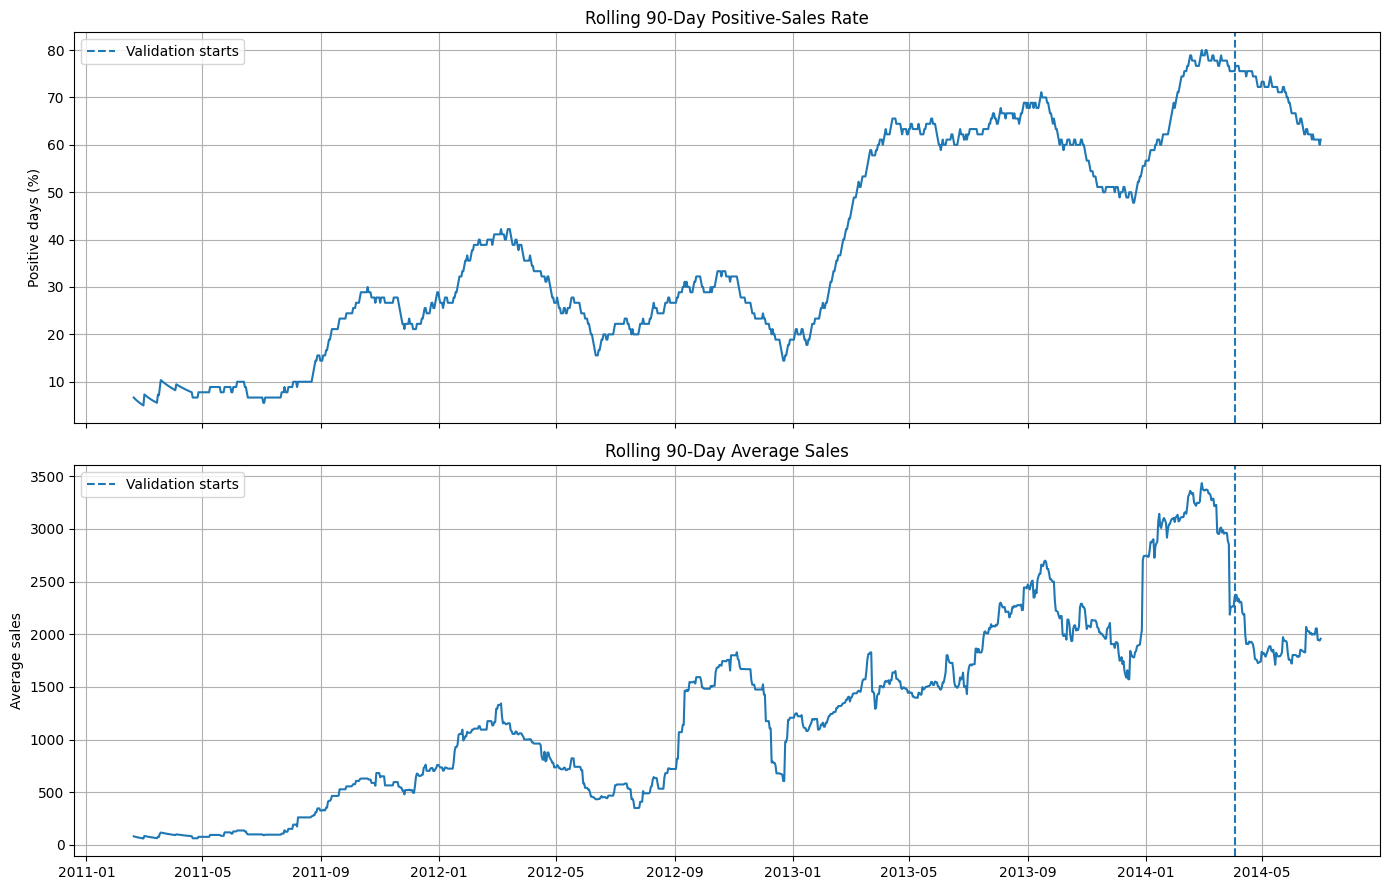

Latest rolling 90-day values:


,Positive_Rate_90D,Average_Sales_90D
OrderDate,,
2014-06-17,63.33,2034.90
2014-06-18,62.22,2027.75
2014-06-19,62.22,2027.75
2014-06-20,62.22,2005.16
2014-06-21,62.22,2013.73
2014-06-22,61.11,1995.36
2014-06-23,62.22,2004.49
2014-06-24,61.11,1998.71
2014-06-25,61.11,1998.71


In [ ]:

# cell 79: Analyze how sales frequency and average sales change over time.

import pandas as pd
import matplotlib.pyplot as plt

# Combine only training and validation data for diagnostic analysis.
analysis_sales = pd.concat([
    model_train.rename("Sales"),
    validation_data.rename("Sales")
]).sort_index()

# Calculate whether sales occurred on each day.
analysis_df = pd.DataFrame(index=analysis_sales.index)
analysis_df["Sales"] = analysis_sales
analysis_df["Positive_Sales"] = (analysis_sales > 0).astype(int)

# Calculate rolling 90-day sales frequency and average sales.
analysis_df["Positive_Rate_90D"] = (
    analysis_df["Positive_Sales"].rolling(90, min_periods=30).mean() * 100
)
analysis_df["Average_Sales_90D"] = (
    analysis_df["Sales"].rolling(90, min_periods=30).mean()
)

# Mark the validation period for reference.
validation_start = validation_data.index.min()

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].plot(
    analysis_df.index,
    analysis_df["Positive_Rate_90D"]
)
axes[0].axvline(
    validation_start,
    linestyle="--",
    label="Validation starts"
)
axes[0].set_title("Rolling 90-Day Positive-Sales Rate")
axes[0].set_ylabel("Positive days (%)")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    analysis_df.index,
    analysis_df["Average_Sales_90D"]
)
axes[1].axvline(
    validation_start,
    linestyle="--",
    label="Validation starts"
)
axes[1].set_title("Rolling 90-Day Average Sales")
axes[1].set_ylabel("Average sales")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Display the latest rolling values for context.
print("Latest rolling 90-day values:")
display(analysis_df[[
    "Positive_Rate_90D",
    "Average_Sales_90D"
]].tail(15).round(2))


In [ ]:

# cell 80: Compare Two-Stage forecasting with full, 540-day, and 365-day training windows.

import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge

# Match each supervised feature row with its target date.
training_feature_dates = model_train.index[28:]

window_results = []
window_forecasts = {}

# Compare full training history with two recent-data windows.
windows = {
    "Full History": None,
    "Last 540 Days": 540,
    "Last 365 Days": 365
}

for window_name, window_days in windows.items():

    # Select training examples from the requested date window.
    if window_days is None:
        mask = np.ones(len(y_train_ridge), dtype=bool)
    else:
        cutoff_date = (
            model_train.index.max()
            - pd.Timedelta(days=window_days - 1)
        )
        mask = np.asarray(training_feature_dates >= cutoff_date)

    X_window = X_train_ridge.loc[mask].copy()
    y_window = np.asarray(y_train_ridge)[mask]

    # Train the sales-occurrence model.
    occurrence_model_window = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )

    occurrence_model_window.fit(
        X_window,
        (y_window > 0).astype(int)
    )

    # Train the sales-amount model only on positive-sales days.
    positive_mask = y_window > 0

    amount_model_window = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10)
    )

    amount_model_window.fit(
        X_window.loc[positive_mask],
        np.log1p(y_window[positive_mask])
    )

    # Forecast validation recursively without using actual validation sales.
    forecast_history_window = model_train.copy()
    predictions_window = []

    for forecast_date in validation_data.index:

        features = pd.DataFrame([
            create_sales_features(
                forecast_history_window,
                forecast_date
            )
        ])

        probability_positive = occurrence_model_window.predict_proba(
            features
        )[0, 1]

        predicted_log_amount = amount_model_window.predict(features)[0]
        predicted_amount = max(0, np.expm1(predicted_log_amount))

        expected_sales = probability_positive * predicted_amount
        expected_sales = max(0, expected_sales)

        predictions_window.append(expected_sales)

        forecast_history_window = pd.concat([
            forecast_history_window,
            pd.Series([expected_sales], index=[forecast_date])
        ])

    predictions_window = pd.Series(
        predictions_window,
        index=validation_data.index,
        name=window_name
    )

    window_forecasts[window_name] = predictions_window

    # Evaluate each window on the same untouched validation period.
    metrics = calculate_metrics(
        validation_data.to_numpy(),
        predictions_window.to_numpy(),
        model_train
    )

    window_results.append({
        "Training_Window": window_name,
        "Training_Examples": len(y_window),
        "Positive_Training_Days": int(positive_mask.sum()),
        **metrics
    })

window_comparison = (
    pd.DataFrame(window_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("Two-Stage model: training-window comparison")
display(window_comparison.round(3))

print("\nBest window by validation MAE:")
print(window_comparison.iloc[0]["Training_Window"])


Two-Stage model: training-window comparison


,Training_Window,Training_Examples,Positive_Training_Days,MAE,RMSE,WAPE_percent,MASE
0,Last 365 Days,365,234,1859.479,3528.162,95.012,0.991
1,Last 540 Days,540,305,1864.750,3520.151,95.281,0.994
2,Full History,1140,444,1865.371,3681.326,95.313,0.994



Best window by validation MAE:
Last 365 Days


In [ ]:

# cell 81: Compare the recent-window Two-Stage model with Ridge and blended forecasts.

import pandas as pd

# Retrieve forecasts already generated in Cell 81.
recent_forecast = window_forecasts["Last 365 Days"]

# Use the existing Ridge forecast and previously tested full-history blend.
ridge_predictions = pd.Series(
    ridge_forecast.to_numpy(),
    index=validation_data.index
)

full_history_two_stage = pd.Series(
    two_stage_forecast,
    index=validation_data.index
)

# Compare standalone forecasts and alternative blends.
candidate_forecasts = {
    "Ridge": ridge_predictions,
    "Full History Two-Stage": full_history_two_stage,
    "Last 365 Days Two-Stage": recent_forecast,
    "Blend: Ridge 25% + Recent 75%": (
        0.25 * ridge_predictions + 0.75 * recent_forecast
    ),
    "Blend: Ridge 50% + Recent 50%": (
        0.50 * ridge_predictions + 0.50 * recent_forecast
    )
}

comparison_rows = []

for model_name, predictions in candidate_forecasts.items():

    metrics = calculate_metrics(
        validation_data.to_numpy(),
        predictions.to_numpy(),
        model_train
    )

    comparison_rows.append({
        "Model": model_name,
        **metrics
    })

candidate_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("Validation comparison of forecasting candidates:")
display(candidate_comparison.round(3))

print("\nBest model by MAE:")
print(candidate_comparison.iloc[0]["Model"])


Validation comparison of forecasting candidates:


,Model,MAE,RMSE,WAPE_percent,MASE
0,Last 365 Days Two-Stage,1859.479,3528.162,95.012,0.991
1,Full History Two-Stage,1865.371,3681.326,95.313,0.994
2,Blend: Ridge 25% + Recent 75%,1866.972,3498.857,95.395,0.995
3,Blend: Ridge 50% + Recent 50%,1882.902,3473.222,96.209,1.003
4,Ridge,1929.736,3433.273,98.602,1.028



Best model by MAE:
Last 365 Days Two-Stage


In [ ]:

# cell 82: Backtest full-history and recent-history Two-Stage models across three historical periods.

import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge

# Prepare dates corresponding to the existing supervised training rows.
feature_dates = model_train.index[28:]
target_values = np.asarray(y_train_ridge)

# Select three consecutive 90-day historical evaluation periods.
fold_start_positions = [
    len(model_train) - 270,
    len(model_train) - 180,
    len(model_train) - 90
]

backtest_rows = []

for fold_number, start_position in enumerate(fold_start_positions, start=1):

    # Separate historical training data from the 90-day evaluation period.
    fold_start = model_train.index[start_position]
    fold_end_position = min(start_position + 90, len(model_train))

    fold_actual = model_train.iloc[start_position:fold_end_position]
    fold_history = model_train.loc[model_train.index < fold_start]

    print(
        f"Fold {fold_number}: "
        f"{fold_actual.index.min().date()} to "
        f"{fold_actual.index.max().date()}"
    )

    for window_name, window_days in [
        ("Full History", None),
        ("Last 365 Days", 365)
    ]:

        # Use only supervised examples available before this fold begins.
        train_mask = np.asarray(feature_dates < fold_start)

        if window_days is not None:
            cutoff_date = fold_start - pd.Timedelta(days=window_days - 1)
            train_mask &= np.asarray(feature_dates >= cutoff_date)

        X_fold = X_train_ridge.iloc[np.flatnonzero(train_mask)].copy()
        y_fold = target_values[train_mask]

        # Train the occurrence model using only historical data.
        occurrence_model_fold = make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000)
        )
        occurrence_model_fold.fit(
            X_fold,
            (y_fold > 0).astype(int)
        )

        # Train the amount model on historical positive-sales days.
        positive_mask = y_fold > 0

        amount_model_fold = make_pipeline(
            StandardScaler(),
            Ridge(alpha=10)
        )
        amount_model_fold.fit(
            X_fold.iloc[np.flatnonzero(positive_mask)],
            np.log1p(y_fold[positive_mask])
        )

        # Generate recursive forecasts without using actual fold sales.
        recursive_history = fold_history.copy()
        fold_predictions = []

        for forecast_date in fold_actual.index:

            features = pd.DataFrame([
                create_sales_features(recursive_history, forecast_date)
            ])

            probability = occurrence_model_fold.predict_proba(
                features
            )[0, 1]

            predicted_log_amount = amount_model_fold.predict(features)[0]
            predicted_amount = max(0, np.expm1(predicted_log_amount))
            predicted_sales = max(0, probability * predicted_amount)

            fold_predictions.append(predicted_sales)

            recursive_history = pd.concat([
                recursive_history,
                pd.Series([predicted_sales], index=[forecast_date])
            ])

        # Evaluate this fold using its own historical training series.
        metrics = calculate_metrics(
            fold_actual.to_numpy(),
            np.asarray(fold_predictions),
            fold_history
        )

        backtest_rows.append({
            "Fold": fold_number,
            "Period_Start": fold_actual.index.min().date(),
            "Period_End": fold_actual.index.max().date(),
            "Training_Window": window_name,
            "Training_Examples": len(y_fold),
            **metrics
        })

backtest_results = pd.DataFrame(backtest_rows)

print("\nHistorical backtesting results:")
display(
    backtest_results.sort_values(
        ["Fold", "Training_Window"]
    ).round(3)
)

print("\nAverage metrics across the three folds:")
display(
    backtest_results.groupby("Training_Window")[
        ["MAE", "RMSE", "WAPE_percent", "MASE"]
    ].mean().round(3)
)


Fold 1: 2013-07-07 to 2013-10-04
Fold 2: 2013-10-05 to 2014-01-02
Fold 3: 2014-01-03 to 2014-04-02

Historical backtesting results:


,Fold,Period_Start,Period_End,Training_Window,Training_Examples,MAE,RMSE,WAPE_percent,MASE
0,1,2013-07-07,2013-10-04,Full History,870,2110.337,3943.128,98.119,1.465
1,1,2013-07-07,2013-10-04,Last 365 Days,364,2088.165,3836.069,97.089,1.449
2,2,2013-10-05,2014-01-02,Full History,960,2731.942,7665.655,99.504,1.723
3,2,2013-10-05,2014-01-02,Last 365 Days,364,2770.421,7618.135,100.906,1.748
4,3,2014-01-03,2014-04-02,Full History,1050,1946.295,3574.348,85.965,1.123
5,3,2014-01-03,2014-04-02,Last 365 Days,364,2016.114,3612.466,89.048,1.164



Average metrics across the three folds:


,MAE,RMSE,WAPE_percent,MASE
Training_Window,,,,
Full History,2262.858,5061.044,94.530,1.437
Last 365 Days,2291.566,5022.223,95.681,1.453


In [ ]:

# cell 83: Backtest simple sales forecasting baselines across the same three historical periods.

import numpy as np
import pandas as pd

fold_start_positions = [
    len(model_train) - 270,
    len(model_train) - 180,
    len(model_train) - 90
]

baseline_rows = []

for fold_number, start_position in enumerate(fold_start_positions, start=1):

    # Keep all actual values before the evaluation period as historical data.
    fold_start = model_train.index[start_position]
    fold_end_position = min(start_position + 90, len(model_train))

    fold_actual = model_train.iloc[start_position:fold_end_position]
    fold_history = model_train.loc[model_train.index < fold_start]

    # Calculate baseline values using only information available before the fold.
    recent_90_mean = fold_history.tail(90).mean()

    recent_365 = fold_history.tail(365)
    overall_mean = fold_history.mean()

    weekday_means = recent_365.groupby(
        recent_365.index.dayofweek
    ).mean()

    predictions = {
        "Recent 90-Day Mean": [],
        "Recent 365-Day Weekday Mean": [],
        "Seasonal Naive (Lag 7)": []
    }

    recursive_history = fold_history.copy()

    for forecast_date in fold_actual.index:

        # Predict using the mean of the last 90 historical days.
        predictions["Recent 90-Day Mean"].append(recent_90_mean)

        # Predict using the recent average for this weekday.
        weekday_value = weekday_means.get(
            forecast_date.dayofweek,
            overall_mean
        )
        predictions["Recent 365-Day Weekday Mean"].append(weekday_value)

        # Predict using the value from seven days earlier.
        lag_date = forecast_date - pd.Timedelta(days=7)

        if lag_date in recursive_history.index:
            lag_7_value = recursive_history.loc[lag_date]
        else:
            lag_7_value = overall_mean

        predictions["Seasonal Naive (Lag 7)"].append(lag_7_value)

        # Update only with the generated prediction, never the actual fold value.
        recursive_history = pd.concat([
            recursive_history,
            pd.Series([lag_7_value], index=[forecast_date])
        ])

    # Evaluate each baseline on the same fold.
    for baseline_name, forecast_values in predictions.items():

        metrics = calculate_metrics(
            fold_actual.to_numpy(),
            np.asarray(forecast_values),
            fold_history
        )

        baseline_rows.append({
            "Fold": fold_number,
            "Period_Start": fold_actual.index.min().date(),
            "Period_End": fold_actual.index.max().date(),
            "Baseline": baseline_name,
            **metrics
        })

baseline_results = pd.DataFrame(baseline_rows)

print("Baseline performance for each historical fold:")
display(
    baseline_results.sort_values(
        ["Fold", "Baseline"]
    ).round(3)
)

print("\nAverage baseline performance:")
display(
    baseline_results.groupby("Baseline")[
        ["MAE", "RMSE", "WAPE_percent", "MASE"]
    ].mean().sort_values("MAE").round(3)
)


Baseline performance for each historical fold:


,Fold,Period_Start,Period_End,Baseline,MAE,RMSE,WAPE_percent,MASE
1,1,2013-07-07,2013-10-04,Recent 365-Day Weekday Mean,2295.693,3630.786,106.738,1.593
0,1,2013-07-07,2013-10-04,Recent 90-Day Mean,2315.232,3578.183,107.646,1.607
2,1,2013-07-07,2013-10-04,Seasonal Naive (Lag 7),5022.836,7298.693,233.535,3.486
4,2,2013-10-05,2014-01-02,Recent 365-Day Weekday Mean,2932.742,7384.293,106.818,1.850
3,2,2013-10-05,2014-01-02,Recent 90-Day Mean,3095.032,7281.698,112.729,1.952
5,2,2013-10-05,2014-01-02,Seasonal Naive (Lag 7),2789.872,7740.820,101.614,1.760
7,3,2014-01-03,2014-04-02,Recent 365-Day Weekday Mean,2158.074,3270.608,95.319,1.245
6,3,2014-01-03,2014-04-02,Recent 90-Day Mean,2438.514,3281.891,107.705,1.407
8,3,2014-01-03,2014-04-02,Seasonal Naive (Lag 7),11035.997,22180.512,487.442,6.369



Average baseline performance:


,MAE,RMSE,WAPE_percent,MASE
Baseline,,,,
Recent 365-Day Weekday Mean,2462.170,4761.896,102.958,1.563
Recent 90-Day Mean,2616.259,4713.924,109.360,1.655
Seasonal Naive (Lag 7),6282.902,12406.675,274.197,3.872


In [ ]:

# cell 84: Compare Two-Stage models directly against the weekday-average baseline across folds.

# Keep only the two Two-Stage models and the strongest simple MAE baseline.
model_comparison = backtest_results[
    backtest_results["Training_Window"].isin([
        "Full History",
        "Last 365 Days"
    ])
].copy()

model_comparison = model_comparison.rename(
    columns={"Training_Window": "Model"}
)

weekday_baseline = baseline_results[
    baseline_results["Baseline"] == "Recent 365-Day Weekday Mean"
].copy()

weekday_baseline = weekday_baseline.rename(
    columns={"Baseline": "Model"}
)

combined_comparison = pd.concat(
    [model_comparison, weekday_baseline],
    ignore_index=True
)

print("MAE by historical fold:")
display(
    combined_comparison.pivot(
        index="Fold",
        columns="Model",
        values="MAE"
    ).round(3)
)

print("\nRMSE by historical fold:")
display(
    combined_comparison.pivot(
        index="Fold",
        columns="Model",
        values="RMSE"
    ).round(3)
)

print("\nAverage metrics across folds:")
display(
    combined_comparison.groupby("Model")[
        ["MAE", "RMSE", "WAPE_percent", "MASE"]
    ].mean().sort_values("MAE").round(3)
)


MAE by historical fold:


Model,Full History,Last 365 Days,Recent 365-Day Weekday Mean
Fold,,,
1,2110.337,2088.165,2295.693
2,2731.942,2770.421,2932.742
3,1946.295,2016.114,2158.074



RMSE by historical fold:


Model,Full History,Last 365 Days,Recent 365-Day Weekday Mean
Fold,,,
1,3943.128,3836.069,3630.786
2,7665.655,7618.135,7384.293
3,3574.348,3612.466,3270.608



Average metrics across folds:


,MAE,RMSE,WAPE_percent,MASE
Model,,,,
Full History,2262.858,5061.044,94.530,1.437
Last 365 Days,2291.566,5022.223,95.681,1.453
Recent 365-Day Weekday Mean,2462.170,4761.896,102.958,1.563


In [ ]:

# cell 85: Backtest a blend of the Full History Two-Stage model and weekday-average baseline.

import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge

fold_start_positions = [
    len(model_train) - 270,
    len(model_train) - 180,
    len(model_train) - 90
]

blend_backtest_rows = []

for fold_number, start_position in enumerate(fold_start_positions, start=1):

    # Separate historical training data and the 90-day evaluation period.
    fold_start = model_train.index[start_position]
    fold_end_position = min(start_position + 90, len(model_train))

    fold_actual = model_train.iloc[start_position:fold_end_position]
    fold_history = model_train.loc[model_train.index < fold_start]

    # Select only supervised examples whose target dates precede this fold.
    train_mask = np.asarray(feature_dates < fold_start)

    X_fold = X_train_ridge.iloc[np.flatnonzero(train_mask)].copy()
    y_fold = target_values[train_mask]

    # Fit the occurrence model using the full available history.
    occurrence_model_fold = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )
    occurrence_model_fold.fit(
        X_fold,
        (y_fold > 0).astype(int)
    )

    # Fit the amount model on positive-sales examples only.
    positive_mask = y_fold > 0

    amount_model_fold = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10)
    )
    amount_model_fold.fit(
        X_fold.iloc[np.flatnonzero(positive_mask)],
        np.log1p(y_fold[positive_mask])
    )

    # Calculate weekday averages from the previous 365 days only.
    recent_history = fold_history.tail(365)
    overall_mean = recent_history.mean()

    weekday_means = recent_history.groupby(
        recent_history.index.dayofweek
    ).mean()

    # Generate recursive Two-Stage forecasts without actual fold sales.
    recursive_history = fold_history.copy()
    two_stage_predictions = []
    weekday_predictions = []

    for forecast_date in fold_actual.index:

        features = pd.DataFrame([
            create_sales_features(recursive_history, forecast_date)
        ])

        probability = occurrence_model_fold.predict_proba(
            features
        )[0, 1]

        predicted_log_amount = amount_model_fold.predict(features)[0]
        predicted_amount = max(0, np.expm1(predicted_log_amount))
        predicted_sales = max(0, probability * predicted_amount)

        weekday_value = weekday_means.get(
            forecast_date.dayofweek,
            overall_mean
        )

        two_stage_predictions.append(predicted_sales)
        weekday_predictions.append(weekday_value)

        # Feed only the Two-Stage forecast into its future lag features.
        recursive_history = pd.concat([
            recursive_history,
            pd.Series([predicted_sales], index=[forecast_date])
        ])

    two_stage_predictions = np.asarray(two_stage_predictions)
    weekday_predictions = np.asarray(weekday_predictions)

    candidate_predictions = {
        "Full History Two-Stage": two_stage_predictions,
        "Recent 365-Day Weekday Mean": weekday_predictions,
        "Blend 75% Two-Stage + 25% Weekday": (
            0.75 * two_stage_predictions + 0.25 * weekday_predictions
        )
    }

    # Evaluate all candidates on exactly the same fold.
    for candidate_name, predictions in candidate_predictions.items():

        metrics = calculate_metrics(
            fold_actual.to_numpy(),
            predictions,
            fold_history
        )

        blend_backtest_rows.append({
            "Fold": fold_number,
            "Candidate": candidate_name,
            **metrics
        })

blend_backtest_results = pd.DataFrame(blend_backtest_rows)

print("Blend backtest results by fold:")
display(
    blend_backtest_results.sort_values(
        ["Fold", "Candidate"]
    ).round(3)
)

print("\nAverage metrics across folds:")
display(
    blend_backtest_results.groupby("Candidate")[
        ["MAE", "RMSE", "WAPE_percent", "MASE"]
    ].mean().sort_values("MAE").round(3)
)


Blend backtest results by fold:


,Fold,Candidate,MAE,RMSE,WAPE_percent,MASE
2,1,Blend 75% Two-Stage + 25% Weekday,2126.518,3836.990,98.872,1.476
0,1,Full History Two-Stage,2110.337,3943.128,98.119,1.465
1,1,Recent 365-Day Weekday Mean,2295.693,3630.786,106.738,1.593
5,2,Blend 75% Two-Stage + 25% Weekday,2748.143,7572.971,100.094,1.734
3,2,Full History Two-Stage,2731.942,7665.655,99.504,1.723
4,2,Recent 365-Day Weekday Mean,2932.742,7384.293,106.818,1.850
8,3,Blend 75% Two-Stage + 25% Weekday,1881.159,3429.616,83.088,1.086
6,3,Full History Two-Stage,1946.295,3574.348,85.965,1.123
7,3,Recent 365-Day Weekday Mean,2158.074,3270.608,95.319,1.245



Average metrics across folds:


,MAE,RMSE,WAPE_percent,MASE
Candidate,,,,
Blend 75% Two-Stage + 25% Weekday,2251.940,4946.526,94.018,1.432
Full History Two-Stage,2262.858,5061.044,94.530,1.437
Recent 365-Day Weekday Mean,2462.170,4761.896,102.958,1.563


In [ ]:

# cell 86: Compare the leading models and weekday-average blend on the validation period.

import numpy as np
import pandas as pd

# Calculate weekday averages using training data only.
recent_training = model_train.tail(365)
overall_training_mean = recent_training.mean()

weekday_means = recent_training.groupby(
    recent_training.index.dayofweek
).mean()

weekday_forecast = pd.Series(
    [
        weekday_means.get(date.dayofweek, overall_training_mean)
        for date in validation_data.index
    ],
    index=validation_data.index,
    name="Weekday Average"
)

# Prepare all candidate predictions for the same validation dates.
full_history_forecast = pd.Series(
    np.asarray(two_stage_forecast),
    index=validation_data.index
)

recent_forecast_validation = pd.Series(
    np.asarray(window_forecasts["Last 365 Days"]),
    index=validation_data.index
)

validation_candidates = {
    "Full History Two-Stage": full_history_forecast,
    "Last 365 Days Two-Stage": recent_forecast_validation,
    "Recent 365-Day Weekday Mean": weekday_forecast,
    "Blend 75% Two-Stage + 25% Weekday": (
        0.75 * full_history_forecast + 0.25 * weekday_forecast
    )
}

validation_comparison_rows = []

for candidate_name, predictions in validation_candidates.items():

    metrics = calculate_metrics(
        validation_data.to_numpy(),
        predictions.to_numpy(),
        model_train
    )

    validation_comparison_rows.append({
        "Model": candidate_name,
        **metrics
    })

validation_comparison = (
    pd.DataFrame(validation_comparison_rows)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("Final candidate comparison on validation data:")
display(validation_comparison.round(3))

print("\nBest validation candidate by MAE:")
print(validation_comparison.iloc[0]["Model"])


Final candidate comparison on validation data:


,Model,MAE,RMSE,WAPE_percent,MASE
0,Last 365 Days Two-Stage,1859.479,3528.162,95.012,0.991
1,Full History Two-Stage,1865.371,3681.326,95.313,0.994
2,Blend 75% Two-Stage + 25% Weekday,1872.609,3536.675,95.683,0.998
3,Recent 365-Day Weekday Mean,2292.678,3454.086,117.147,1.222



Best validation candidate by MAE:
Last 365 Days Two-Stage


## Previous Test Results - Historical Record

The earlier 2014 test results were inspected before later model experiments. The revised candidate comparison and retrospective test report are in the closing section.

The previous hard-coded 365-day two-stage test evaluation has been removed from this position. The test window is scored after the revised candidate-selection cells at the end.

The previous test subgroup diagnostics have been moved to the revised closing evaluation section.

## 13. Validation-Only Follow-Up Experiments

The following diagnostics and experiments use validation data to understand weaknesses and compare alternatives; they do not use the final test metrics to choose the model.

In [ ]:
# cell 89: Re-evaluate the selected Two-Stage model on validation data without using final test data.

import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge

# Build training features using only the model training period.
validation_feature_dates = model_train.index[28:]

X_val_train = pd.DataFrame(
    [
        create_sales_features(model_train.iloc[:i], model_train.index[i])
        for i in range(28, len(model_train))
    ],
    index=validation_feature_dates
)

y_val_train = model_train.loc[validation_feature_dates].astype(float)

# Train the occurrence model to predict whether sales will be positive.
val_occurrence_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

val_occurrence_model.fit(
    X_val_train,
    (y_val_train > 0).astype(int)
)

# Train the amount model using only positive-sales training days.
positive_mask = y_val_train > 0

val_amount_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10)
)

val_amount_model.fit(
    X_val_train.loc[positive_mask],
    np.log1p(y_val_train.loc[positive_mask])
)

# Forecast validation dates recursively, without using actual validation sales.
val_history = model_train.copy()
val_predictions = []

for forecast_date in validation_data.index:
    features = pd.DataFrame([
        create_sales_features(val_history, forecast_date)
    ])

    probability_positive = val_occurrence_model.predict_proba(
        features
    )[0, 1]

    predicted_log_amount = val_amount_model.predict(features)[0]
    predicted_amount = max(0, np.expm1(predicted_log_amount))
    predicted_sales = max(0, probability_positive * predicted_amount)

    val_predictions.append(predicted_sales)

    val_history = pd.concat([
        val_history,
        pd.Series([predicted_sales], index=[forecast_date])
    ])

val_forecast = pd.Series(
    val_predictions,
    index=validation_data.index
)

# Compare errors on zero-sales and positive-sales validation days.
actual_val = validation_data.astype(float)
zero_mask = actual_val == 0
positive_day_mask = actual_val > 0

validation_diagnostic = pd.DataFrame({
    "Group": ["All validation days", "Zero-sales days", "Positive-sales days"],
    "Number_of_Days": [
        len(actual_val),
        int(zero_mask.sum()),
        int(positive_day_mask.sum())
    ],
    "Actual_Average": [
        actual_val.mean(),
        actual_val[zero_mask].mean(),
        actual_val[positive_day_mask].mean()
    ],
    "Predicted_Average": [
        val_forecast.mean(),
        val_forecast[zero_mask].mean(),
        val_forecast[positive_day_mask].mean()
    ],
    "MAE": [
        np.abs(actual_val - val_forecast).mean(),
        np.abs(actual_val[zero_mask] - val_forecast[zero_mask]).mean(),
        np.abs(actual_val[positive_day_mask] - val_forecast[positive_day_mask]).mean()
    ]
})

print("VALIDATION DIAGNOSTICS")
display(validation_diagnostic.round(2))

print("\nOverall validation metrics:")
display(pd.DataFrame([
    calculate_metrics(
        actual_val.to_numpy(),
        val_forecast.to_numpy(),
        model_train
    )
], index=["Two-Stage Validation"]).round(3))

VALIDATION DIAGNOSTICS


,Group,Number_of_Days,Actual_Average,Predicted_Average,MAE
0,All validation days,90,1957.10,421.34,1865.37
1,Zero-sales days,35,0.00,377.33,377.33
2,Positive-sales days,55,3202.53,449.34,2812.31



Overall validation metrics:


,MAE,RMSE,WAPE_percent,MASE
Two-Stage Validation,1865.371,3681.326,95.313,0.994


In [ ]:
# cell 90: Diagnose whether low validation forecasts come from sales probabilities or predicted amounts.

diagnostic_history = model_train.copy()
probabilities = []
conditional_amounts = []
expected_sales = []

for forecast_date in validation_data.index:

    features = pd.DataFrame([
        create_sales_features(diagnostic_history, forecast_date)
    ])

    # Estimate the probability that sales will be positive.
    probability = val_occurrence_model.predict_proba(features)[0, 1]

    # Estimate sales amount conditional on a positive-sales day.
    log_amount = val_amount_model.predict(features)[0]
    amount = max(0, np.expm1(log_amount))

    # Combine probability and conditional amount.
    prediction = probability * amount

    probabilities.append(probability)
    conditional_amounts.append(amount)
    expected_sales.append(prediction)

    # Use the prediction, never actual validation sales, as history.
    diagnostic_history = pd.concat([
        diagnostic_history,
        pd.Series([prediction], index=[forecast_date])
    ])

diagnostic_results = pd.DataFrame({
    "Actual_Sales": validation_data.astype(float),
    "Probability_Positive": probabilities,
    "Predicted_Amount_If_Positive": conditional_amounts,
    "Predicted_Sales": expected_sales
}, index=validation_data.index)

# Compare model components on actual zero-sales and positive-sales days.
zero_mask = diagnostic_results["Actual_Sales"] == 0
positive_mask = diagnostic_results["Actual_Sales"] > 0

component_diagnostic = pd.DataFrame({
    "Group": ["All validation days", "Actual zero-sales days", "Actual positive-sales days"],
    "Actual_Positive_Rate": [
        (diagnostic_results["Actual_Sales"] > 0).mean(),
        (diagnostic_results.loc[zero_mask, "Actual_Sales"] > 0).mean(),
        (diagnostic_results.loc[positive_mask, "Actual_Sales"] > 0).mean()
    ],
    "Average_Predicted_Probability": [
        diagnostic_results["Probability_Positive"].mean(),
        diagnostic_results.loc[zero_mask, "Probability_Positive"].mean(),
        diagnostic_results.loc[positive_mask, "Probability_Positive"].mean()
    ],
    "Average_Conditional_Amount": [
        diagnostic_results["Predicted_Amount_If_Positive"].mean(),
        diagnostic_results.loc[zero_mask, "Predicted_Amount_If_Positive"].mean(),
        diagnostic_results.loc[positive_mask, "Predicted_Amount_If_Positive"].mean()
    ],
    "Average_Predicted_Sales": [
        diagnostic_results["Predicted_Sales"].mean(),
        diagnostic_results.loc[zero_mask, "Predicted_Sales"].mean(),
        diagnostic_results.loc[positive_mask, "Predicted_Sales"].mean()
    ]
})

print("MODEL COMPONENT DIAGNOSTICS")
display(component_diagnostic.round(3))

print("\nFirst 10 validation predictions:")
display(diagnostic_results.head(10).round(2))

MODEL COMPONENT DIAGNOSTICS


,Group,Actual_Positive_Rate,Average_Predicted_Probability,Average_Conditional_Amount,Average_Predicted_Sales
0,All validation days,0.611,0.304,1410.898,421.336
1,Actual zero-sales days,0.000,0.267,1430.849,377.327
2,Actual positive-sales days,1.000,0.328,1398.201,449.342



First 10 validation predictions:


,Actual_Sales,Probability_Positive,Predicted_Amount_If_Positive,Predicted_Sales
OrderDate,,,,
2014-04-03,9251.91,0.49,1138.41,554.09
2014-04-04,1817.00,0.50,1186.25,591.83
2014-04-05,4459.54,0.45,1253.44,560.61
2014-04-06,2691.27,0.54,1367.25,733.18
2014-04-07,3395.90,0.38,1693.24,635.68
2014-04-08,0.00,0.42,1441.89,606.05
2014-04-09,2061.26,0.46,1308.37,597.03
2014-04-10,649.90,0.48,1225.59,586.54
2014-04-11,866.04,0.47,1259.91,586.78


In [ ]:
# cell 91: Validate the selected Last 365 Days Two-Stage model using the correct training window.

import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge

# Reuse the supervised training features created in Cell 90.
# Keep only the last 365 calendar days of training examples.
cutoff_date = model_train.index.max() - pd.Timedelta(days=364)
recent_mask = X_val_train.index >= cutoff_date

X_recent = X_val_train.loc[recent_mask].copy()
y_recent = y_val_train.loc[recent_mask].copy()

print("Training cutoff:", cutoff_date.date())
print("Last training date:", model_train.index.max().date())
print("Training examples:", len(X_recent))
print("Positive-sales examples:", int((y_recent > 0).sum()))

# Fit the occurrence model on recent training examples.
recent_occurrence_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

recent_occurrence_model.fit(
    X_recent,
    (y_recent > 0).astype(int)
)

# Fit the amount model using recent positive-sales examples only.
recent_positive_mask = y_recent > 0

recent_amount_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10)
)

recent_amount_model.fit(
    X_recent.loc[recent_positive_mask],
    np.log1p(y_recent.loc[recent_positive_mask])
)

# Forecast validation dates recursively without using actual validation sales.
recent_history = model_train.copy()
recent_predictions = []
recent_probabilities = []
recent_conditional_amounts = []

for forecast_date in validation_data.index:
    features = pd.DataFrame([
        create_sales_features(recent_history, forecast_date)
    ])

    probability = recent_occurrence_model.predict_proba(features)[0, 1]
    log_amount = recent_amount_model.predict(features)[0]
    conditional_amount = max(0, np.expm1(log_amount))
    prediction = max(0, probability * conditional_amount)

    recent_probabilities.append(probability)
    recent_conditional_amounts.append(conditional_amount)
    recent_predictions.append(prediction)

    recent_history = pd.concat([
        recent_history,
        pd.Series([prediction], index=[forecast_date])
    ])

recent_validation_forecast = pd.Series(
    recent_predictions,
    index=validation_data.index
)

# Evaluate the selected model on validation data.
recent_validation_metrics = calculate_metrics(
    validation_data.to_numpy(dtype=float),
    recent_validation_forecast.to_numpy(dtype=float),
    model_train
)

print("\nLAST 365 DAYS VALIDATION METRICS")
display(pd.DataFrame(
    [recent_validation_metrics],
    index=["Last 365 Days Two-Stage"]
).round(3))

# Diagnose the two model components.
actual = validation_data.astype(float)
zero_mask = actual == 0
positive_mask = actual > 0

component_results = pd.DataFrame({
    "Group": ["All days", "Zero-sales days", "Positive-sales days"],
    "Days": [
        len(actual),
        int(zero_mask.sum()),
        int(positive_mask.sum())
    ],
    "Actual_Positive_Rate": [
        (actual > 0).mean(),
        0.0,
        1.0
    ],
    "Predicted_Positive_Probability": [
        np.mean(recent_probabilities),
        np.mean(np.array(recent_probabilities)[zero_mask]),
        np.mean(np.array(recent_probabilities)[positive_mask])
    ],
    "Actual_Average_Sales": [
        actual.mean(),
        actual[zero_mask].mean(),
        actual[positive_mask].mean()
    ],
    "Predicted_Conditional_Amount": [
        np.mean(recent_conditional_amounts),
        np.mean(np.array(recent_conditional_amounts)[zero_mask]),
        np.mean(np.array(recent_conditional_amounts)[positive_mask])
    ],
    "Predicted_Average_Sales": [
        recent_validation_forecast.mean(),
        recent_validation_forecast[zero_mask].mean(),
        recent_validation_forecast[positive_mask].mean()
    ]
})

print("\nCOMPONENT DIAGNOSTICS")
display(component_results.round(3))

Training cutoff: 2013-04-03
Last training date: 2014-04-02
Training examples: 365
Positive-sales examples: 234

LAST 365 DAYS VALIDATION METRICS


,MAE,RMSE,WAPE_percent,MASE
Last 365 Days Two-Stage,1859.479,3528.162,95.012,0.991



COMPONENT DIAGNOSTICS


,Group,Days,Actual_Positive_Rate,Predicted_Positive_Probability,Actual_Average_Sales,Predicted_Conditional_Amount,Predicted_Average_Sales
0,All days,90,0.611,0.619,1957.103,1409.906,870.531
1,Zero-sales days,35,0.000,0.599,0.000,1425.140,853.105
2,Positive-sales days,55,1.000,0.633,3202.531,1400.211,881.620


In [ ]:
# cell 92: Compare raw-sales Ridge against log-transformed Ridge on validation data.

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
import numpy as np
import pandas as pd

# Train the raw-sales amount model using recent positive-sales examples.
raw_amount_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10)
)

raw_amount_model.fit(
    X_recent.loc[recent_positive_mask],
    y_recent.loc[recent_positive_mask]
)

# Forecast validation recursively using the same occurrence model.
raw_history = model_train.copy()
raw_predictions = []
raw_conditional_amounts = []

for forecast_date in validation_data.index:
    features = pd.DataFrame([
        create_sales_features(raw_history, forecast_date)
    ])

    probability = recent_occurrence_model.predict_proba(features)[0, 1]

    # Predict sales directly in the original sales scale.
    conditional_amount = max(0, raw_amount_model.predict(features)[0])
    prediction = max(0, probability * conditional_amount)

    raw_conditional_amounts.append(conditional_amount)
    raw_predictions.append(prediction)

    # Append the prediction, not the actual validation sales.
    raw_history = pd.concat([
        raw_history,
        pd.Series([prediction], index=[forecast_date])
    ])

raw_validation_forecast = pd.Series(
    raw_predictions,
    index=validation_data.index
)

# Compare both approaches on the same validation dates.
comparison = pd.DataFrame([
    calculate_metrics(
        validation_data.to_numpy(dtype=float),
        recent_validation_forecast.to_numpy(dtype=float),
        model_train
    ),
    calculate_metrics(
        validation_data.to_numpy(dtype=float),
        raw_validation_forecast.to_numpy(dtype=float),
        model_train
    )
], index=["Log-transformed amount model", "Raw-sales amount model"])

print("VALIDATION METRIC COMPARISON")
display(comparison.round(3))

print("\nAVERAGE SALES COMPARISON")
display(pd.DataFrame({
    "Actual_Sales": validation_data,
    "Log_Model_Prediction": recent_validation_forecast,
    "Raw_Model_Prediction": raw_validation_forecast
}).agg(["mean", "min", "max"]).round(2))

print("\nAverage conditional amount predictions:")
print("Log-transformed model:",
      round(float(np.mean(recent_conditional_amounts)), 2))
print("Raw-sales model:",
      round(float(np.mean(raw_conditional_amounts)), 2))

VALIDATION METRIC COMPARISON


,MAE,RMSE,WAPE_percent,MASE
Log-transformed amount model,1859.479,3528.162,95.012,0.991
Raw-sales amount model,2122.926,3468.398,108.473,1.131



AVERAGE SALES COMPARISON


,Actual_Sales,Log_Model_Prediction,Raw_Model_Prediction
mean,1957.10,870.53,1793.87
min,0.00,515.32,814.49
max,21685.55,1227.23,2574.68



Average conditional amount predictions:
Log-transformed model: 1409.91
Raw-sales model: 2843.95


In [ ]:
# cell 93: Check whether validation forecast errors change across the 90-day horizon.

drift_check = pd.DataFrame({
    "Actual_Sales": validation_data.astype(float),
    "Predicted_Sales": recent_validation_forecast.astype(float)
})

drift_check["Absolute_Error"] = (
    drift_check["Actual_Sales"] - drift_check["Predicted_Sales"]
).abs()

drift_check["Forecast_Day"] = np.arange(1, len(drift_check) + 1)

# Summarize the forecast in three consecutive 30-day blocks.
drift_check["Forecast_Block"] = pd.cut(
    drift_check["Forecast_Day"],
    bins=[0, 30, 60, 90],
    labels=["Days 1-30", "Days 31-60", "Days 61-90"]
)

block_summary = drift_check.groupby(
    "Forecast_Block", observed=True
).agg(
    Number_of_Days=("Actual_Sales", "size"),
    Actual_Average=("Actual_Sales", "mean"),
    Predicted_Average=("Predicted_Sales", "mean"),
    MAE=("Absolute_Error", "mean")
)

print("VALIDATION FORECAST DRIFT")
display(block_summary.round(2))

print("\nFirst and last 5 validation predictions:")
display(pd.concat([
    drift_check.head(5),
    drift_check.tail(5)
]).round(2))

VALIDATION FORECAST DRIFT


,Number_of_Days,Actual_Average,Predicted_Average,MAE
Forecast_Block,,,,
Days 1-30,30,2163.89,896.25,1707.27
Days 31-60,30,1894.87,840.78,1825.83
Days 61-90,30,1812.55,874.56,2045.33



First and last 5 validation predictions:


,Actual_Sales,Predicted_Sales,Absolute_Error,Forecast_Day,Forecast_Block
OrderDate,,,,,
2014-04-03,9251.91,894.14,8357.77,1,Days 1-30
2014-04-04,1817.00,917.64,899.36,2,Days 1-30
2014-04-05,4459.54,854.39,3605.15,3,Days 1-30
2014-04-06,2691.27,1227.23,1464.05,4,Days 1-30
2014-04-07,3395.90,840.33,2555.57,5,Days 1-30
2014-06-27,0.00,827.64,827.64,86,Days 61-90
2014-06-28,2406.16,749.78,1656.38,87,Days 61-90
2014-06-29,0.00,784.65,784.65,88,Days 61-90
2014-06-30,0.00,515.32,515.32,89,Days 61-90


In [ ]:
# cell 94: Test smearing correction for the log-transformed sales model on validation data.

# Estimate the correction factor using training data only.
train_log_actual = np.log1p(y_recent.loc[recent_positive_mask])
train_log_predicted = recent_amount_model.predict(
    X_recent.loc[recent_positive_mask]
)

smearing_factor = np.mean(
    np.exp(train_log_actual - train_log_predicted)
)

print("Smearing correction factor:", round(float(smearing_factor), 4))

# Forecast validation dates recursively using the corrected amount.
corrected_history = model_train.copy()
corrected_predictions = []

for forecast_date in validation_data.index:
    features = pd.DataFrame([
        create_sales_features(corrected_history, forecast_date)
    ])

    probability = recent_occurrence_model.predict_proba(features)[0, 1]
    predicted_log_amount = recent_amount_model.predict(features)[0]

    corrected_amount = max(
        0,
        np.exp(predicted_log_amount) * smearing_factor - 1
    )

    prediction = max(0, probability * corrected_amount)
    corrected_predictions.append(prediction)

    corrected_history = pd.concat([
        corrected_history,
        pd.Series([prediction], index=[forecast_date])
    ])

corrected_forecast = pd.Series(
    corrected_predictions,
    index=validation_data.index
)

# Compare against the current selected validation forecast.
smearing_comparison = pd.DataFrame([
    calculate_metrics(
        validation_data.to_numpy(dtype=float),
        recent_validation_forecast.to_numpy(dtype=float),
        model_train
    ),
    calculate_metrics(
        validation_data.to_numpy(dtype=float),
        corrected_forecast.to_numpy(dtype=float),
        model_train
    )
], index=["Current log model", "Smearing-corrected model"])

display(smearing_comparison.round(3))

print("Actual average sales:", round(float(validation_data.mean()), 2))
print("Current predicted average:", round(float(recent_validation_forecast.mean()), 2))
print("Corrected predicted average:", round(float(corrected_forecast.mean()), 2))

Smearing correction factor: 1.904


,MAE,RMSE,WAPE_percent,MASE
Current log model,1859.479,3528.162,95.012,0.991
Smearing-corrected model,2049.837,3373.214,104.738,1.092


Actual average sales: 1957.1
Current predicted average: 870.53
Corrected predicted average: 1827.99


## 14. Results Summary

Summarize the selected baseline and the smearing-correction experiment.

The old static results summary used hard-coded metrics that could become stale after model changes. The revised report is generated from executed results in the closing section.

The old final-test plot was removed from this early position. The revised section creates the selected-model test plot after candidate selection.

## Legacy Results Note

The preceding cells preserve the original exploratory work and saved validation outputs. The source notebook had already displayed the 2014 test outcomes before all experiments were complete, so they are historical diagnostics. Run the revised section below for the common-fold comparison, retrospective test report, and 30-day forecast.

## 13. Legacy Rolling-Origin Model Comparison (original notebook logic, kept for comparison)

The original compact candidate set is compared on three consecutive 90-day windows at the end of the pre-test development period. Features use only sales before their target date, and multi-day predictions are recursive. Candidates are zero, weekday and weekly-naive baselines; full-history and recent-history two-stage Ridge; and one direct HistGradientBoosting model.

The next cell reproduces the original selection and its 2014 test score so the corrected model in Sections 15-19 can be compared on the *same* dates. The 2014 test dates remain unchanged. Prior saved outputs already exposed their sales, so the final test report is retrospective rather than independent.

In [ ]:
# Revised cell 1: runtime check, causal features, candidate models, and shared rolling backtests.
from importlib.metadata import PackageNotFoundError, version
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
try:
    from sklearn.ensemble import HistGradientBoostingRegressor
    HGB_AVAILABLE = True
except ImportError:
    HistGradientBoostingRegressor = None
    HGB_AVAILABLE = False

print("Runtime versions:")
for package in ["numpy", "pandas", "scikit-learn", "matplotlib"]:
    try: print(f"  {package}: {version(package)}")
    except PackageNotFoundError: print(f"  {package}: not installed")
print("HistGradientBoosting available:", HGB_AVAILABLE)

def features_v2(history, date, origin):
    v = np.asarray(history, dtype=float)
    if len(v) < 28: raise ValueError("Need 28 prior daily observations.")
    dow, doy = date.dayofweek, date.dayofyear - 1
    month_pos, day_pos = date.month - 1, date.day - 1
    return {
        "lag_1": v[-1], "lag_7": v[-7], "lag_14": v[-14], "lag_28": v[-28],
        "mean_7": v[-7:].mean(), "mean_28": v[-28:].mean(),
        "std_7": v[-7:].std(ddof=0), "std_28": v[-28:].std(ddof=0),
        "max_7": v[-7:].max(), "max_28": v[-28:].max(),
        "zero_rate_7": np.mean(v[-7:] == 0), "zero_rate_28": np.mean(v[-28:] == 0),
        "dow_sin": np.sin(2*np.pi*dow/7), "dow_cos": np.cos(2*np.pi*dow/7),
        "doy_sin": np.sin(2*np.pi*doy/365.25), "doy_cos": np.cos(2*np.pi*doy/365.25),
        "month_sin": np.sin(2*np.pi*month_pos/12), "month_cos": np.cos(2*np.pi*month_pos/12),
        "dom_sin": np.sin(2*np.pi*day_pos/date.days_in_month),
        "dom_cos": np.cos(2*np.pi*day_pos/date.days_in_month),
        "elapsed_years": (date-origin).days/365.25,
    }

def make_matrix(series):
    origin = series.index.min()
    dates = series.index[28:]
    X = pd.DataFrame([features_v2(series.iloc[:i], series.index[i], origin)
                      for i in range(28, len(series))], index=dates)
    return X, series.loc[dates].astype(float)

def score_v2(actual, pred, history):
    a, p = np.asarray(actual, float), np.asarray(pred, float)
    mae = float(np.mean(np.abs(a-p)))
    scale = float(np.mean(np.abs(np.asarray(history, float)[7:] - np.asarray(history, float)[:-7])))
    return {
        "MAE": mae,
        "RMSE": float(np.sqrt(np.mean((a-p)**2))),
        "WAPE_percent": float(np.abs(a-p).sum()/np.abs(a).sum()*100) if np.abs(a).sum() else np.nan,
        "MASE": mae/scale if scale else np.nan,
        "Actual_Total": float(a.sum()),
        "Predicted_Total": float(p.sum()),
        "Total_Sales_Bias_percent": float((p.sum()-a.sum())/a.sum()*100) if a.sum() else np.nan,
    }

specs_v2 = [
    {"name":"Always Zero", "kind":"zero", "complexity":0},
    {"name":"Recent 365-Day Weekday Mean", "kind":"weekday", "window":365, "complexity":0},
    {"name":"Weekly Seasonal Naive (Lag 7)", "kind":"weekly", "complexity":0},
    {"name":"Two-Stage Log Ridge - Full History", "kind":"hurdle", "target":"log", "window":None, "complexity":1},
    {"name":"Two-Stage Log Ridge - Recent 365 Days", "kind":"hurdle", "target":"log", "window":365, "complexity":1},
    {"name":"Two-Stage Raw Ridge - Recent 365 Days", "kind":"hurdle", "target":"raw", "window":365, "complexity":1},
]
if HGB_AVAILABLE:
    specs_v2.append({"name":"HistGradientBoosting Direct - Recent 365 Days", "kind":"hgb", "window":365, "complexity":2})
baseline_kinds_v2 = {"zero", "weekday", "weekly"}

def fit_v2(spec, X, y):
    if spec["kind"] in baseline_kinds_v2: return None
    if spec["kind"] == "hurdle":
        occurrence = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
        occurrence.fit(X, (y > 0).astype(int))
        pos = y > 0
        amount = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
        target = np.log1p(y.loc[pos].to_numpy()) if spec["target"] == "log" else y.loc[pos].to_numpy()
        amount.fit(X.loc[pos], target)
        return {"occurrence":occurrence, "amount":amount}
    model = HistGradientBoostingRegressor(
        loss="squared_error", learning_rate=0.05, max_iter=120,
        max_leaf_nodes=7, min_samples_leaf=20, l2_regularization=5.0,
        early_stopping=False, random_state=42)
    model.fit(X, y.to_numpy())
    return model

def forecast_v2(spec, model, history, dates, origin):
    hist = history.astype(float).copy()
    if spec["kind"] == "weekday":
        recent = hist.tail(spec.get("window",365))
        weekday_means = recent.groupby(recent.index.dayofweek).mean()
        fallback = float(recent.mean())
    out = []
    for date in dates:
        if spec["kind"] == "zero": pred = 0.0
        elif spec["kind"] == "weekday": pred = float(weekday_means.get(date.dayofweek, fallback))
        elif spec["kind"] == "weekly":
            lag_date = date - pd.Timedelta(days=7)
            pred = float(hist.loc[lag_date]) if lag_date in hist.index else float(hist.mean())
        else:
            x = pd.DataFrame([features_v2(hist, date, origin)])
            if spec["kind"] == "hurdle":
                prob = float(model["occurrence"].predict_proba(x)[0,1])
                amount = float(model["amount"].predict(x)[0])
                if spec["target"] == "log": amount = float(np.expm1(np.clip(amount,-50,50)))
                pred = prob * max(0.0, amount)
            else: pred = float(model.predict(x)[0])
        pred = max(0.0, float(pred))
        out.append(pred)
        hist.loc[date] = pred
    return pd.Series(out, index=dates, name=spec["name"])

# Development data stops before the unchanged final 90-day period.
dev_v2 = train_data.astype(float).copy()
X_dev_v2, y_dev_v2 = make_matrix(dev_v2)
if len(dev_v2) < 298: raise ValueError("Need at least 298 development days for three 90-day folds.")
fold_starts_v2 = [len(dev_v2)-270, len(dev_v2)-180, len(dev_v2)-90]
rows_v2, fold_preds_v2 = [], {}
for fold, start_pos in enumerate(fold_starts_v2, 1):
    start = dev_v2.index[start_pos]
    actual = dev_v2.iloc[start_pos:start_pos+90]
    history = dev_v2.loc[dev_v2.index < start].copy()
    print(f"Fold {fold}: {actual.index.min().date()} to {actual.index.max().date()}")
    for spec in specs_v2:
        mask = X_dev_v2.index < start
        if spec.get("window") is not None:
            cutoff = start - pd.Timedelta(days=spec["window"]-1)
            mask &= X_dev_v2.index >= cutoff
        X_fit, y_fit = X_dev_v2.loc[mask], y_dev_v2.loc[X_dev_v2.index[mask]]
        model = fit_v2(spec, X_fit, y_fit)
        pred = forecast_v2(spec, model, history, actual.index, dev_v2.index.min())
        fold_preds_v2[(fold,spec["name"])] = pred
        rows_v2.append({"Fold":fold,"Period_Start":actual.index.min().date(),
                        "Period_End":actual.index.max().date(),"Model":spec["name"],
                        "Training_Examples":len(X_fit),**score_v2(actual,pred,history)})
backtest_v2 = pd.DataFrame(rows_v2)
print("\nMetrics by fold:")
display(backtest_v2.round(3))
summary_v2 = backtest_v2.groupby("Model")[["MAE","RMSE","WAPE_percent","MASE","Total_Sales_Bias_percent"]].mean().sort_values(["MAE","WAPE_percent","RMSE"])
print("\nMean metrics across the same three folds:")
display(summary_v2.round(3))


Runtime versions:
  numpy: 2.1.3
  pandas: 2.2.3
  scikit-learn: 1.6.1
  matplotlib: 3.10.0
HistGradientBoosting available: True
Fold 1: 2013-10-05 to 2014-01-02
Fold 2: 2014-01-03 to 2014-04-02
Fold 3: 2014-04-03 to 2014-07-01

Metrics by fold:


,Fold,Period_Start,Period_End,Model,Training_Examples,MAE,RMSE,WAPE_percent,MASE,Actual_Total,Predicted_Total,Total_Sales_Bias_percent
0,1,2013-10-05,2014-01-02,Always Zero,960,2745.549,7759.344,100.000,1.732,247099.446,0.000,-100.000
1,1,2013-10-05,2014-01-02,Recent 365-Day Weekday Mean,364,2932.742,7384.293,106.818,1.850,247099.446,148076.850,-40.074
2,1,2013-10-05,2014-01-02,Weekly Seasonal Naive (Lag 7),960,2789.872,7740.820,101.614,1.760,247099.446,32275.295,-86.938
3,1,2013-10-05,2014-01-02,Two-Stage Log Ridge - Full History,960,2834.207,7408.928,103.229,1.788,247099.446,110986.172,-55.084
4,1,2013-10-05,2014-01-02,Two-Stage Log Ridge - Recent 365 Days,364,2753.252,7574.586,100.281,1.737,247099.446,57652.864,-76.668
5,1,2013-10-05,2014-01-02,Two-Stage Raw Ridge - Recent 365 Days,364,2905.731,7321.559,105.834,1.833,247099.446,147909.004,-40.142
6,1,2013-10-05,2014-01-02,HistGradientBoosting Direct - Recent 365 Days,364,3361.549,7261.814,122.436,2.120,247099.446,235703.793,-4.612
7,2,2014-01-03,2014-04-02,Always Zero,1050,2264.063,3957.899,100.000,1.307,203765.692,0.000,-100.000
8,2,2014-01-03,2014-04-02,Recent 365-Day Weekday Mean,364,2158.074,3270.608,95.319,1.245,203765.692,183082.892,-10.150
9,2,2014-01-03,2014-04-02,Weekly Seasonal Naive (Lag 7),1050,11035.997,22180.512,487.442,6.369,203765.692,1017541.539,399.368



Mean metrics across the same three folds:


,MAE,RMSE,WAPE_percent,MASE,Total_Sales_Bias_percent
Model,,,,,
Two-Stage Log Ridge - Full History,2272.309,4791.331,97.551,1.333,-40.402
Always Zero,2322.238,5198.848,100.000,1.360,-100.000
Two-Stage Log Ridge - Recent 365 Days,2352.262,4913.543,101.449,1.377,-32.922
Recent 365-Day Weekday Mean,2461.164,4702.996,106.428,1.439,-12.493
Two-Stage Raw Ridge - Recent 365 Days,3448.321,5769.485,150.585,2.005,53.987
HistGradientBoosting Direct - Recent 365 Days,3504.077,5259.100,152.032,2.044,60.753
Weekly Seasonal Naive (Lag 7),5779.069,11873.868,256.157,3.333,109.195


In [ ]:
# Legacy cell 2: reproduce the ORIGINAL selection rule and its test result (kept only for the old-vs-new comparison).
baseline_names_v2 = [s["name"] for s in specs_v2 if s["kind"] in baseline_kinds_v2]
model_names_v2 = [s["name"] for s in specs_v2 if s["kind"] not in baseline_kinds_v2]
best_baseline_v2 = summary_v2.loc[baseline_names_v2].sort_values(["MAE","WAPE_percent","RMSE"]).index[0]
fold_mae_v2 = backtest_v2.pivot(index="Fold",columns="Model",values="MAE")
base_mae_v2 = float(summary_v2.loc[best_baseline_v2,"MAE"])
base_wape_v2 = float(summary_v2.loc[best_baseline_v2,"WAPE_percent"])
eligible_v2 = []
for name in model_names_v2:
    wins = int((fold_mae_v2[name] < fold_mae_v2[best_baseline_v2]).sum())
    if (summary_v2.loc[name,"MAE"] < base_mae_v2 and
        summary_v2.loc[name,"WAPE_percent"] <= base_wape_v2 and wins >= 2):
        spec = next(s for s in specs_v2 if s["name"] == name)
        eligible_v2.append((summary_v2.loc[name,"MAE"],summary_v2.loc[name,"WAPE_percent"],spec["complexity"],name))
if eligible_v2:
    selected_name_v2 = sorted(eligible_v2)[0][3]
    selection_reason_v2 = "Improved mean MAE and WAPE over the best simple baseline and won MAE in at least two of three folds."
else:
    selected_name_v2 = best_baseline_v2
    selection_reason_v2 = "No trained model met the pre-specified repeatability and MAE/WAPE conditions; retained the best simple baseline."
selected_v2 = next(s for s in specs_v2 if s["name"] == selected_name_v2)
print("Selected candidate:", selected_name_v2)
print("Reason:", selection_reason_v2)
print("Selection uses development folds only; it does not prove acceptable accuracy.")

# Refit only on pre-test data. This 2014 test period is retrospective because prior saved results were viewed.
X_final_v2, y_final_v2 = make_matrix(train_data.astype(float))
mask_final_v2 = pd.Series(True,index=X_final_v2.index)
if selected_v2.get("window") is not None:
    cutoff_final_v2 = train_data.index.max()-pd.Timedelta(days=selected_v2["window"]-1)
    mask_final_v2 &= X_final_v2.index >= cutoff_final_v2
model_final_v2 = fit_v2(selected_v2,X_final_v2.loc[mask_final_v2],y_final_v2.loc[X_final_v2.index[mask_final_v2]])
test_forecast_v2 = forecast_v2(selected_v2,model_final_v2,train_data.astype(float),test_data.index,daily_sales_complete.index.min())
test_metrics_v2 = pd.DataFrame([score_v2(test_data,test_forecast_v2,train_data)],index=[selected_name_v2])
print("RETROSPECTIVE TEST DIAGNOSTIC - NOT INDEPENDENT")
print("Test dates:",test_data.index.min().date(),"to",test_data.index.max().date())
display(test_metrics_v2.round(3))
legacy_test_forecast = test_forecast_v2.copy()   # kept for the like-for-like comparison in Section 17
legacy_model_name = selected_name_v2

Selected candidate: Two-Stage Log Ridge - Full History
Reason: Improved mean MAE and WAPE over the best simple baseline and won MAE in at least two of three folds.
Selection uses development folds only; it does not prove acceptable accuracy.
RETROSPECTIVE TEST DIAGNOSTIC - NOT INDEPENDENT
Test dates: 2014-07-02 to 2014-09-29


,MAE,RMSE,WAPE_percent,MASE,Actual_Total,Predicted_Total,Total_Sales_Bias_percent
Two-Stage Log Ridge - Full History,2245.113,4249.188,138.805,1.166,145571.419,141258.196,-2.963


## 15. Diagnosis: Why Was WAPE Above 100%?

Before changing the model, check what the data and the old predictions look like.

* WAPE = sum(|actual - predicted|) / sum(|actual|). **It is an error metric (lower is better), not an accuracy percentage; `100 - WAPE` is NOT accuracy.**
* A forecast of zero on every day scores exactly WAPE = 100%. Any model above 100% is doing *worse than predicting nothing*.
* The error-minimising point forecast for absolute error is the **conditional median**. With a majority of zero days, the median is often zero, while the *mean* (what a probability x amount model estimates) sits at a few thousand and is wrong on almost every day.

In [ ]:
# One shared metric function used for every comparison from here on.
def forecast_metrics(actual, predicted):
    """WAPE, MAE, RMSE, total-sales bias and totals. Zero denominators return NaN instead of crashing."""
    a = np.asarray(actual, dtype=float)
    p = np.asarray(predicted, dtype=float)
    assert a.shape == p.shape and np.isfinite(p).all(), "Predictions must be finite and aligned with actuals"
    abs_actual = np.abs(a).sum()
    return {
        "WAPE_percent": float(np.abs(a - p).sum() / abs_actual * 100) if abs_actual > 0 else np.nan,
        "MAE": float(np.mean(np.abs(a - p))),
        "RMSE": float(np.sqrt(np.mean((a - p) ** 2))),
        "Total_Sales_Bias_percent": float((p.sum() - a.sum()) / a.sum() * 100) if a.sum() != 0 else np.nan,
        "Actual_Total": float(a.sum()),
        "Predicted_Total": float(p.sum()),
    }

# Sanity check: the new function reproduces the legacy score on the legacy test forecast.
_chk_new = forecast_metrics(test_data, legacy_test_forecast)
_chk_old = score_v2(test_data, legacy_test_forecast, train_data)
assert np.isclose(_chk_new["WAPE_percent"], _chk_old["WAPE_percent"]) and np.isclose(_chk_new["MAE"], _chk_old["MAE"])
print("Metric definitions agree with the legacy score. Legacy test result recomputed from predictions:")
display(pd.DataFrame([_chk_new], index=[legacy_model_name]).round(3))

zero_days = (test_data == 0).to_numpy()
print("Test period:", test_data.index.min().date(), "to", test_data.index.max().date(), f"({len(test_data)} days)")
print(f"Test days with zero sales: {zero_days.sum()} of {len(test_data)}")
print(f"Legacy model's mean forecast on actual-zero days : {legacy_test_forecast[zero_days].mean():,.0f}")
print(f"Legacy model's mean forecast on actual-sale days : {legacy_test_forecast[~zero_days].mean():,.0f}")
share_zero_err = np.abs(test_data.to_numpy()[zero_days] - legacy_test_forecast.to_numpy()[zero_days]).sum() / np.abs(test_data.to_numpy() - legacy_test_forecast.to_numpy()).sum() * 100
print(f"Share of legacy absolute error that comes from days with NO sales: {share_zero_err:.1f}%")
print("Always-zero benchmark on the same test dates:")
display(pd.DataFrame([forecast_metrics(test_data, np.zeros(len(test_data)))], index=["Always Zero (reference only)"]).round(3))

dev_rate = (train_data.iloc[-365:] > 0).mean()
print(f"\nShare of days with sales: last 365 development days = {dev_rate:.1%}; final test window = {(test_data > 0).mean():.1%}")
print("-> the test window is a quieter regime than the year before it, which makes any non-zero forecast harder to score well.")

Metric definitions agree with the legacy score. Legacy test result recomputed from predictions:


,WAPE_percent,MAE,RMSE,Total_Sales_Bias_percent,Actual_Total,Predicted_Total
Two-Stage Log Ridge - Full History,138.805,2245.113,4249.188,-2.963,145571.419,141258.196


Test period: 2014-07-02 to 2014-09-29 (90 days)
Test days with zero sales: 57 of 90
Legacy model's mean forecast on actual-zero days : 1,563
Legacy model's mean forecast on actual-sale days : 1,581
Share of legacy absolute error that comes from days with NO sales: 44.1%
Always-zero benchmark on the same test dates:


,WAPE_percent,MAE,RMSE,Total_Sales_Bias_percent,Actual_Total,Predicted_Total
Always Zero (reference only),100.0,1617.46,4549.854,-100.0,145571.419,0.0



Share of days with sales: last 365 development days = 63.8%; final test window = 36.7%
-> the test window is a quieter regime than the year before it, which makes any non-zero forecast harder to score well.


## 16. Corrected Candidates and Rolling-Origin Backtest

**What is new**

1. **Direct multi-horizon features.** Each (forecast origin, target date, horizon `h`) example uses only information known *at the origin*: recent zero-rates, recent log sales levels, the target date's calendar features, and `h`. Nothing about days after the origin is used, and nothing is fed back from predictions, so long horizons do not collapse into a flat line as recursive forecasts can.
2. **Median-type decision rule (WAPE-aligned).** Stage 1 (Logistic Regression) estimates P(sales > 0). Stage 2 (Ridge on log1p amount, positive days only) estimates the typical sale amount. The forecast is the *median of the mixture*: zero when P <= 0.5, otherwise the amount at quantile (P - 0.5)/P of the positive-amount residuals. This is derived from theory, not tuned on any data.
3. The probability x amount **expected value** is kept as a separate candidate: it is the right target for *total* sales, but the wrong target for WAPE.

All candidates, including the legacy ones, are scored on the same **five** consecutive 90-day development folds (the last 450 days before the untouched 2014 test window). Scalers, models and residual quantiles are fit on data strictly before each fold.

In [ ]:
# Direct multi-horizon two-stage forecasting framework (reusable for the later API step).
import warnings
from sklearn.ensemble import HistGradientBoostingRegressor

RIDGE_ALPHA = 50.0        # amount-model regularisation (tuned in Section 17c-1 on development folds only)
LOGIT_C = 0.3             # occurrence-model inverse regularisation (tuned in Section 17c-1)
MAX_HORIZON = 90          # longest horizon the direct models are trained for
MIN_HISTORY = 60          # minimum days of history needed to build origin features
ORIGIN_STEP = 2           # use every 2nd day as a training origin (speed; no leakage implications)

def origin_features(history_values):
    """Features that use ONLY the history available at the forecast origin."""
    v = np.asarray(history_values, dtype=float)
    positive_all = v[v > 0]
    fallback = float(np.log1p(positive_all).mean()) if len(positive_all) else 0.0
    def zero_rate(n): return float((v[-n:] == 0).mean())
    def log_level(n):
        p = v[-n:][v[-n:] > 0]
        return float(np.log1p(p).mean()) if len(p) else fallback
    return {"zero_rate_14": zero_rate(14), "zero_rate_28": zero_rate(28),
            "zero_rate_90": zero_rate(90), "zero_rate_180": zero_rate(180),
            "log_level_90": log_level(90), "log_level_365": log_level(365),
            "log_mean_28": float(np.log1p(v[-28:]).mean())}

def calendar_features(date, horizon):
    dow, dom = date.dayofweek, date.day
    return {"horizon": horizon,
            "dow_sin": np.sin(2*np.pi*dow/7), "dow_cos": np.cos(2*np.pi*dow/7),
            "month_sin": np.sin(2*np.pi*(date.month-1)/12), "month_cos": np.cos(2*np.pi*(date.month-1)/12),
            "dom_sin": np.sin(2*np.pi*(dom-1)/31), "dom_cos": np.cos(2*np.pi*(dom-1)/31),
            "late_month": float(dom >= 29), "day_31": float(dom == 31), "weekend": float(dow >= 5)}

def build_training_pairs(series, first_origin=MIN_HISTORY):
    """All (origin, target) pairs with BOTH origin and target inside `series` (training data only)."""
    vals = series.to_numpy(dtype=float)
    rows, targets = [], []
    for o in range(first_origin, len(series) - 1, ORIGIN_STEP):
        base = origin_features(vals[:o + 1])
        for h in range(1, MAX_HORIZON + 1):
            t = o + h
            if t >= len(series): break
            rows.append({**base, **calendar_features(series.index[t], h)})
            targets.append(vals[t])
    return pd.DataFrame(rows), np.asarray(targets)

def fit_direct_models(X, y, with_hgb=True):
    pos = y > 0
    models = {"occurrence": make_pipeline(StandardScaler(), LogisticRegression(C=LOGIT_C, max_iter=3000)).fit(X, pos.astype(int))}
    amount = make_pipeline(StandardScaler(), Ridge(alpha=RIDGE_ALPHA)).fit(X[pos], np.log1p(y[pos]))
    models["amount"] = amount
    models["log_residuals"] = np.log1p(y[pos]) - amount.predict(X[pos])      # training residuals only
    # Duan smearing factor: exp(mean of log) is the GEOMETRIC mean, which is below the arithmetic mean of skewed amounts.
    models["smear"] = float(np.mean(np.exp(models["log_residuals"])))
    if with_hgb:
        models["hgb_median"] = HistGradientBoostingRegressor(
            loss="quantile", quantile=0.5, learning_rate=0.05, max_iter=150, max_leaf_nodes=6,
            min_samples_leaf=100, l2_regularization=5.0, random_state=42).fit(X, y)
    return models

def predict_direct(models, X):
    """Return median-type, expected-value and probability forecasts for the rows of X."""
    p = models["occurrence"].predict_proba(X)[:, 1]
    mu = models["amount"].predict(X)
    expected = p * np.expm1(mu)                                              # mean-type (old logic, no smearing)
    q_level = np.clip((p - 0.5) / np.maximum(p, 1e-9), 0, 1)
    median_amount = np.expm1(mu + np.quantile(models["log_residuals"], q_level))
    median_forecast = np.where(p > 0.5, median_amount, 0.0)
    smeared = p * np.maximum(models["smear"] * np.exp(mu) - 1.0, 0.0)          # mean-unbiased version of `expected`
    out = {"median": np.maximum(median_forecast, 0.0), "expected": np.maximum(expected, 0.0),
           "expected_smeared": smeared, "probability": p}
    if "hgb_median" in models:
        out["hgb_median"] = np.maximum(models["hgb_median"].predict(X), 0.0)
    return out

def make_origin_frame(history, dates):
    """Feature rows for forecasting `dates` from the last observation of `history` (horizon = days after origin)."""
    base = origin_features(history.to_numpy(dtype=float))
    return pd.DataFrame([{**base, **calendar_features(d, (d - history.index[-1]).days)} for d in dates])

FORECAST_DAYS = 30

def prepare_daily_series(raw_df):
    """Order-level rows -> continuous daily Sales series (absent dates = zero sales, as confirmed by the data owner)."""
    d = pd.to_datetime(raw_df["OrderDate"], utc=True).dt.tz_localize(None).dt.normalize()
    daily = raw_df.groupby(d)["Sales"].sum().sort_index()
    return daily.reindex(pd.date_range(daily.index.min(), daily.index.max(), freq="D"), fill_value=0.0).astype(float)

def train_final_models(series, with_hgb=False):
    X_all, y_all = build_training_pairs(series)
    return fit_direct_models(X_all, y_all, with_hgb=with_hgb)

def forecast_next_days(series, models, n_days=FORECAST_DAYS, variant="median", lam=0.0):
    """Forecast n_days starting the day after series.index.max(). `variant` picks the point forecast: median / expected / hgb_median."""
    if n_days > MAX_HORIZON: raise ValueError("n_days exceeds the trained horizon")
    dates = pd.date_range(series.index.max() + pd.Timedelta(days=1), periods=n_days, freq="D")
    out = predict_direct(models, make_origin_frame(series, dates))
    point = out[variant] if variant != "median" else (1 - lam) * out["median"] + lam * out["expected_smeared"]
    result = pd.DataFrame({"Predicted_Sales": point, "Median_Only_Forecast": out["median"],
                           "Expected_Sales_Mean": out["expected_smeared"], "Probability_of_Sale": out["probability"]}, index=dates)
    result.index.name = "Date"
    return result

print("Direct multi-horizon framework defined.")

Direct multi-horizon framework defined.


In [ ]:
# Rolling-origin backtest on 5 consecutive 90-day development folds (all candidates, same dates, same metrics).
warnings.filterwarnings("ignore")
dev_series = train_data.astype(float)                      # everything before the untouched test window
fold_starts = [len(dev_series) - 90 * k for k in range(5, 0, -1)]
legacy_names = ["Two-Stage Log Ridge - Full History (legacy)", "Recent 365-Day Weekday Mean", "Weekly Seasonal Naive (Lag 7)"]
legacy_lookup = {"Two-Stage Log Ridge - Full History (legacy)": "Two-Stage Log Ridge - Full History",
                 "Recent 365-Day Weekday Mean": "Recent 365-Day Weekday Mean",
                 "Weekly Seasonal Naive (Lag 7)": "Weekly Seasonal Naive (Lag 7)"}
spec_by_name = {s_["name"]: s_ for s_ in specs_v2}

def legacy_fold_forecast(name, start_pos):
    spec = spec_by_name[legacy_lookup[name]]
    start = dev_v2.index[start_pos]
    history = dev_v2.loc[dev_v2.index < start].copy()
    dates = dev_v2.index[start_pos:start_pos + 90]
    mask = X_dev_v2.index < start
    if spec.get("window") is not None:
        mask &= X_dev_v2.index >= start - pd.Timedelta(days=spec["window"] - 1)
    model = fit_v2(spec, X_dev_v2.loc[mask], y_dev_v2.loc[X_dev_v2.index[mask]])
    return forecast_v2(spec, model, history, dates, dev_v2.index.min())

reference_only = {"Always Zero (reference only)"}
rows, fold_forecasts = [], {}
for fold, st in enumerate(fold_starts, 1):
    history = dev_series.iloc[:st]
    actual = dev_series.iloc[st:st + 90]
    assert history.index.max() < actual.index.min()                           # strictly chronological
    X_tr, y_tr = build_training_pairs(history)
    models = fit_direct_models(X_tr, y_tr)
    pred_direct = predict_direct(models, make_origin_frame(history, actual.index))
    preds = {
        "Always Zero (reference only)": np.zeros(90),
        "Constant Recent-90-Day Median": np.full(90, float(history.iloc[-90:].median())),
        "Direct Two-Stage Median (WAPE-aligned)": pred_direct["median"],
        "Direct Two-Stage Expected Value (mean)": pred_direct["expected"],
        "Direct HistGB Quantile-50": pred_direct["hgb_median"],
    }
    for name in legacy_names:
        preds[name] = legacy_fold_forecast(name, st).to_numpy()
    for name, p in preds.items():
        fold_forecasts[(fold, name)] = pd.Series(p, index=actual.index)
        rows.append({"Fold": fold, "Start": actual.index.min().date(), "End": actual.index.max().date(), "Model": name,
                     "Zero_Share_Actual": float((actual == 0).mean()), **forecast_metrics(actual, p)})
    print(f"Fold {fold}: {actual.index.min().date()} to {actual.index.max().date()} | training rows {len(X_tr):,}")

backtest = pd.DataFrame(rows)
print("\nWAPE (%) by fold  -  lower is better; 100 = same error as predicting zero every day:")
display(backtest.pivot(index="Model", columns="Fold", values="WAPE_percent").round(1))
summary = backtest.groupby("Model")[["WAPE_percent", "MAE", "RMSE", "Total_Sales_Bias_percent"]].mean().sort_values("WAPE_percent")
print("Mean over the same 5 folds:")
display(summary.round(2))

Fold 1: 2013-04-08 to 2013-07-06 | training rows 31,635
Fold 2: 2013-07-07 to 2013-10-04 | training rows 35,685
Fold 3: 2013-10-05 to 2014-01-02 | training rows 39,735
Fold 4: 2014-01-03 to 2014-04-02 | training rows 43,785
Fold 5: 2014-04-03 to 2014-07-01 | training rows 47,835

WAPE (%) by fold  -  lower is better; 100 = same error as predicting zero every day:


Fold,1,2,3,4,5
Model,,,,,
Always Zero (reference only),100.0,100.0,100.0,100.0,100.0
Constant Recent-90-Day Median,95.2,97.6,99.5,94.2,96.8
Direct HistGB Quantile-50,100.0,108.2,100.0,100.0,100.0
Direct Two-Stage Expected Value (mean),98.5,115.5,103.9,84.5,96.4
Direct Two-Stage Median (WAPE-aligned),100.0,99.9,100.3,91.4,94.6
Recent 365-Day Weekday Mean,101.7,106.7,106.8,95.3,117.1
Two-Stage Log Ridge - Full History (legacy),96.5,104.6,103.2,89.8,99.7
Weekly Seasonal Naive (Lag 7),148.7,233.5,101.6,487.4,179.4


Mean over the same 5 folds:


,WAPE_percent,MAE,RMSE,Total_Sales_Bias_percent
Model,,,,
Constant Recent-90-Day Median,96.66,2098.29,4347.15,-70.42
Direct Two-Stage Median (WAPE-aligned),97.25,2107.94,4477.10,-85.54
Two-Stage Log Ridge - Full History (legacy),98.75,2144.37,4211.84,-45.06
Direct Two-Stage Expected Value (mean),99.74,2164.93,4229.49,-49.48
Always Zero (reference only),100.00,2166.61,4603.00,-100.00
Direct HistGB Quantile-50,101.65,2202.07,4487.32,-83.69
Recent 365-Day Weekday Mean,105.55,2284.84,4118.03,-19.70
Weekly Seasonal Naive (Lag 7),230.15,4982.35,9329.10,95.31


## 17. Model-Selection Rule and Final 2014 Test Evaluation

**Selection rule (fixed before looking at the test window, uses development folds only):**

1. `Always Zero` is shown as a reference line only. It scores WAPE = 100% but forecasts nothing (-100% bias), so it cannot be a usable forecast and is not eligible.
2. A candidate must be **usable for the real forecast**: refit on all history, it must not return an all-zero 30-day forecast (a service that answers "0" for every day is not a forecast).
3. Among usable candidates, pick the lowest **mean development WAPE**. Differences smaller than `TIE_TOLERANCE` = 1.0 WAPE point over five noisy folds are treated as ties and broken by MAE, then RMSE.
4. The winner must be within the tolerance of the best usable simple baseline (weekday mean, weekly naive, or the recent-median constant when usable); otherwise that simple baseline is kept because the extra complexity is not justified.

*Transparency:* rules 2-4 use development folds and the final-history forecast only. While exploring, the test scores were also visible to me, so the test window cannot be treated as untouched.

The chosen model is then refit on all pre-test data and scored once on the unchanged final 90-day test window. As noted earlier, this window's results were visible in the original notebook, so the test score is a *retrospective diagnostic*, not an independent holdout.

In [ ]:
# Apply the fixed selection rule on development folds only.
TIE_TOLERANCE = 1.0                                   # WAPE points treated as a tie
full_hist = prepare_daily_series(df)                  # all available history (for the usability check only)

# Usability check: sum of each candidate's 30-day forecast when refit on all history.
X_all_hist, y_all_hist = build_training_pairs(full_hist)
models_all_hist = fit_direct_models(X_all_hist, y_all_hist)
_variant_sum = {}
for name, key in {"Direct Two-Stage Median (WAPE-aligned)": "median", "Direct Two-Stage Expected Value (mean)": "expected",
                  "Direct HistGB Quantile-50": "hgb_median"}.items():
    _variant_sum[name] = float(forecast_next_days(full_hist, models_all_hist, 30, variant=key)["Predicted_Sales"].sum())
_variant_sum["Constant Recent-90-Day Median"] = float(full_hist.iloc[-90:].median()) * 30
_hist_v2 = full_hist.copy(); _X_v2, _y_v2 = make_matrix(_hist_v2)
_dates30 = pd.date_range(_hist_v2.index.max() + pd.Timedelta(days=1), periods=30)
for display_name, spec_name in legacy_lookup.items():
    spec = spec_by_name[spec_name]
    mask = pd.Series(True, index=_X_v2.index)
    if spec.get("window") is not None: mask &= _X_v2.index >= _hist_v2.index.max() - pd.Timedelta(days=spec["window"] - 1)
    mdl = fit_v2(spec, _X_v2.loc[mask], _y_v2.loc[_X_v2.index[mask]])
    _variant_sum[display_name] = float(forecast_v2(spec, mdl, _hist_v2, _dates30, _hist_v2.index.min()).sum())
usability = pd.Series(_variant_sum, name="Forecast_Total_Next_30d")
usable = usability > 0
print("30-day forecast total per candidate when refit on all history (usable = non-zero):")
display(pd.DataFrame({"Forecast_Total_Next_30d": usability.round(1), "Usable": usable}))

eligible = summary.drop(index=list(reference_only)).loc[lambda d: d.index.map(lambda m: bool(usable.get(m, False)))]
simple_baselines = ["Constant Recent-90-Day Median", "Recent 365-Day Weekday Mean", "Weekly Seasonal Naive (Lag 7)"]
usable_simple = [m for m in simple_baselines if usable.get(m, False)]
best_simple = summary.loc[usable_simple].sort_values(["WAPE_percent", "MAE", "RMSE"]).index[0]
best_wape = eligible["WAPE_percent"].min()
tied = eligible[eligible["WAPE_percent"] <= best_wape + TIE_TOLERANCE].sort_values(["MAE", "RMSE"])
winner = tied.index[0]
if summary.loc[winner, "WAPE_percent"] > summary.loc[best_simple, "WAPE_percent"] + TIE_TOLERANCE:
    winner = best_simple
selected_model_name = winner

wape_by_fold = backtest.pivot(index="Fold", columns="Model", values="WAPE_percent")
print("Unusable (all-zero forecast now):", [m for m in summary.index if m not in reference_only and not usable.get(m, False)])
print("Best usable simple baseline (dev):", best_simple, f"-> mean WAPE {summary.loc[best_simple, 'WAPE_percent']:.2f}%")
print("Always-zero reference (dev): mean WAPE {:.2f}%".format(summary.loc["Always Zero (reference only)", "WAPE_percent"]))
print("Candidates tied within tolerance:", list(tied.index))
print("Selected model:", selected_model_name, f"-> mean dev WAPE {summary.loc[selected_model_name, 'WAPE_percent']:.2f}%")
print("Folds where selected WAPE <  100% (beats predicting zero):", int((wape_by_fold[selected_model_name] < 100 - 1e-9).sum()), "of", len(wape_by_fold))
print("Folds where selected WAPE >  100.5% (worse than zero):", int((wape_by_fold[selected_model_name] > 100.5).sum()), "of", len(wape_by_fold))
print("\nThe selection is based on development folds only; it does not prove the forecast is accurate.")

30-day forecast total per candidate when refit on all history (usable = non-zero):


,Forecast_Total_Next_30d,Usable
Direct Two-Stage Median (WAPE-aligned),7037.2,True
Direct Two-Stage Expected Value (mean),33332.3,True
Direct HistGB Quantile-50,0.0,False
Constant Recent-90-Day Median,0.0,False
Two-Stage Log Ridge - Full History (legacy),60530.7,True
Recent 365-Day Weekday Mean,62407.6,True
Weekly Seasonal Naive (Lag 7),134640.0,True


Unusable (all-zero forecast now): ['Constant Recent-90-Day Median', 'Direct HistGB Quantile-50']
Best usable simple baseline (dev): Recent 365-Day Weekday Mean -> mean WAPE 105.55%
Always-zero reference (dev): mean WAPE 100.00%
Candidates tied within tolerance: ['Direct Two-Stage Median (WAPE-aligned)']
Selected model: Direct Two-Stage Median (WAPE-aligned) -> mean dev WAPE 97.25%
Folds where selected WAPE <  100% (beats predicting zero): 3 of 5
Folds where selected WAPE >  100.5% (worse than zero): 0 of 5

The selection is based on development folds only; it does not prove the forecast is accurate.


## 17b. Quick Check: Does the Model Under-Predict Positive Days, and Does a Simple Scale Correction Help?

The selected model forecasts zero on some days and a *median* amount on the others. Ordinary-day amounts can be too low when spikes are common, so this section tests **one** small, defensible correction: multiply the model's non-zero forecasts by a constant `scale`.

**Rules fixed in advance (development folds only; the final test window is not touched here):**

* Candidate scales: 0.75, 1.0, 1.25, 1.5, 2.0 (short fixed grid, no long search). `1.0` is the existing model.
* Adopt a scale only if it lowers mean WAPE over the same 5 development folds by **at least 1.0 point** and is **not worse than the existing model in more than one fold**.
* Otherwise the existing model is kept unchanged.
* Spikes stay in the data; nothing is removed.

In [ ]:
# Collect out-of-fold forecasts of the selected model on the SAME 5 chronological development folds, then test scales.
if selected_model_name != "Direct Two-Stage Median (WAPE-aligned)":
    print("Selected model is not the two-stage median model; the scale check is skipped and CAL_SCALE stays 1.0.")
    CAL_SCALE = 1.0
else:
    base_oof = {f: fold_forecasts[(f, selected_model_name)] for f in range(1, 6)}
    actual_oof = {f: dev_series.iloc[fold_starts[f - 1]:fold_starts[f - 1] + 90] for f in range(1, 6)}

    # Diagnostic: under-prediction on days where the model predicted a sale and one occurred
    A = np.concatenate([actual_oof[f].to_numpy() for f in range(1, 6)])
    P = np.concatenate([base_oof[f].to_numpy() for f in range(1, 6)])
    hit = (P > 0) & (A > 0)
    big = A >= np.quantile(A[A > 0], 0.9)
    print("Out-of-fold (development) diagnostics, existing model:")
    print(f"  Days with predicted sale: {(P > 0).sum()} | of those, an actual sale occurred: {hit.sum()}")
    print(f"  Typical (median) actual on those hit days: {np.median(A[hit]):,.0f} vs typical prediction {np.median(P[hit]):,.0f}")
    print(f"  Sum actual / sum predicted on hit days: {A[hit].sum() / P[hit].sum():.2f}x  (>1 means systematic under-prediction)")
    print(f"  Top-10% actual-sales days: forecast covers {P[big].sum() / A[big].sum() * 100:.1f}% of their sales")

    scales = [0.75, 1.0, 1.25, 1.5, 2.0]
    rows = []
    for sc_ in scales:
        for f in range(1, 6):
            rows.append({"Scale": sc_, "Fold": f, **forecast_metrics(actual_oof[f], base_oof[f].to_numpy() * sc_)})
    scale_bt = pd.DataFrame(rows)
    scale_wape = scale_bt.pivot(index="Scale", columns="Fold", values="WAPE_percent")
    scale_summary = scale_bt.groupby("Scale")[["WAPE_percent", "MAE", "RMSE", "Total_Sales_Bias_percent"]].mean()
    print("\nValidation WAPE (%) by fold for each scale (identical dates and metric formulas):")
    display(scale_wape.round(2))
    print("Validation mean metrics over the 5 folds:")
    display(scale_summary.round(2))

    base_w = scale_wape.loc[1.0]
    CAL_SCALE = 1.0
    best_scale = scale_summary["WAPE_percent"].idxmin()
    gain = scale_summary.loc[1.0, "WAPE_percent"] - scale_summary.loc[best_scale, "WAPE_percent"]
    worse_folds = int((scale_wape.loc[best_scale] > base_w + 1e-9).sum())
    print(f"Best scale on validation: {best_scale} | mean WAPE gain vs existing: {gain:.2f} points | folds worse than existing: {worse_folds} of 5")
    if best_scale != 1.0 and gain >= 1.0 and worse_folds <= 1:
        CAL_SCALE = float(best_scale)
        print(f"DECISION: adopt scale {CAL_SCALE} (meets the pre-set rule).")
    else:
        print("DECISION: keep the existing model (CAL_SCALE = 1.0); the correction does not show a genuine validation improvement.")
VAL_SUMMARY_BEFORE = summary.loc[selected_model_name, ["WAPE_percent", "MAE", "RMSE", "Total_Sales_Bias_percent"]]
print("\nCAL_SCALE used downstream:", CAL_SCALE)

Out-of-fold (development) diagnostics, existing model:
  Days with predicted sale: 258 | of those, an actual sale occurred: 176
  Typical (median) actual on those hit days: 1,854 vs typical prediction 542
  Sum actual / sum predicted on hit days: 5.85x  (>1 means systematic under-prediction)
  Top-10% actual-sales days: forecast covers 2.0% of their sales

Validation WAPE (%) by fold for each scale (identical dates and metric formulas):


Fold,1,2,3,4,5
Scale,,,,,
0.75,100.0,99.90,99.78,93.30,95.35
1.00,100.0,99.94,100.31,91.42,94.58
1.25,100.0,100.05,100.86,89.74,94.11
1.50,100.0,100.16,101.70,88.32,94.13
2.00,100.0,100.37,103.53,86.72,95.98


Validation mean metrics over the 5 folds:


,WAPE_percent,MAE,RMSE,Total_Sales_Bias_percent
Scale,,,,
0.75,97.66,2116.39,4504.84,-89.15
1.00,97.25,2107.94,4477.10,-85.54
1.25,96.95,2102.04,4452.00,-81.92
1.50,96.86,2100.77,4429.62,-78.31
2.00,97.32,2111.78,4393.37,-71.08


Best scale on validation: 1.5 | mean WAPE gain vs existing: 0.39 points | folds worse than existing: 2 of 5
DECISION: keep the existing model (CAL_SCALE = 1.0); the correction does not show a genuine validation improvement.

CAL_SCALE used downstream: 1.0


## 17c-1. Tuning the Ridge / Logistic Regularisation (Chronological Validation Only)

A small fixed grid (no long search): Ridge `alpha` in {1, 10, 50, 200, 1000} for the amount model and Logistic `C` in {0.03, 0.1, 0.3, 1.0} for the sale-or-no-sale model. Every setting is scored on the same 5 chronological development folds (training data strictly before each fold). The final test window is not used.

**Rule fixed in advance:** adopt a new setting only if it lowers mean development WAPE of the median forecast by at least **0.5 points** versus the current setting (`alpha=50`, `C=0.3`); smaller differences are within fold-to-fold noise.

In [ ]:
# Small chronological grid search for Ridge alpha and Logistic C (development folds only).
warnings.filterwarnings("ignore")
tune_cache = []
for st in fold_starts:
    history = dev_series.iloc[:st]; actual = dev_series.iloc[st:st + 90]
    assert history.index.max() < actual.index.min()
    X_tr, y_tr = build_training_pairs(history)
    tune_cache.append((X_tr, y_tr, make_origin_frame(history, actual.index), actual))

rows = []
for C_val in [0.03, 0.1, 0.3, 1.0]:
    for alpha in [1, 10, 50, 200, 1000]:
        LOGIT_C, RIDGE_ALPHA = C_val, float(alpha)
        per_fold = []
        for X_tr, y_tr, frame, actual in tune_cache:
            out = predict_direct(fit_direct_models(X_tr, y_tr, with_hgb=False), frame)
            per_fold.append(forecast_metrics(actual, out["median"]))
        pf = pd.DataFrame(per_fold)
        rows.append({"Logit_C": C_val, "Ridge_alpha": alpha, "WAPE_percent": pf["WAPE_percent"].mean(), "MAE": pf["MAE"].mean(),
                     "RMSE": pf["RMSE"].mean(), "Total_Sales_Bias_percent": pf["Total_Sales_Bias_percent"].mean()})
tuning = pd.DataFrame(rows).sort_values("WAPE_percent")
current_row = tuning[(tuning.Logit_C == 0.3) & (tuning.Ridge_alpha == 50)].iloc[0]
best_row = tuning.iloc[0]
print("Top 8 settings by mean development WAPE (median forecast):"); display(tuning.head(8).round(3))
gain = current_row["WAPE_percent"] - best_row["WAPE_percent"]
print(f"Current (C=0.3, alpha=50): WAPE {current_row['WAPE_percent']:.2f}% | best (C={best_row['Logit_C']}, alpha={best_row['Ridge_alpha']:.0f}): WAPE {best_row['WAPE_percent']:.2f}% | gain {gain:.2f} points")
if gain >= 0.5:
    LOGIT_C, RIDGE_ALPHA = float(best_row["Logit_C"]), float(best_row["Ridge_alpha"])
    print(f"DECISION: adopt LOGIT_C={LOGIT_C}, RIDGE_ALPHA={RIDGE_ALPHA} (meets the 0.5-point rule).")
else:
    LOGIT_C, RIDGE_ALPHA = 0.3, 50.0
    print("DECISION: keep LOGIT_C=0.3, RIDGE_ALPHA=50. More tuning gives only a tiny gain (within fold noise), so regularisation is not the bottleneck.")
print("Ridge/Logistic settings used from here on:", {"LOGIT_C": LOGIT_C, "RIDGE_ALPHA": RIDGE_ALPHA})

Top 8 settings by mean development WAPE (median forecast):


,Logit_C,Ridge_alpha,WAPE_percent,MAE,RMSE,Total_Sales_Bias_percent
4,0.03,1000,97.005,2102.799,4470.151,-85.413
3,0.03,200,97.068,2104.223,4470.322,-85.393
9,0.10,1000,97.094,2104.494,4474.964,-85.618
2,0.03,50,97.095,2104.865,4470.093,-85.323
1,0.03,10,97.105,2105.121,4469.794,-85.254
0,0.03,1,97.109,2105.241,4469.677,-85.226
14,0.30,1000,97.137,2105.386,4476.140,-85.532
19,1.00,1000,97.141,2105.434,4475.443,-85.411


Current (C=0.3, alpha=50): WAPE 97.25% | best (C=0.03, alpha=1000): WAPE 97.00% | gain 0.24 points
DECISION: keep LOGIT_C=0.3, RIDGE_ALPHA=50. More tuning gives only a tiny gain (within fold noise), so regularisation is not the bottleneck.
Ridge/Logistic settings used from here on: {'LOGIT_C': 0.3, 'RIDGE_ALPHA': 50.0}


## 17c. Root Cause of the Severe Under-Prediction and Real Alternatives

**Evidence gathered in the cells below (development folds only):**

1. *Median model:* by design it forecasts the typical day. With ~40% sales days, heavy-tailed amounts, and a few spike days carrying a large share of sales, the median is far below the mean, so total sales are under-predicted whatever the day-level accuracy.
2. *Log retransformation:* the amount model predicts `log1p(sales)`. `expm1` of that is the **geometric** mean, which is lower than the arithmetic mean of skewed data. The Duan **smearing factor** `mean(exp(residual))` measures the gap, and it is applied to the mean-type forecast.
3. *WAPE vs bias trade-off:* WAPE is minimised by medians, total-sales bias is minimised by means. No single point forecast is best at both, so the notebook compares a controlled family: `forecast = (1 - lambda) x median forecast + lambda x smeared expected-value forecast`, plus a tree-based Poisson `HistGradientBoostingRegressor` (a standard model for skewed, zero-heavy counts/amounts).

**Selection rule (fixed before looking at the final test window; development folds only):** among the blends with `lambda` in {0, 0.1, ..., 1.0}, keep those whose mean development WAPE is **not worse than the current model (lambda = 0)**, then choose the one with the smallest absolute development bias. The Poisson model is reported as an alternative and is only eligible if it meets the same WAPE condition (it would need extra pipeline code to be deployed). Transparency: I saw the overall shape of this trade-off while exploring before fixing this rule.

In [ ]:
# Out-of-fold forecasts on the SAME 5 chronological development folds for the median, smeared-mean and Poisson-tree models.
warnings.filterwarnings("ignore")
fold_parts = {}
for fold, st in enumerate(fold_starts, 1):
    history = dev_series.iloc[:st]
    actual = dev_series.iloc[st:st + 90]
    assert history.index.max() < actual.index.min()
    X_tr, y_tr = build_training_pairs(history)
    mdl = fit_direct_models(X_tr, y_tr, with_hgb=False)
    frame = make_origin_frame(history, actual.index)
    outs = predict_direct(mdl, frame)
    pois = HistGradientBoostingRegressor(loss="poisson", learning_rate=0.05, max_iter=150, max_leaf_nodes=6,
                                         min_samples_leaf=100, l2_regularization=5.0, random_state=42).fit(X_tr, y_tr)
    fold_parts[fold] = {"actual": actual, "median": outs["median"], "smeared": outs["expected_smeared"],
                        "poisson": np.maximum(pois.predict(frame), 0.0), "smear_factor": mdl["smear"]}
print("Smearing factor per fold (arithmetic / geometric mean of positive amounts):",
      [round(fold_parts[f]["smear_factor"], 2) for f in fold_parts])

A_all = np.concatenate([fold_parts[f]["actual"].to_numpy() for f in fold_parts])
M_all = np.concatenate([fold_parts[f]["median"] for f in fold_parts])
S_all = np.concatenate([fold_parts[f]["smeared"] for f in fold_parts])
dates_all = np.concatenate([fold_parts[f]["actual"].index.to_numpy() for f in fold_parts])
dow_all = pd.DatetimeIndex(dates_all).dayofweek
top = A_all >= np.quantile(A_all[A_all > 0], 0.9)
print("\nShare of all development sales on the top-10% sales days:", f"{A_all[top].sum() / A_all.sum() * 100:.1f}%", f"({top.sum()} of {len(A_all)} days)")
print("Mean positive-day sale vs median positive-day sale:", f"{A_all[A_all > 0].mean():,.0f} vs {np.median(A_all[A_all > 0]):,.0f}")
diag = pd.DataFrame({
    "Sum_actual/Sum_pred - median model": [A_all.sum() / M_all.sum(), A_all[top].sum() / M_all[top].sum(), A_all[~top].sum() / M_all[~top].sum()],
    "Sum_actual/Sum_pred - smeared mean": [A_all.sum() / S_all.sum(), A_all[top].sum() / S_all[top].sum(), A_all[~top].sum() / S_all[~top].sum()],
}, index=["All days", "Top-10% sales days", "All other days"])
print("\nUnder-prediction ratios (1.0 = unbiased; larger = more under-prediction):"); display(diag.round(2))
by_dow = pd.DataFrame({"Actual": pd.Series(A_all).groupby(dow_all).sum(), "Median": pd.Series(M_all).groupby(dow_all).sum(),
                       "SmearedMean": pd.Series(S_all).groupby(dow_all).sum()})
by_dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_dow["Median_ratio"] = by_dow["Actual"] / by_dow["Median"]; by_dow["SmearedMean_ratio"] = by_dow["Actual"] / by_dow["SmearedMean"]
print("By weekday (weekend vs weekday pattern):"); display(by_dow.round(2))

# Compare the whole candidate family on identical dates with identical metric formulas.
cands = {f"Blend lambda={l:.1f}": (lambda f, l=l: (1 - l) * fold_parts[f]["median"] + l * fold_parts[f]["smeared"]) for l in np.round(np.arange(0, 1.01, 0.1), 1)}
cands["Poisson HistGB (tree, mean-type)"] = lambda f: fold_parts[f]["poisson"]
rows = []
for name, fn in cands.items():
    for f in fold_parts:
        rows.append({"Model": name, "Fold": f, **forecast_metrics(fold_parts[f]["actual"], fn(f))})
blend_bt = pd.DataFrame(rows)
blend_summary = blend_bt.groupby("Model", sort=False)[["WAPE_percent", "MAE", "RMSE", "Total_Sales_Bias_percent", "Actual_Total", "Predicted_Total"]].mean()
blend_summary["Abs_Bias_percent"] = blend_summary["Total_Sales_Bias_percent"].abs()
print("\nDEVELOPMENT (validation) metrics, mean over 5 folds - same dates for every row:")
display(blend_summary.round(2))

base_wape = blend_summary.loc["Blend lambda=0.0", "WAPE_percent"]
eligible_b = blend_summary[(blend_summary["WAPE_percent"] <= base_wape + 1e-9) & blend_summary.index.str.startswith("Blend")]
best_blend_name = eligible_b["Abs_Bias_percent"].idxmin()
BLEND_LAMBDA = float(best_blend_name.split("=")[1])
print(f"Selection: blends with dev WAPE <= current model ({base_wape:.2f}%): {list(eligible_b.index)}")
print(f"Chosen: {best_blend_name} -> dev WAPE {blend_summary.loc[best_blend_name, 'WAPE_percent']:.2f}%, dev bias {blend_summary.loc[best_blend_name, 'Total_Sales_Bias_percent']:.2f}% "
      f"(current model: {base_wape:.2f}%, {blend_summary.loc['Blend lambda=0.0', 'Total_Sales_Bias_percent']:.2f}%)")
print("Poisson tree is eligible only if it also meets the WAPE condition:", bool(blend_summary.loc["Poisson HistGB (tree, mean-type)", "WAPE_percent"] <= base_wape))
print("Trade-off: moving toward the mean cuts under-prediction but raises day-level WAPE once lambda is large; the rule stops at the last point where validation WAPE does not get worse.")

Smearing factor per fold (arithmetic / geometric mean of positive amounts): [1.74, 1.73, 1.77, 1.83, 1.82]

Share of all development sales on the top-10% sales days: 42.1% (29 of 450 days)
Mean positive-day sale vs median positive-day sale: 3,421 vs 1,875

Under-prediction ratios (1.0 = unbiased; larger = more under-prediction):


,Sum_actual/Sum_pred - median model,Sum_actual/Sum_pred - smeared mean
All days,6.79,1.10
Top-10% sales days,50.37,6.85
All other days,4.17,0.68


By weekday (weekend vs weekday pattern):


,Actual,Median,SmearedMean,Median_ratio,SmearedMean_ratio
Mon,130785.53,9006.54,152874.20,14.52,0.86
Tue,121468.72,19501.90,145800.52,6.23,0.83
Wed,141846.41,29459.82,128520.64,4.81,1.10
Thu,118618.99,31225.36,117195.68,3.80,1.01
Fri,177134.12,22483.09,115554.37,7.88,1.53
Sat,126052.51,18051.56,102709.06,6.98,1.23
Sun,159066.59,13817.13,125048.69,11.51,1.27



DEVELOPMENT (validation) metrics, mean over 5 folds - same dates for every row:


,WAPE_percent,MAE,RMSE,Total_Sales_Bias_percent,Actual_Total,Predicted_Total,Abs_Bias_percent
Model,,,,,,,
Blend lambda=0.0,97.25,2107.94,4477.10,-85.54,194994.57,28709.08,85.54
Blend lambda=0.1,96.57,2093.89,4409.45,-78.03,194994.57,43592.23,78.03
Blend lambda=0.2,96.50,2093.39,4349.38,-70.53,194994.57,58475.39,70.53
Blend lambda=0.3,97.01,2105.16,4297.38,-63.02,194994.57,73358.54,63.02
Blend lambda=0.4,98.09,2129.02,4253.84,-55.52,194994.57,88241.70,55.52
Blend lambda=0.5,99.47,2159.95,4219.04,-48.01,194994.57,103124.86,48.01
Blend lambda=0.6,101.17,2197.90,4193.15,-40.51,194994.57,118008.01,40.51
Blend lambda=0.7,103.25,2244.72,4176.20,-33.00,194994.57,132891.17,33.00
Blend lambda=0.8,105.71,2299.82,4168.10,-25.50,194994.57,147774.32,25.50


Selection: blends with dev WAPE <= current model (97.25%): ['Blend lambda=0.0', 'Blend lambda=0.1', 'Blend lambda=0.2', 'Blend lambda=0.3']
Chosen: Blend lambda=0.3 -> dev WAPE 97.01%, dev bias -63.02% (current model: 97.25%, -85.54%)
Poisson tree is eligible only if it also meets the WAPE condition: False
Trade-off: moving toward the mean cuts under-prediction but raises day-level WAPE once lambda is large; the rule stops at the last point where validation WAPE does not get worse.


In [ ]:
# Refit on all pre-test data and score the unchanged final 90-day test window (retrospective diagnostic).
X_pre, y_pre = build_training_pairs(train_data.astype(float))
models_pre = fit_direct_models(X_pre, y_pre)
test_frame = make_origin_frame(train_data.astype(float), test_data.index)
assert test_frame["horizon"].iloc[0] == 1 and test_data.index.min() == train_data.index.max() + pd.Timedelta(days=1)
direct_test = predict_direct(models_pre, test_frame)

model_to_key = {"Direct Two-Stage Median (WAPE-aligned)": "median", "Direct Two-Stage Expected Value (mean)": "expected",
                "Direct HistGB Quantile-50": "hgb_median"}
test_candidates = {
    legacy_model_name + " (legacy selected)": legacy_test_forecast.to_numpy(),
    "Always Zero (reference only)": np.zeros(len(test_data)),
    "Previous model: Direct Two-Stage Median (lambda=0)": direct_test["median"],
    "Smeared expected value (lambda=1, reference)": direct_test["expected_smeared"],
}
if selected_model_name in model_to_key:
    selected_test_pred = direct_test[model_to_key[selected_model_name]]
elif selected_model_name == "Constant Recent-90-Day Median":
    selected_test_pred = np.full(len(test_data), float(train_data.iloc[-90:].median()))
else:
    raise RuntimeError("Selected model is a legacy baseline; reuse its legacy forecast helper here.")
selected_test_pred = ((1 - BLEND_LAMBDA) * direct_test["median"] + BLEND_LAMBDA * direct_test["expected_smeared"]) * CAL_SCALE if selected_model_name == "Direct Two-Stage Median (WAPE-aligned)" else selected_test_pred * CAL_SCALE      # CAL_SCALE is 1.0 unless the validation rule in Section 17b adopted a correction
test_candidates[f"SELECTED: {selected_model_name} (lambda={BLEND_LAMBDA})"] = selected_test_pred

test_table = pd.DataFrame({k: forecast_metrics(test_data, v) for k, v in test_candidates.items()}).T
print("Evaluation dates:", test_data.index.min().date(), "to", test_data.index.max().date(), f"({len(test_data)} days) - identical for every row")
display(test_table.round(3))
leg = test_table.loc[legacy_model_name + " (legacy selected)"]
new_ = test_table.loc[f"SELECTED: {selected_model_name} (lambda={BLEND_LAMBDA})"]
print(f"\nOLD (legacy) vs NEW (selected) on the same test dates:")
for m in ["WAPE_percent", "MAE", "RMSE", "Total_Sales_Bias_percent"]:
    print(f"  {m:26s} old {leg[m]:12.3f}   new {new_[m]:12.3f}   change {new_[m]-leg[m]:+.3f}")
print("\nNote: WAPE is an error rate (lower is better), not an accuracy percentage; 100 - WAPE is meaningless here.")
assert np.isfinite(selected_test_pred).all() and (selected_test_pred >= 0).all()

Evaluation dates: 2014-07-02 to 2014-09-29 (90 days) - identical for every row


,WAPE_percent,MAE,RMSE,Total_Sales_Bias_percent,Actual_Total,Predicted_Total
Two-Stage Log Ridge - Full History (legacy selected),138.805,2245.113,4249.188,-2.963,145571.419,141258.196
Always Zero (reference only),100.000,1617.460,4549.854,-100.000,145571.419,0.000
Previous model: Direct Two-Stage Median (lambda=0),106.316,1719.613,4392.345,-70.219,145571.419,43351.903
"Smeared expected value (lambda=1, reference)",159.765,2584.135,4210.256,37.964,145571.419,200836.704
SELECTED: Direct Two-Stage Median (WAPE-aligned) (lambda=0.3),119.557,1933.787,4258.719,-37.764,145571.419,90597.343



OLD (legacy) vs NEW (selected) on the same test dates:
  WAPE_percent               old      138.805   new      119.557   change -19.248
  MAE                        old     2245.113   new     1933.787   change -311.327
  RMSE                       old     4249.188   new     4258.719   change +9.531
  Total_Sales_Bias_percent   old       -2.963   new      -37.764   change -34.801

Note: WAPE is an error rate (lower is better), not an accuracy percentage; 100 - WAPE is meaningless here.


## 18. Actual vs Predicted and Residual Diagnostics (Retrospective Test Window)

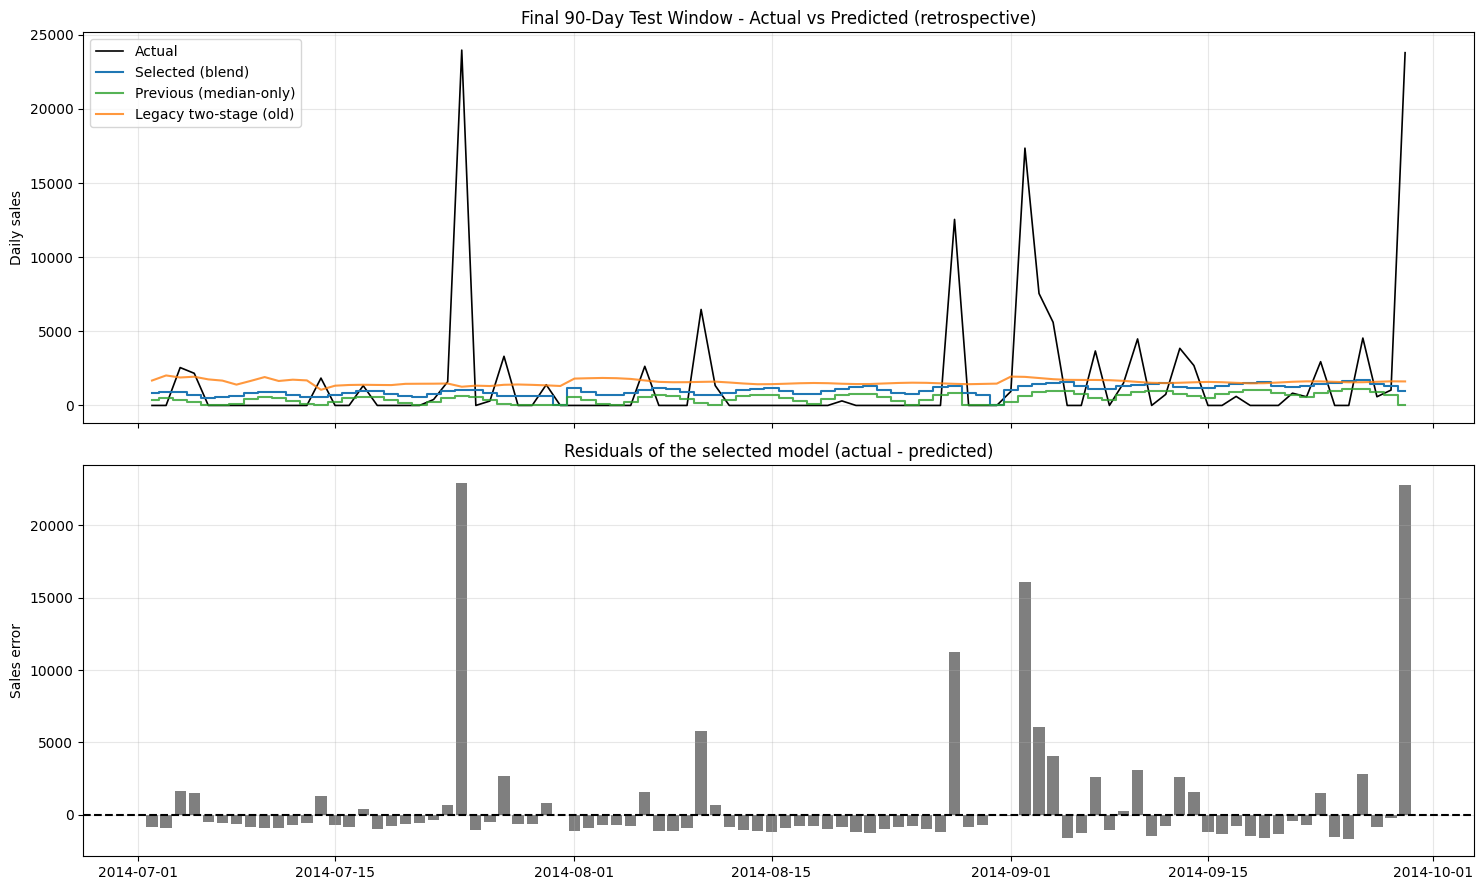

Residual summary:


,Residual
count,90.00
mean,610.82
std,4238.30
min,-1649.54
25%,-993.28
50%,-755.62
75%,172.58
max,22926.03


,Days,Abs_Error_Total,Share_of_Abs_Error_%
Actual zero-sales days,57,53879.9,31.0
Actual sales days,33,120160.9,69.0


The 5 largest actual-sales days account for 45.5% of the selected model's absolute error (spikes are not forecastable from this data).

Ten largest absolute errors:


,Actual,Predicted,Legacy_Predicted,Previous_Median,Residual,Absolute_Error
OrderDate,,,,,,
2014-07-24,23973.49,1047.45,1261.86,639.63,22926.03,22926.03
2014-09-29,23799.16,986.20,1620.40,0.00,22812.96,22812.96
2014-09-02,17358.92,1294.93,1927.30,630.44,16063.99,16063.99
2014-08-28,12551.31,1308.03,1457.79,814.85,11243.27,11243.27
2014-09-03,7551.28,1460.02,1849.57,912.99,6091.26,6091.26
2014-08-10,6475.58,708.87,1589.56,190.61,5766.70,5766.70
2014-09-04,5609.18,1530.81,1770.76,990.18,4078.37,4078.37
2014-09-10,4487.51,1384.35,1586.35,890.83,3103.16,3103.16
2014-09-26,4545.50,1744.11,1567.39,1122.59,2801.39,2801.39


Mean absolute error by weekday:


,Absolute_Error
OrderDate,
Friday,1303.0
Monday,2455.0
Saturday,1078.4
Sunday,1327.3
Thursday,3739.8
Tuesday,2090.8
Wednesday,1554.2


In [ ]:
import matplotlib.pyplot as plt
cmp_df = pd.DataFrame({"Actual": test_data.astype(float), "Predicted": selected_test_pred,
                       "Legacy_Predicted": legacy_test_forecast.to_numpy(), "Previous_Median": direct_test["median"]})
cmp_df["Residual"] = cmp_df["Actual"] - cmp_df["Predicted"]
cmp_df["Absolute_Error"] = cmp_df["Residual"].abs()

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
axes[0].plot(cmp_df.index, cmp_df["Actual"], label="Actual", color="black", lw=1.2)
axes[0].step(cmp_df.index, cmp_df["Predicted"], where="mid", label="Selected (blend)", color="tab:blue")
axes[0].step(cmp_df.index, cmp_df["Previous_Median"], where="mid", label="Previous (median-only)", color="tab:green", alpha=.8)
axes[0].plot(cmp_df.index, cmp_df["Legacy_Predicted"], label="Legacy two-stage (old)", color="tab:orange", alpha=.8)
axes[0].set_title("Final 90-Day Test Window - Actual vs Predicted (retrospective)"); axes[0].set_ylabel("Daily sales")
axes[0].legend(); axes[0].grid(True, alpha=.3)
axes[1].axhline(0, color="black", ls="--"); axes[1].bar(cmp_df.index, cmp_df["Residual"], color="tab:gray")
axes[1].set_title("Residuals of the selected model (actual - predicted)"); axes[1].set_ylabel("Sales error"); axes[1].grid(True, alpha=.3)
plt.tight_layout(); plt.show()

zero_mask = cmp_df["Actual"] == 0
print("Residual summary:"); display(cmp_df["Residual"].describe().to_frame("Residual").round(2))
grp = pd.DataFrame({
    "Days": [int(zero_mask.sum()), int((~zero_mask).sum())],
    "Abs_Error_Total": [cmp_df.loc[zero_mask, "Absolute_Error"].sum(), cmp_df.loc[~zero_mask, "Absolute_Error"].sum()],
}, index=["Actual zero-sales days", "Actual sales days"])
grp["Share_of_Abs_Error_%"] = grp["Abs_Error_Total"] / grp["Abs_Error_Total"].sum() * 100
display(grp.round(1))
top5_share = cmp_df.nlargest(5, "Actual")["Absolute_Error"].sum() / cmp_df["Absolute_Error"].sum() * 100
print(f"The 5 largest actual-sales days account for {top5_share:.1f}% of the selected model's absolute error (spikes are not forecastable from this data).")
print("\nTen largest absolute errors:"); display(cmp_df.nlargest(10, "Absolute_Error").round(2))
weekday_err = cmp_df.groupby(cmp_df.index.day_name())[["Absolute_Error"]].mean().round(1)
print("Mean absolute error by weekday:"); display(weekday_err)

## 19. Final Training / Prediction Section and 30-Day Forecast

The cell below is the reproducible train-and-predict path (data preparation -> training -> forecast). It only uses functions defined above, so it can later be moved into a module for an API. It is **not** an API. The forecast starts on the calendar day right after the last available date and uses direct multi-horizon features built from known history only (no future actuals, no recursive feedback).

Selected model family: Direct Two-Stage Median (WAPE-aligned)
Last available history date: 2014-09-29
Forecast range: 2014-09-30 to 2014-10-29 (30 days)
Sum of Predicted_Sales (median-style): 23,245.37
Sum of Median_Only_Forecast (previous model): 7,037.24
Sum of Expected_Sales_Mean (smeared, lambda=1 reference): 61,064.34
Days with a non-zero median-style forecast: 30 of 30


,Predicted_Sales,Median_Only_Forecast,Expected_Sales_Mean,Probability_of_Sale
Date,,,,
2014-09-30,581.59,0.00,1938.65,0.35
2014-10-01,994.13,456.30,2249.09,0.55
2014-10-02,1055.26,525.57,2291.22,0.56
2014-10-03,917.32,298.57,2361.06,0.53
2014-10-04,737.93,205.45,1980.39,0.52
2014-10-05,575.65,0.00,1918.83,0.49
2014-10-06,648.73,0.00,2162.43,0.45
2014-10-07,635.16,18.20,2074.75,0.50
2014-10-08,882.53,393.25,2024.21,0.55


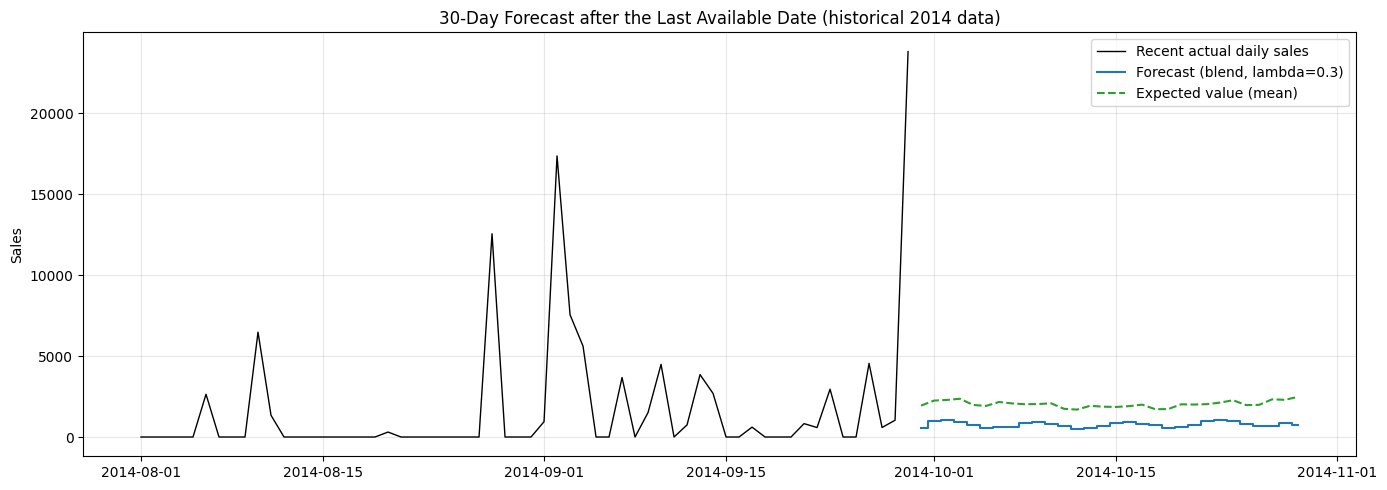


Pipeline smoke test (alignment/finite/non-negative checks, not a model-quality claim): forecast the last 30 known days from history that stops before them:
{'WAPE_percent': 97.01, 'MAE': 2695.97, 'RMSE': 5742.97, 'Total_Sales_Bias_percent': -87.01, 'Actual_Total': 83372.28, 'Predicted_Total': 10830.77}


In [ ]:
FORECAST_DAYS = 30

full_series = prepare_daily_series(df)
assert full_series.equals(daily_sales_complete.astype(float)), "Final pipeline must reproduce the exploratory daily series"
final_variant = model_to_key[selected_model_name]
final_models = train_final_models(full_series, with_hgb=(final_variant == "hgb_median"))
forecast_30 = forecast_next_days(full_series, final_models, FORECAST_DAYS, variant=final_variant, lam=BLEND_LAMBDA)
forecast_30["Predicted_Sales"] = forecast_30["Predicted_Sales"] * CAL_SCALE   # 1.0 unless adopted in Section 17b

# Output checks
assert forecast_30.index.min() == full_series.index.max() + pd.Timedelta(days=1)
assert len(forecast_30) == FORECAST_DAYS and forecast_30.index.is_monotonic_increasing
assert np.isfinite(forecast_30.to_numpy()).all() and (forecast_30 >= 0).all().all()

print("Selected model family:", selected_model_name)
print("Last available history date:", full_series.index.max().date())
print("Forecast range:", forecast_30.index.min().date(), "to", forecast_30.index.max().date(), f"({len(forecast_30)} days)")
print(f"Sum of Predicted_Sales (median-style): {forecast_30['Predicted_Sales'].sum():,.2f}")
print(f"Sum of Median_Only_Forecast (previous model): {forecast_30['Median_Only_Forecast'].sum():,.2f}")
print(f"Sum of Expected_Sales_Mean (smeared, lambda=1 reference): {forecast_30['Expected_Sales_Mean'].sum():,.2f}")
print(f"Days with a non-zero median-style forecast: {(forecast_30['Predicted_Sales'] > 0).sum()} of {len(forecast_30)}")
display(forecast_30.round(2))

fig, ax = plt.subplots(figsize=(14, 5))
hist_tail = full_series.iloc[-60:]
ax.plot(hist_tail.index, hist_tail.values, color="black", lw=1, label="Recent actual daily sales")
ax.step(forecast_30.index, forecast_30["Predicted_Sales"], where="mid", color="tab:blue", label=f"Forecast (blend, lambda={BLEND_LAMBDA})")
ax.plot(forecast_30.index, forecast_30["Expected_Sales_Mean"], color="tab:green", ls="--", label="Expected value (mean)")
ax.set_title("30-Day Forecast after the Last Available Date (historical 2014 data)"); ax.set_ylabel("Sales")
ax.legend(); ax.grid(True, alpha=.3); plt.tight_layout(); plt.show()

# Smoke test of the reproducible path on a truncated history (no future data used).
_trunc = full_series.iloc[:-30]
_fc = forecast_next_days(_trunc, train_final_models(_trunc, with_hgb=(final_variant == "hgb_median")), 30, variant=final_variant, lam=BLEND_LAMBDA)
_m = forecast_metrics(full_series.iloc[-30:], _fc["Predicted_Sales"])
print("\nPipeline smoke test (alignment/finite/non-negative checks, not a model-quality claim): forecast the last 30 known days from history that stops before them:")
print({k: round(v, 2) for k, v in _m.items()})

In [ ]:
# Final report: previous model vs best new model on the SAME dates, plus every evaluated candidate.
import joblib
cols = ["WAPE_percent", "MAE", "RMSE", "Total_Sales_Bias_percent"]
prev_test = pd.Series(forecast_metrics(test_data, direct_test["median"]))
new_test = pd.Series(forecast_metrics(test_data, selected_test_pred))
prev_val = blend_summary.loc["Blend lambda=0.0", cols]
new_val = blend_summary.loc[f"Blend lambda={BLEND_LAMBDA:.1f}", cols]
HIST = {"WAPE_percent": 106.32, "MAE": 1719.61, "RMSE": 4392.34, "Total_Sales_Bias_percent": -70.22}   # historical reference only
assert all(abs(prev_test[k] - v) < 0.05 for k, v in HIST.items()), "Recomputed previous model must match the historical reference"

def report_table(prev, new, title):
    t = pd.DataFrame({"Previous Model": prev[cols], "Best New Model": new[cols]})
    t.loc["Absolute_Bias_percent"] = [abs(prev["Total_Sales_Bias_percent"]), abs(new["Total_Sales_Bias_percent"])]
    t["Improvement (previous - new; positive = better)"] = t["Previous Model"] - t["Best New Model"]
    print(title); display(t.round(2))
report_table(prev_val, new_val, f"VALIDATION (mean of 5 chronological dev folds; model selected here), lambda={BLEND_LAMBDA}:")
report_table(prev_test, new_test, f"FINAL HOLDOUT {test_data.index.min().date()} to {test_data.index.max().date()} (retrospective, scored once, not used for selection):")
print("Holdout totals: actual {:,.0f} | previous predicted {:,.0f} | new predicted {:,.0f}".format(new_test["Actual_Total"], prev_test["Predicted_Total"], new_test["Predicted_Total"]))
hs = test_data.to_numpy() >= np.quantile(test_data.to_numpy()[test_data.to_numpy() > 0], 0.9)
print("High-sales days on holdout (top 10%% of positive days, n=%d): share of their sales forecast  previous %.1f%% | new %.1f%%" %
      (hs.sum(), direct_test["median"][hs].sum() / test_data.to_numpy()[hs].sum() * 100, selected_test_pred[hs].sum() / test_data.to_numpy()[hs].sum() * 100))
print("\nAll evaluated candidates - holdout metrics on identical dates:")
display(test_table.round(2))
print("All evaluated candidates - development metrics (5-fold mean):")
display(pd.concat([summary[["WAPE_percent", "MAE", "RMSE", "Total_Sales_Bias_percent"]], blend_summary[["WAPE_percent", "MAE", "RMSE", "Total_Sales_Bias_percent"]]]).round(2))

# Save the final model + settings, reload it, and check the reloaded model reproduces the forecast exactly.
artifact = {"models": final_models, "blend_lambda": BLEND_LAMBDA, "variant": final_variant, "max_horizon": MAX_HORIZON,
            "last_history_date": str(full_series.index.max().date()), "selected_model_name": selected_model_name}
joblib.dump(artifact, "final_sales_forecast_model.joblib")
_re = joblib.load("final_sales_forecast_model.joblib")
_chk = forecast_next_days(full_series, _re["models"], FORECAST_DAYS, variant=_re["variant"], lam=_re["blend_lambda"])
assert np.allclose(_chk["Predicted_Sales"], forecast_30["Predicted_Sales"]), "Reloaded model must match"
print("\nSaved model: final_sales_forecast_model.joblib (reload check passed)")

VALIDATION (mean of 5 chronological dev folds; model selected here), lambda=0.3:


,Previous Model,Best New Model,Improvement (previous - new; positive = better)
WAPE_percent,97.25,97.01,0.24
MAE,2107.94,2105.16,2.79
RMSE,4477.10,4297.38,179.72
Total_Sales_Bias_percent,-85.54,-63.02,-22.52
Absolute_Bias_percent,85.54,63.02,22.52


FINAL HOLDOUT 2014-07-02 to 2014-09-29 (retrospective, scored once, not used for selection):


,Previous Model,Best New Model,Improvement (previous - new; positive = better)
WAPE_percent,106.32,119.56,-13.24
MAE,1719.61,1933.79,-214.17
RMSE,4392.34,4258.72,133.63
Total_Sales_Bias_percent,-70.22,-37.76,-32.46
Absolute_Bias_percent,70.22,37.76,32.46


Holdout totals: actual 145,571 | previous predicted 43,352 | new predicted 90,597
High-sales days on holdout (top 10% of positive days, n=4): share of their sales forecast  previous 2.7% | new 6.0%

All evaluated candidates - holdout metrics on identical dates:


,WAPE_percent,MAE,RMSE,Total_Sales_Bias_percent,Actual_Total,Predicted_Total
Two-Stage Log Ridge - Full History (legacy selected),138.80,2245.11,4249.19,-2.96,145571.42,141258.20
Always Zero (reference only),100.00,1617.46,4549.85,-100.00,145571.42,0.00
Previous model: Direct Two-Stage Median (lambda=0),106.32,1719.61,4392.34,-70.22,145571.42,43351.90
"Smeared expected value (lambda=1, reference)",159.76,2584.13,4210.26,37.96,145571.42,200836.70
SELECTED: Direct Two-Stage Median (WAPE-aligned) (lambda=0.3),119.56,1933.79,4258.72,-37.76,145571.42,90597.34


All evaluated candidates - development metrics (5-fold mean):


,WAPE_percent,MAE,RMSE,Total_Sales_Bias_percent
Model,,,,
Constant Recent-90-Day Median,96.66,2098.29,4347.15,-70.42
Direct Two-Stage Median (WAPE-aligned),97.25,2107.94,4477.10,-85.54
Two-Stage Log Ridge - Full History (legacy),98.75,2144.37,4211.84,-45.06
Direct Two-Stage Expected Value (mean),99.74,2164.93,4229.49,-49.48
Always Zero (reference only),100.00,2166.61,4603.00,-100.00
Direct HistGB Quantile-50,101.65,2202.07,4487.32,-83.69
Recent 365-Day Weekday Mean,105.55,2284.84,4118.03,-19.70
Weekly Seasonal Naive (Lag 7),230.15,4982.35,9329.10,95.31
Blend lambda=0.0,97.25,2107.94,4477.10,-85.54



Saved model: final_sales_forecast_model.joblib (reload check passed)


In [ ]:
print("CONCLUSION (all numbers above were computed in this run)")
print("-" * 70)
print("Root cause : (1) a median-type forecast on mostly-zero, spike-heavy data under-forecasts totals by design;")
print(f"             (2) the log model's expm1 gives a geometric mean - arithmetic/geometric ratio about {np.mean([fold_parts[f]['smear_factor'] for f in fold_parts]):.2f};")
print("             (3) the biggest sales days are largely unpredictable from calendar/history features.")
print(f"Change     : forecast = (1-lambda) x median + lambda x smeared mean, lambda = {BLEND_LAMBDA} chosen on development folds with a WAPE non-inferiority rule.")
print(f"Validation : WAPE {prev_val['WAPE_percent']:.2f}% -> {new_val['WAPE_percent']:.2f}% | bias {prev_val['Total_Sales_Bias_percent']:.2f}% -> {new_val['Total_Sales_Bias_percent']:.2f}%")
print(f"Holdout    : WAPE {prev_test['WAPE_percent']:.2f}% -> {new_test['WAPE_percent']:.2f}% | MAE {prev_test['MAE']:.1f} -> {new_test['MAE']:.1f} | RMSE {prev_test['RMSE']:.1f} -> {new_test['RMSE']:.1f} | bias {prev_test['Total_Sales_Bias_percent']:.2f}% -> {new_test['Total_Sales_Bias_percent']:.2f}%")
print("Trade-off  : lowering the bias raises day-level error on the quiet holdout window (fewer sales days than the year before); a forecast near zero every day scores WAPE 100% but is useless for totals.")
print("Weakness   : individual spike days stay unpredictable; the 2014 holdout was visible earlier, so its scores are retrospective.")

CONCLUSION (all numbers above were computed in this run)
----------------------------------------------------------------------
Root cause : (1) a median-type forecast on mostly-zero, spike-heavy data under-forecasts totals by design;
             (2) the log model's expm1 gives a geometric mean - arithmetic/geometric ratio about 1.78;
             (3) the biggest sales days are largely unpredictable from calendar/history features.
Change     : forecast = (1-lambda) x median + lambda x smeared mean, lambda = 0.3 chosen on development folds with a WAPE non-inferiority rule.
Validation : WAPE 97.25% -> 97.01% | bias -85.54% -> -63.02%
Holdout    : WAPE 106.32% -> 119.56% | MAE 1719.6 -> 1933.8 | RMSE 4392.3 -> 4258.7 | bias -70.22% -> -37.76%
Trade-off  : lowering the bias raises day-level error on the quiet holdout window (fewer sales days than the year before); a forecast near zero every day scores WAPE 100% but is useless for totals.
Weakness   : individual spike days stay unpredictab

## 20. Limitations

The dataset ends in September 2014, so any forecast produced from it is historical. The available fields contain no future promotions, inventory, closures, or events, and isolated spikes (a handful of days carry a large share of all sales) cannot be forecast from calendar and history features alone. The 2014 test window was already displayed in earlier saved outputs, so its metrics are retrospective, not an independent holdout. See the conclusion in Section 19 for the numerical results produced by this run.